# UNSW-NB15 — Multiclass Network Intrusion Detection
### Original vs SMOTE vs GAN oversampling (combined notebook)

This notebook merges
- `UNSW-NB15_multiclass-classification-complete.ipynb` (data prep, SMOTE, tuning, SHAP, evaluation, saving), and
- `UNSW-NB15_GAN_oversampling_and_classification.ipynb` (WGAN-GP oversampling + GAN-based classification)

into one 29-step pipeline. The GAN part, originally written for a *binary* problem with a single minority class, is generalised to the **10-class** target: one WGAN-GP is trained per minority class.

**Target classes:** `Normal, Generic, Exploits, Fuzzers, DoS, Reconnaissance, Analysis, Backdoor, Shellcode, Worms`

| # | Stage | # | Stage |
|---|---|---|---|
| 01 | Import libraries | 16 | SMOTE baseline |
| 02 | Load train / test data | 17 | GAN oversampling |
| 03 | Verify dataset structure | 18 | GAN-based classification |
| 04 | Dataset overview | 19 | Hyperparameter tuning |
| 05 | Data quality | 20 | Ensemble classification |
| 06 | Exploratory data analysis | 21 | Feature importance |
| 07 | Define multiclass target | 22 | SHAP explainability |
| 08 | X / y separation | 23 | Multiclass evaluation |
| 09 | Identify data types | 24 | Per-class evaluation |
| 10 | Encode categorical features | 25 | Original vs SMOTE vs GAN |
| 11 | Train / validation split | 26 | Final evaluation on test set |
| 12 | Feature scaling | 27 | Model comparison & selection |
| 13 | Class-imbalance analysis | 28 | Save final model |
| 14 | Feature selection | 29 | Final results & conclusion |
| 15 | Baseline — original data | | |

**Three training-set strategies, one validation/test protocol**

| Strategy | Training data | Steps |
|---|---|---|
| **Original** | imbalanced training split | 15 |
| **SMOTE** | classes below `SMOTE_TARGET` rows lifted to `SMOTE_TARGET` by SMOTE | 16 |
| **GAN** | the *same* classes lifted to the *same* `GAN_TARGET` rows by per-class WGAN-GP | 17-18 |

SMOTE and GAN use the same target size, so the comparison in Step 25 changes only *how* the synthetic rows are made. Validation and test data are never resampled, and the test set is never used to choose a model.

## 01. Import Libraries

In [1]:
# Run once if a package is missing:
# !pip install pyarrow imbalanced-learn xgboost lightgbm shap seaborn scikit-learn joblib torch

In [2]:
import json
import math
import os
import warnings
from collections import Counter
from functools import partial
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier, VotingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import (
    GridSearchCV,
    RandomizedSearchCV,
    StratifiedKFold,
    cross_val_score,
    train_test_split,
)
from sklearn.preprocessing import LabelEncoder, StandardScaler, label_binarize
from sklearn.tree import DecisionTreeClassifier

from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
from lightgbm import LGBMClassifier
from xgboost import XGBClassifier

import torch
import torch.nn as nn
import torch.optim as optim

import joblib
import shap

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
torch.manual_seed(RANDOM_STATE)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 60)
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)
print("Torch device:", device)

Torch device: cpu


e:\BRM003-ML-Project\brmenv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 02. Load UNSW-NB15 Training & Testing Data

In [3]:
# Set the UNSW_DATA_DIR environment variable to override the default folder.
DATA_DIR = Path(os.environ.get("UNSW_DATA_DIR", r"E:\BRM003-ML-Project\dataset folder\archive (1)"))

train_path = DATA_DIR / "UNSW_NB15_training-set.parquet"
test_candidates = [
    DATA_DIR / "UNSW_NB15_test-set.parquet",
    DATA_DIR / "UNSW_NB15_testing-set.parquet",
    DATA_DIR / "UNSW_NB15_test-set.csv",
    DATA_DIR / "UNSW_NB15_testing-set.csv",
]
test_path = next((p for p in test_candidates if p.exists()), None)
if test_path is None:
    raise FileNotFoundError(f"No UNSW-NB15 test file found in {DATA_DIR}")

def read_any(path):
    return pd.read_parquet(path) if path.suffix == ".parquet" else pd.read_csv(path)

train_df = read_any(train_path)
test_df = read_any(test_path)

print("Train file:", train_path.name, train_df.shape)
print("Test file :", test_path.name, test_df.shape)

Train file: UNSW_NB15_training-set.parquet (175341, 36)
Test file : UNSW_NB15_testing-set.parquet (82332, 36)


## 03. Verify Dataset Structure

The official train and test files are kept **separate** for modelling (the test file is the held-out set). Here we only check that they line up, make their dtypes consistent, and compare them side by side.

Categorical columns arrive as pandas `category` with *different category lists* in train and test (e.g. `state`), so they are converted to plain strings — this also makes one-hot alignment in Step 10 straightforward.

In [4]:
train_cols, test_cols = set(train_df.columns), set(test_df.columns)
print("Columns only in train:", train_cols - test_cols)
print("Columns only in test :", test_cols - train_cols)
print("Column count — train:", train_df.shape[1], "| test:", test_df.shape[1])

Columns only in train: set()
Columns only in test : set()
Column count — train: 36 | test: 36


In [5]:
TARGET_COL, BINARY_COL, ID_COL = "attack_cat", "label", "id"

def harmonise(df):
    df = df.copy()
    for c in df.columns:
        if not pd.api.types.is_numeric_dtype(df[c]):
            df[c] = df[c].astype(str).str.strip()
    # tidy attack labels ('Backdoors' -> 'Backdoor', missing -> 'Normal')
    df[TARGET_COL] = df[TARGET_COL].replace({"Backdoors": "Backdoor", "nan": "Normal", "": "Normal", "-": "Normal"})
    return df

train_df = harmonise(train_df)
test_df = harmonise(test_df)

dtype_mismatch = {c: (str(train_df[c].dtype), str(test_df[c].dtype))
                  for c in train_cols & test_cols if str(train_df[c].dtype) != str(test_df[c].dtype)}
print("Dtype mismatches after harmonising:", dtype_mismatch or "None")
print("'id' column present:", ID_COL in train_df.columns)

Dtype mismatches after harmonising: None
'id' column present: False


In [6]:
# Side-by-side class distribution of the two official splits
dist = pd.concat(
    [train_df[TARGET_COL].value_counts().rename("train"), test_df[TARGET_COL].value_counts().rename("test")], axis=1
).fillna(0).astype(int)
dist["train_%"] = (dist["train"] / dist["train"].sum() * 100).round(2)
dist["test_%"] = (dist["test"] / dist["test"].sum() * 100).round(2)
print("Classes only in one split:", set(train_df[TARGET_COL]) ^ set(test_df[TARGET_COL]) or "None")
dist

Classes only in one split: None


,train,test,train_%,test_%
attack_cat,,,,
Normal,56000,37000,31.94,44.94
Generic,40000,18871,22.81,22.92
Exploits,33393,11132,19.04,13.52
Fuzzers,18184,6062,10.37,7.36
DoS,12264,4089,6.99,4.97
Reconnaissance,10491,3496,5.98,4.25
Analysis,2000,677,1.14,0.82
Backdoor,1746,583,1.00,0.71
Shellcode,1133,378,0.65,0.46


## 04. Dataset Overview

### 04.1 Shape

In [7]:
print("train shape:", train_df.shape, "| test shape:", test_df.shape)

train shape: (175341, 36) | test shape: (82332, 36)


### 04.2 `head()`

In [8]:
train_df.head()

,dur,proto,service,state,spkts,dpkts,sbytes,dbytes,rate,sload,dload,sloss,dloss,sinpkt,dinpkt,sjit,djit,swin,stcpb,dtcpb,dwin,tcprtt,synack,ackdat,smean,dmean,trans_depth,response_body_len,ct_src_dport_ltm,ct_dst_sport_ltm,is_ftp_login,ct_ftp_cmd,ct_flw_http_mthd,is_sm_ips_ports,attack_cat,label
0,0.121478,tcp,-,FIN,6,4,258,172,74.087486,14158.942383,8495.365234,0,0,24.295601,8.375000,30.177547,11.830604,255,621772692,2202533631,255,0.000000,0.000000,0.000000,43,43,0,0,1,1,0,0,0,0,Normal,0
1,0.649902,tcp,-,FIN,14,38,734,42014,78.473373,8395.112305,503571.312500,2,17,49.915001,15.432865,61.426933,1387.778320,255,1417884146,3077387971,255,0.000000,0.000000,0.000000,52,1106,0,0,1,1,0,0,0,0,Normal,0
2,1.623129,tcp,-,FIN,8,16,364,13186,14.170161,1572.271851,60929.230469,1,6,231.875565,102.737206,17179.585938,11420.925781,255,2116150707,2963114973,255,0.111897,0.061458,0.050439,46,824,0,0,1,1,0,0,0,0,Normal,0
3,1.681642,tcp,ftp,FIN,12,12,628,770,13.677108,2740.178955,3358.622070,1,3,152.876541,90.235725,259.080170,4991.784668,255,1107119177,1047442890,255,0.000000,0.000000,0.000000,52,64,0,0,1,1,1,1,0,0,Normal,0
4,0.449454,tcp,-,FIN,10,6,534,268,33.373825,8561.499023,3987.059814,2,1,47.750332,75.659599,2415.837646,115.806999,255,2436137549,1977154190,255,0.128381,0.071147,0.057234,53,45,0,0,2,1,0,0,0,0,Normal,0


In [9]:
test_df.head()

,dur,proto,service,state,spkts,dpkts,sbytes,dbytes,rate,sload,dload,sloss,dloss,sinpkt,dinpkt,sjit,djit,swin,stcpb,dtcpb,dwin,tcprtt,synack,ackdat,smean,dmean,trans_depth,response_body_len,ct_src_dport_ltm,ct_dst_sport_ltm,is_ftp_login,ct_ftp_cmd,ct_flw_http_mthd,is_sm_ips_ports,attack_cat,label
0,0.000011,udp,-,INT,2,0,496,0,90909.09375,180363632.0,0.0,0,0,0.011,0.0,0.0,0.0,0,0,0,0,0.0,0.0,0.0,248,0,0,0,1,1,0,0,0,0,Normal,0
1,0.000008,udp,-,INT,2,0,1762,0,125000.00000,881000000.0,0.0,0,0,0.008,0.0,0.0,0.0,0,0,0,0,0.0,0.0,0.0,881,0,0,0,1,1,0,0,0,0,Normal,0
2,0.000005,udp,-,INT,2,0,1068,0,200000.00000,854400000.0,0.0,0,0,0.005,0.0,0.0,0.0,0,0,0,0,0.0,0.0,0.0,534,0,0,0,1,1,0,0,0,0,Normal,0
3,0.000006,udp,-,INT,2,0,900,0,166666.65625,600000000.0,0.0,0,0,0.006,0.0,0.0,0.0,0,0,0,0,0.0,0.0,0.0,450,0,0,0,2,1,0,0,0,0,Normal,0
4,0.000010,udp,-,INT,2,0,2126,0,100000.00000,850400000.0,0.0,0,0,0.010,0.0,0.0,0.0,0,0,0,0,0.0,0.0,0.0,1063,0,0,0,2,1,0,0,0,0,Normal,0


### 04.3 `info()`

In [10]:
train_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 175341 entries, 0 to 175340
Data columns (total 36 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   dur                175341 non-null  float32
 1   proto              175341 non-null  str    
 2   service            175341 non-null  str    
 3   state              175341 non-null  str    
 4   spkts              175341 non-null  int16  
 5   dpkts              175341 non-null  int16  
 6   sbytes             175341 non-null  int32  
 7   dbytes             175341 non-null  int32  
 8   rate               175341 non-null  float32
 9   sload              175341 non-null  float32
 10  dload              175341 non-null  float32
 11  sloss              175341 non-null  int16  
 12  dloss              175341 non-null  int16  
 13  sinpkt             175341 non-null  float32
 14  dinpkt             175341 non-null  float32
 15  sjit               175341 non-null  float32
 16  djit         

### 04.4 `describe()`

In [11]:
train_df.describe().T

,count,mean,std,min,25%,50%,75%,max
dur,175341.0,1.359389e+00,6.480249e+00,0.0,0.000008,0.001582,6.680690e-01,5.999999e+01
spkts,175341.0,2.029866e+01,1.368876e+02,1.0,2.000000,2.000000,1.200000e+01,9.616000e+03
dpkts,175341.0,1.896959e+01,1.102583e+02,0.0,0.000000,2.000000,1.000000e+01,1.097400e+04
sbytes,175341.0,8.844844e+03,1.747656e+05,28.0,114.000000,430.000000,1.418000e+03,1.296523e+07
dbytes,175341.0,1.492892e+04,1.436542e+05,0.0,0.000000,164.000000,1.102000e+03,1.465555e+07
rate,175341.0,9.540618e+04,1.654010e+05,0.0,32.786140,3225.806641,1.250000e+05,1.000000e+06
sload,175341.0,7.345403e+07,1.883574e+08,0.0,13053.338867,879674.750000,8.888889e+07,5.988000e+09
dload,175341.0,6.712056e+05,2.421312e+06,0.0,0.000000,1447.022705,2.784487e+04,2.242273e+07
sloss,175341.0,4.953000e+00,6.600506e+01,0.0,0.000000,0.000000,3.000000e+00,4.803000e+03
dloss,175341.0,6.948010e+00,5.273300e+01,0.0,0.000000,0.000000,2.000000e+00,5.484000e+03


### 04.5 `dtypes`

In [12]:
train_df.dtypes.value_counts()

float32    11
int16       9
int8        7
str         4
int32       3
int64       2
Name: count, dtype: int64

## 05. Data Quality

### 05.1 Missing values

In [13]:
missing = pd.DataFrame({"train": train_df.isnull().sum(), "test": test_df.isnull().sum()})
missing[(missing > 0).any(axis=1)] if (missing > 0).any().any() else print("No missing values in train or test.")

No missing values in train or test.


### 05.2 Duplicates

UNSW-NB15 contains a very large number of exact duplicate flows (over 40 % of the training file), concentrated in a few classes.
They are dropped **from the training set only** — duplicates inflate scores when copies of the same row land in both train and validation.
The test set is left untouched so it stays comparable with published results. Set `DROP_DUPLICATES = False` to keep them.

In [14]:
DROP_DUPLICATES = True

dup_mask = train_df.drop(columns=[ID_COL], errors="ignore").duplicated()
print(f"Duplicate rows in train: {dup_mask.sum()} ({dup_mask.mean():.1%}) | in test (not removed): "
      f"{test_df.drop(columns=[ID_COL], errors='ignore').duplicated().sum()}")
print("\nDuplicates by class:")
print(pd.concat([train_df.loc[dup_mask, TARGET_COL].value_counts().rename("duplicates"),
                 train_df[TARGET_COL].value_counts().rename("total")], axis=1).fillna(0).astype(int))

if DROP_DUPLICATES:
    before = len(train_df)
    train_df = train_df.loc[~dup_mask].reset_index(drop=True)
    print(f"\nDropped {before - len(train_df)} duplicate rows ({before} -> {len(train_df)})")

Duplicate rows in train: 78519 (44.8%) | in test (not removed): 32361

Duplicates by class:
                duplicates  total
attack_cat                       
Generic              38200  40000
Exploits             14033  33393
DoS                   8895  12264
Normal                7106  56000
Reconnaissance        4491  10491
Fuzzers               4102  18184
Analysis               881   2000
Backdoor               625   1746
Shellcode              179   1133
Worms                    7    130

Dropped 78519 duplicate rows (175341 -> 96822)


### 05.3 Infinite values

In [15]:
numeric_cols_all = [c for c in train_df.columns if pd.api.types.is_numeric_dtype(train_df[c]) and c not in (BINARY_COL, ID_COL)]

inf_train = np.isinf(train_df[numeric_cols_all]).sum()
inf_test = np.isinf(test_df[numeric_cols_all]).sum()
print("Infinite values — train:", int(inf_train.sum()), "| test:", int(inf_test.sum()))

# Replace inf with NaN and fill with TRAIN medians (never test statistics -> no leakage). No-op if nothing is found.
train_medians = train_df[numeric_cols_all].replace([np.inf, -np.inf], np.nan).median()
for df in (train_df, test_df):
    df[numeric_cols_all] = df[numeric_cols_all].replace([np.inf, -np.inf], np.nan).fillna(train_medians)

Infinite values — train: 0 | test: 0


### 05.4 Invalid / inconsistent values

In [16]:
neg = (train_df[numeric_cols_all] < 0).sum()
print("Numeric columns with negative values:", neg[neg > 0].to_dict() or "None")

flag_cols = [c for c in ["is_sm_ips_ports", "is_ftp_login"] if c in train_df.columns]
for c in flag_cols:
    print(f"{c} unique values:", sorted(train_df[c].unique()))

print("\nlabel vs attack_cat consistency (label should be 0 exactly when attack_cat == 'Normal'):")
print(pd.crosstab(train_df[BINARY_COL], train_df[TARGET_COL] == "Normal", rownames=["label"], colnames=["is Normal"]))

Numeric columns with negative values: None
is_sm_ips_ports unique values: [np.int8(0), np.int8(1)]
is_ftp_login unique values: [np.int8(0), np.int8(1), np.int8(2), np.int8(4)]

label vs attack_cat consistency (label should be 0 exactly when attack_cat == 'Normal'):
is Normal  False  True 
label                  
0              0  48894
1          47928      0


## 06. Exploratory Data Analysis

### 06.1 Attack category distribution

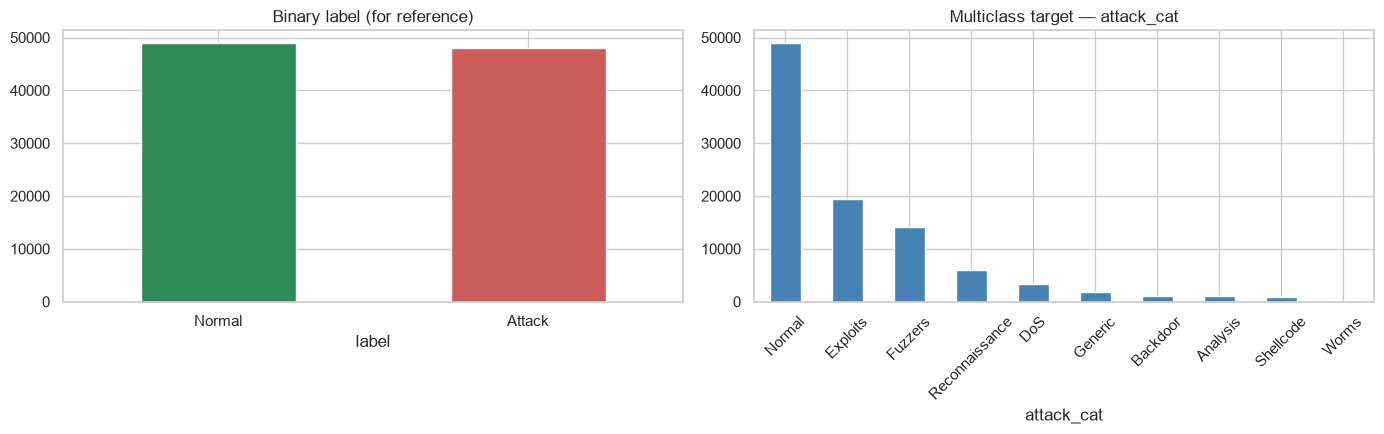

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

train_df[BINARY_COL].map({0: "Normal", 1: "Attack"}).value_counts().plot(
    kind="bar", ax=axes[0], color=["seagreen", "indianred"])
axes[0].set_title("Binary label (for reference)")
axes[0].tick_params(axis="x", rotation=0)

train_df[TARGET_COL].value_counts().plot(kind="bar", ax=axes[1], color="steelblue")
axes[1].set_title("Multiclass target — attack_cat")
axes[1].tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.show()

In [18]:
cat_counts = train_df[TARGET_COL].value_counts()
pd.DataFrame({"count": cat_counts, "percent": (cat_counts / cat_counts.sum() * 100).round(2)})

,count,percent
attack_cat,,
Normal,48894,50.50
Exploits,19360,20.00
Fuzzers,14082,14.54
Reconnaissance,6000,6.20
DoS,3369,3.48
Generic,1800,1.86
Backdoor,1121,1.16
Analysis,1119,1.16
Shellcode,954,0.99


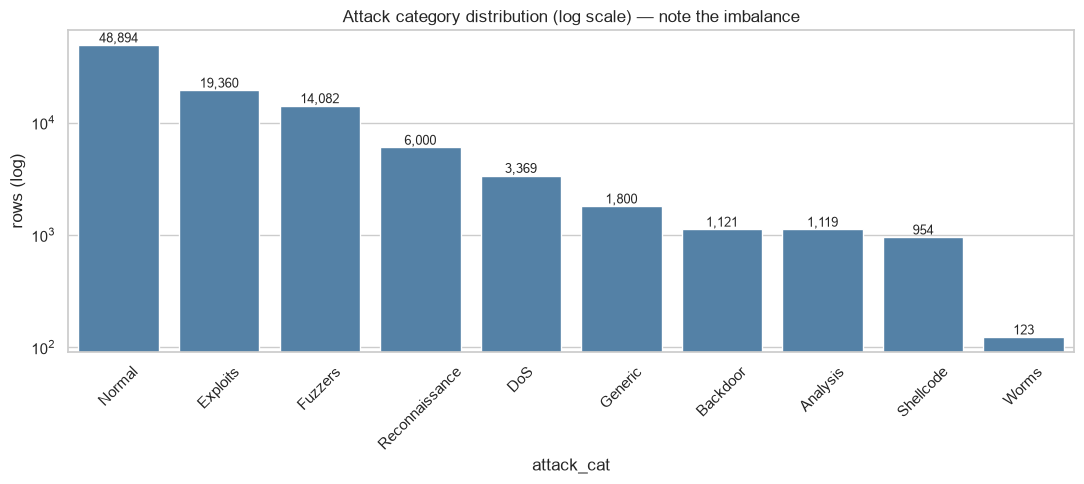

In [19]:
plt.figure(figsize=(11, 5))
ax = sns.barplot(x=cat_counts.index, y=cat_counts.values, color="steelblue")
ax.set_yscale("log")
ax.set_title("Attack category distribution (log scale) — note the imbalance")
ax.set_ylabel("rows (log)")
for i, v in enumerate(cat_counts.values):
    ax.text(i, v, f"{v:,}", ha="center", va="bottom", fontsize=9)
plt.xticks(rotation=45); plt.tight_layout(); plt.show()

### 06.2 Categorical features

Categorical features: ['proto', 'service', 'state']


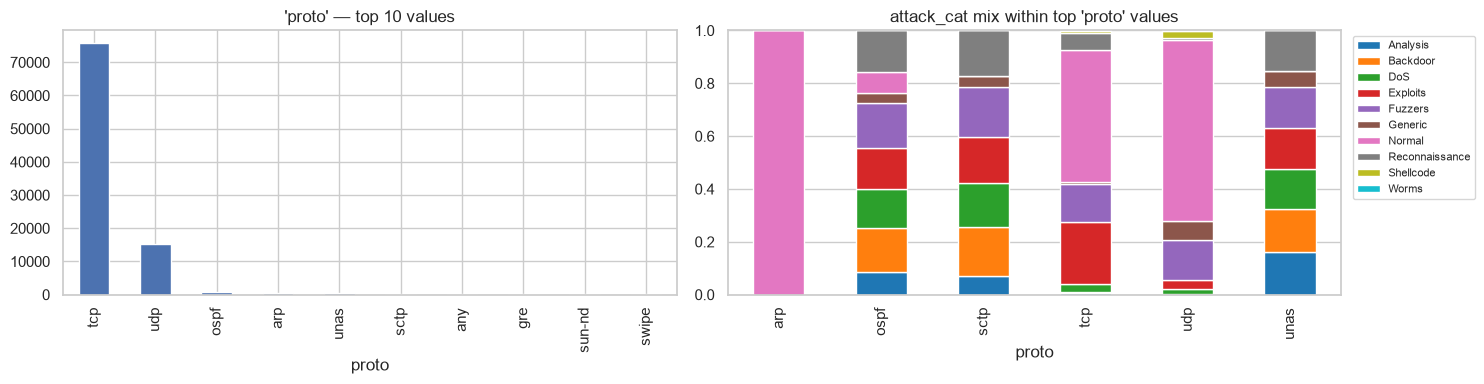

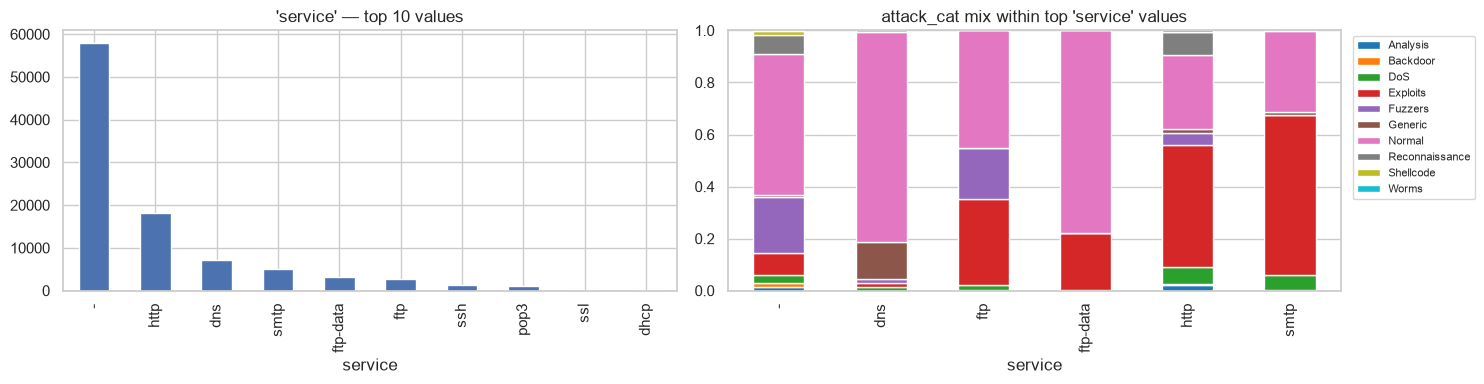

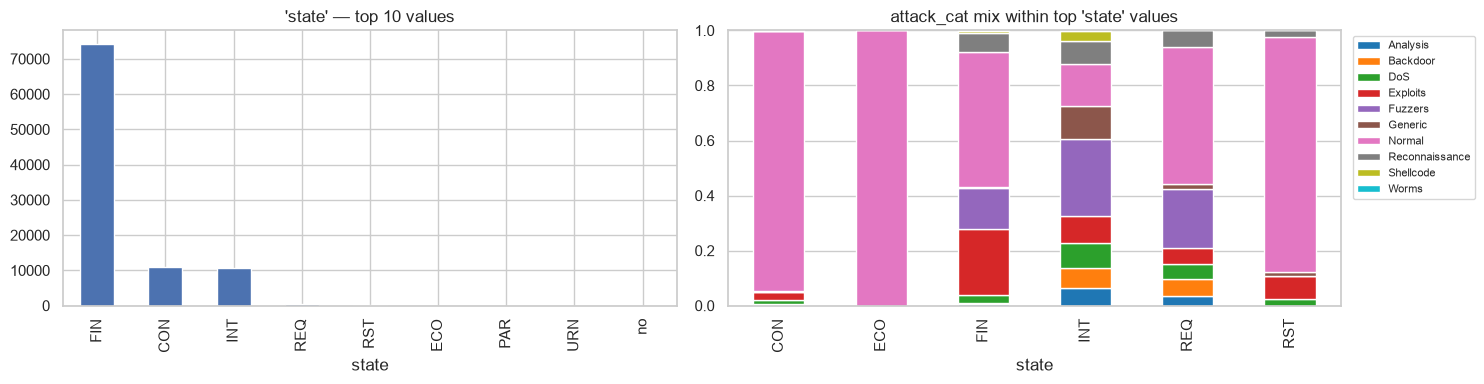

In [20]:
categorical_preview_cols = [c for c in train_df.columns
                            if not pd.api.types.is_numeric_dtype(train_df[c]) and c != TARGET_COL]
print("Categorical features:", categorical_preview_cols)

for col in categorical_preview_cols:
    fig, axes = plt.subplots(1, 2, figsize=(15, 4))
    train_df[col].value_counts().head(10).plot(kind="bar", ax=axes[0], title=f"'{col}' — top 10 values")
    top = train_df[col].value_counts().head(6).index
    (pd.crosstab(train_df.loc[train_df[col].isin(top), col], train_df[TARGET_COL], normalize="index")
       .plot(kind="bar", stacked=True, ax=axes[1], colormap="tab10", title=f"attack_cat mix within top '{col}' values"))
    axes[1].legend(bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=8)
    plt.tight_layout(); plt.show()

### 06.3 Numerical features

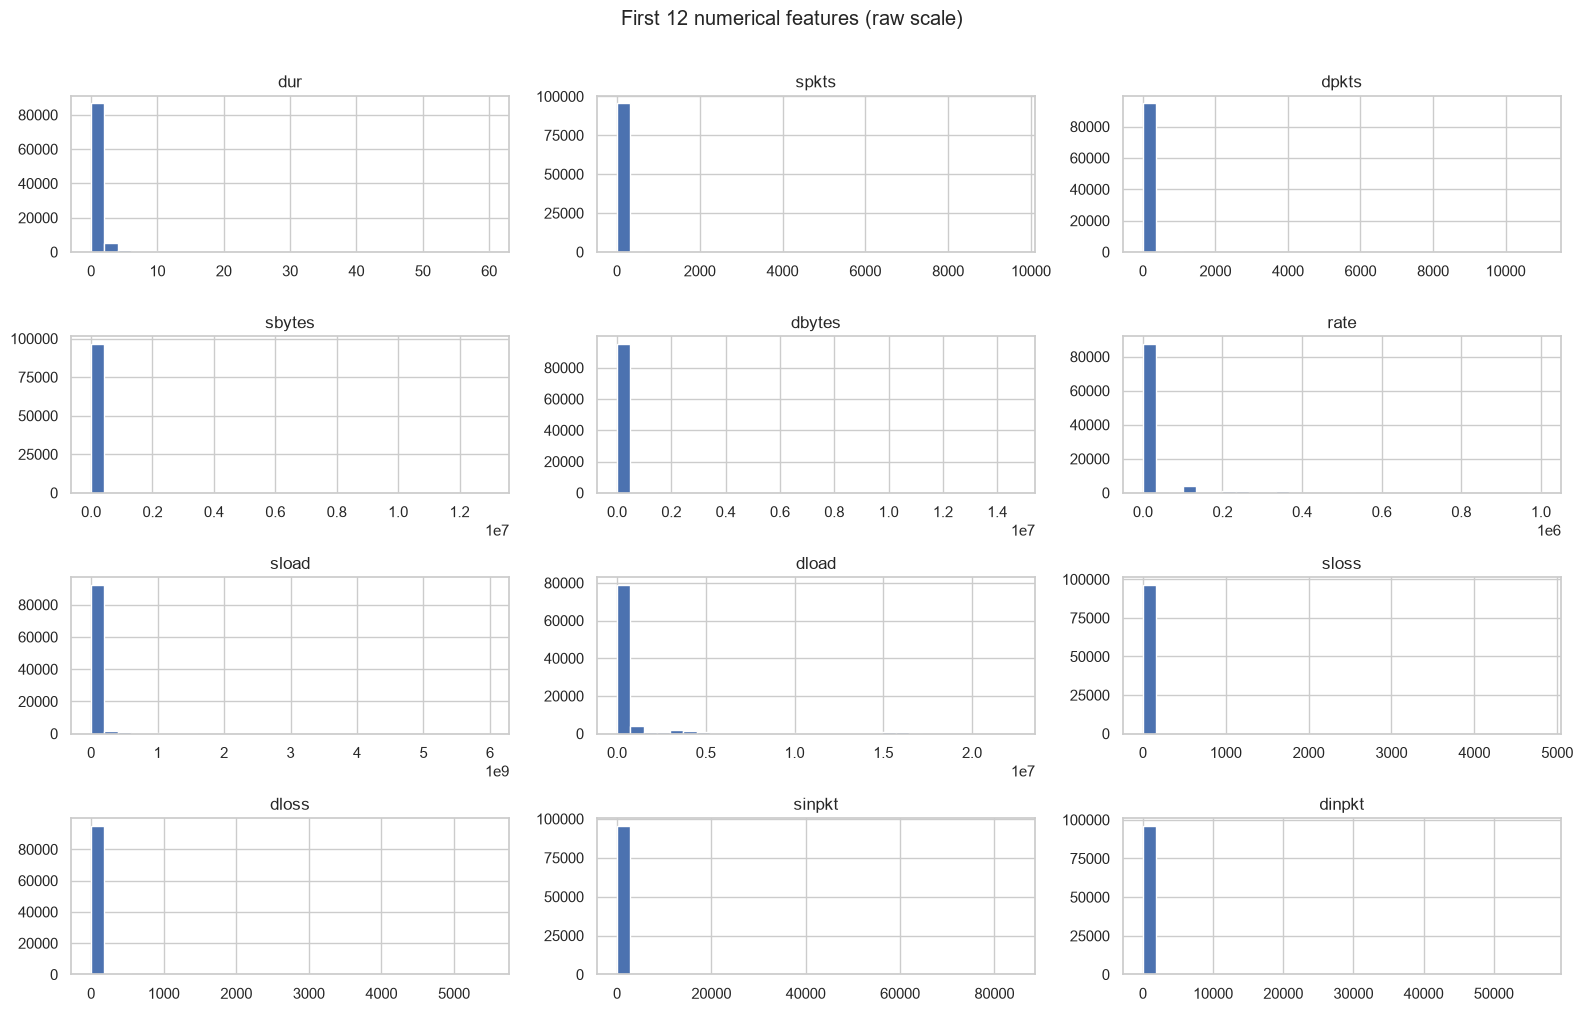

In [21]:
numerical_preview_cols = [c for c in numeric_cols_all if c != ID_COL][:12]
train_df[numerical_preview_cols].hist(figsize=(16, 10), bins=30)
plt.suptitle("First 12 numerical features (raw scale)", y=1.01); plt.tight_layout(); plt.show()

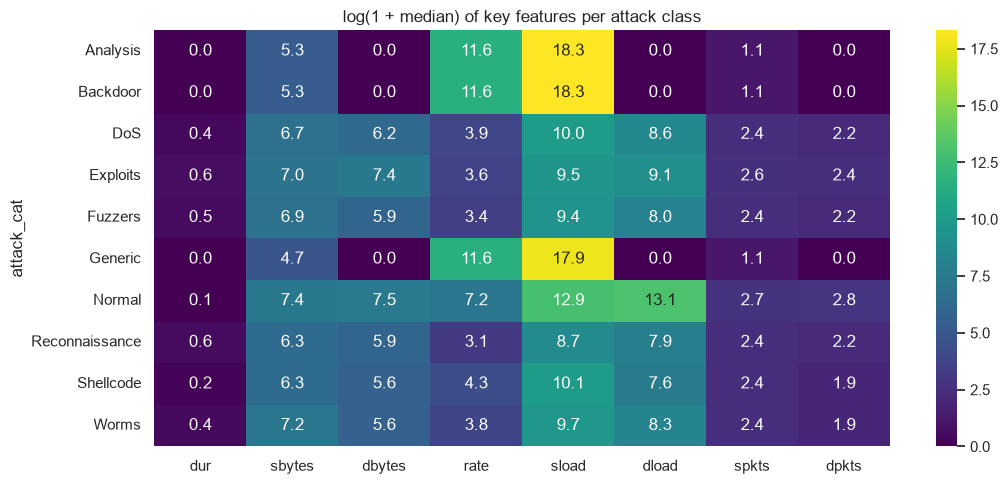

In [22]:
# Heavy right skew is typical for flow features -> compare class medians on a log scale for a few key ones
key_cols = [c for c in ["dur", "sbytes", "dbytes", "rate", "sload", "dload", "spkts", "dpkts"] if c in train_df.columns]
medians = train_df.groupby(TARGET_COL)[key_cols].median()
plt.figure(figsize=(11, 5))
sns.heatmap(np.log1p(medians), annot=True, fmt=".1f", cmap="viridis")
plt.title("log(1 + median) of key features per attack class"); plt.tight_layout(); plt.show()

## 07. Define Multiclass Target

| Task | Target | Classes |
|---|---|---|
| Binary | `label` | Normal (0) vs Attack (1) |
| **Multiclass (this notebook)** | `attack_cat` | Normal + 9 attack categories |

The binary `label` is kept only for the sanity check in Step 05. Every model is trained on `attack_cat`.

In [23]:
y_binary = train_df[BINARY_COL]        # reference only
y_multi = train_df[TARGET_COL]         # <- modelling target

y_test_binary = test_df[BINARY_COL]
y_test_multi = test_df[TARGET_COL]

# Reporting order used in the per-class sections (Step 24)
OUTLINE_ORDER = ["Normal", "Generic", "Exploits", "Fuzzers", "DoS", "Reconnaissance",
                 "Analysis", "Backdoor", "Shellcode", "Worms"]
class_order = [c for c in OUTLINE_ORDER if c in set(y_multi)] + sorted(set(y_multi) - set(OUTLINE_ORDER))

print("Number of classes:", y_multi.nunique())
print("Reporting order  :", class_order)

Number of classes: 10
Reporting order  : ['Normal', 'Generic', 'Exploits', 'Fuzzers', 'DoS', 'Reconnaissance', 'Analysis', 'Backdoor', 'Shellcode', 'Worms']


## 08. X / y Separation

In [24]:
drop_cols = [c for c in [ID_COL, TARGET_COL, BINARY_COL] if c in train_df.columns]

X = train_df.drop(columns=drop_cols)          # X = network features
y = y_multi.copy()                            # y = attack category

X_test_raw = test_df.drop(columns=[c for c in drop_cols if c in test_df.columns])
y_test = y_test_multi.copy()

# Both must have identical feature columns in identical order
X_test_raw = X_test_raw[X.columns]
print("X:", X.shape, "| X_test_raw:", X_test_raw.shape)

X: (96822, 34) | X_test_raw: (82332, 34)


## 09. Identify Data Types

In [25]:
categorical_cols = [c for c in X.columns if not pd.api.types.is_numeric_dtype(X[c])]
numerical_cols = [c for c in X.columns if pd.api.types.is_numeric_dtype(X[c])]

print(f"Categorical ({len(categorical_cols)}):", categorical_cols)
print(f"Numerical   ({len(numerical_cols)}):", numerical_cols)
print()
print({c: X[c].nunique() for c in categorical_cols}, "<- unique values per categorical column")

Categorical (3): ['proto', 'service', 'state']
Numerical   (31): ['dur', 'spkts', 'dpkts', 'sbytes', 'dbytes', 'rate', 'sload', 'dload', 'sloss', 'dloss', 'sinpkt', 'dinpkt', 'sjit', 'djit', 'swin', 'stcpb', 'dtcpb', 'dwin', 'tcprtt', 'synack', 'ackdat', 'smean', 'dmean', 'trans_depth', 'response_body_len', 'ct_src_dport_ltm', 'ct_dst_sport_ltm', 'is_ftp_login', 'ct_ftp_cmd', 'ct_flw_http_mthd', 'is_sm_ips_ports']

{'proto': 133, 'service': 13, 'state': 9} <- unique values per categorical column


## 10. Encode Categorical Features

- **Features → one-hot encoding.** The set of dummy columns is defined by the *training* data; the test set is re-indexed to it,
  so categories that never occur in training (e.g. some `state` values that only exist in the test file) become all-zero rows
  instead of creating new columns.
- **Target → `LabelEncoder`** on `attack_cat` → integers `0…9` (alphabetical), required by XGBoost/LightGBM and used for metrics.

In [26]:
X_enc = pd.get_dummies(X, columns=categorical_cols, dtype=float)
ohe_columns = X_enc.columns.tolist()

X_test_enc = pd.get_dummies(X_test_raw, columns=categorical_cols, dtype=float).reindex(columns=ohe_columns, fill_value=0.0)

unseen = {c: sorted(set(X_test_raw[c]) - set(X[c])) for c in categorical_cols}
print("Categories present in test but never seen in train:", {k: v for k, v in unseen.items() if v} or "None")
print("Encoded shape — train:", X_enc.shape, "| test:", X_test_enc.shape)

Categories present in test but never seen in train: {'state': ['ACC', 'CLO']}
Encoded shape — train: (96822, 186) | test: (82332, 186)


In [27]:
target_encoder = LabelEncoder()
y_enc = pd.Series(target_encoder.fit_transform(y), index=y.index, name="attack_cat_encoded")
y_test_enc = pd.Series(target_encoder.transform(y_test), index=y_test.index, name="attack_cat_encoded")

class_names = list(target_encoder.classes_)
n_classes = len(class_names)
normal_id = class_names.index("Normal")
attack_ids = [i for i in range(n_classes) if i != normal_id]

print(dict(zip(class_names, range(n_classes))))

{'Analysis': 0, 'Backdoor': 1, 'DoS': 2, 'Exploits': 3, 'Fuzzers': 4, 'Generic': 5, 'Normal': 6, 'Reconnaissance': 7, 'Shellcode': 8, 'Worms': 9}


## 11. Train / Validation Split

Stratified 80/20 so every class — including `Worms` — appears in both parts in the same proportion.

In [28]:
X_train, X_val, y_train, y_val = train_test_split(
    X_enc, y_enc, test_size=0.2, random_state=RANDOM_STATE, stratify=y_enc
)
print("Train:", X_train.shape, "| Validation:", X_val.shape, "| Test:", X_test_enc.shape)

pd.DataFrame({
    "train": pd.Series(y_train).map(dict(enumerate(class_names))).value_counts(),
    "validation": pd.Series(y_val).map(dict(enumerate(class_names))).value_counts(),
    "test": pd.Series(y_test_enc).map(dict(enumerate(class_names))).value_counts(),
})

Train: (77457, 186) | Validation: (19365, 186) | Test: (82332, 186)


,train,validation,test
attack_cat_encoded,,,
Analysis,895,224,677
Backdoor,897,224,583
DoS,2695,674,4089
Exploits,15488,3872,11132
Fuzzers,11266,2816,6062
Generic,1440,360,18871
Normal,39115,9779,37000
Reconnaissance,4800,1200,3496
Shellcode,763,191,378


## 12. Feature Scaling

The scaler is fitted on the training split only, then applied to validation and test. GAN training (Step 17) works in this scaled space.

In [29]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test_enc)

feature_columns = X_train.columns.tolist()
y_train_arr, y_val_arr, y_test_arr = y_train.to_numpy(), y_val.to_numpy(), y_test_enc.to_numpy()
print("Scaled shapes:", X_train_scaled.shape, X_val_scaled.shape, X_test_scaled.shape)

Scaled shapes: (77457, 186) (19365, 186) (82332, 186)


## 13. Multiclass Class-Imbalance Analysis

Class counts, class percentages and the list of **minority classes** (< 5 % of the training split). These drive the evaluation metric `minority_f1` and show how much
synthetic data SMOTE (Step 16) and the GAN (Step 17) have to create.

In [30]:
MINORITY_THRESHOLD = 0.05

counts = pd.Series(y_train_arr).value_counts().reindex(range(n_classes), fill_value=0)
train_share = counts / counts.sum()
minority_ids = [int(i) for i in counts.index[train_share < MINORITY_THRESHOLD]]

imbalance_df = pd.DataFrame({
    "count": counts.values,
    "percent": (train_share.values * 100).round(2),
    "imbalance_ratio_vs_majority": (counts.max() / counts.replace(0, np.nan)).round(1).values,
    "minority_class": train_share.values < MINORITY_THRESHOLD,
}, index=class_names).loc[class_order]
display(imbalance_df)

print(f"Minority classes (< {MINORITY_THRESHOLD:.0%} of training data):", [class_names[i] for i in minority_ids])

,count,percent,imbalance_ratio_vs_majority,minority_class
Normal,39115,50.50,1.0,False
Generic,1440,1.86,27.2,True
Exploits,15488,20.00,2.5,False
Fuzzers,11266,14.54,3.5,False
DoS,2695,3.48,14.5,True
Reconnaissance,4800,6.20,8.1,False
Analysis,895,1.16,43.7,True
Backdoor,897,1.16,43.6,True
Shellcode,763,0.99,51.3,True
Worms,98,0.13,399.1,True


Minority classes (< 5% of training data): ['Analysis', 'Backdoor', 'DoS', 'Generic', 'Shellcode', 'Worms']


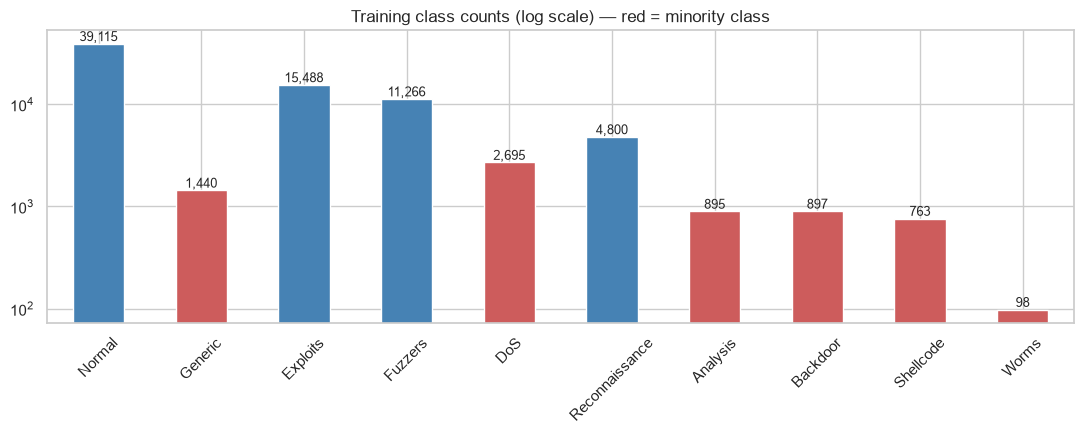

In [31]:
colors = ["indianred" if m else "steelblue" for m in imbalance_df["minority_class"]]
ax = imbalance_df["count"].plot(kind="bar", figsize=(11, 4.5), logy=True, color=colors,
                                title="Training class counts (log scale) — red = minority class")
for i, v in enumerate(imbalance_df["count"]):
    ax.text(i, v, f"{v:,}", ha="center", va="bottom", fontsize=9)
plt.xticks(rotation=45); plt.tight_layout(); plt.show()

## 14. Feature Selection

1. **Correlation analysis** on the encoded training features (correlation is unaffected by standardisation).
2. **Feature importance** from a quick class-balanced Random Forest.
3. **Selected features** — constant columns (e.g. one-hot columns that never occur in training) are removed and, for every pair correlated above 0.95,
   the member with lower importance is removed.

The selected column indices are applied to the scaled train / validation / test arrays. SMOTE and the GAN then operate directly on the *selected* features.

### 14.1 Correlation

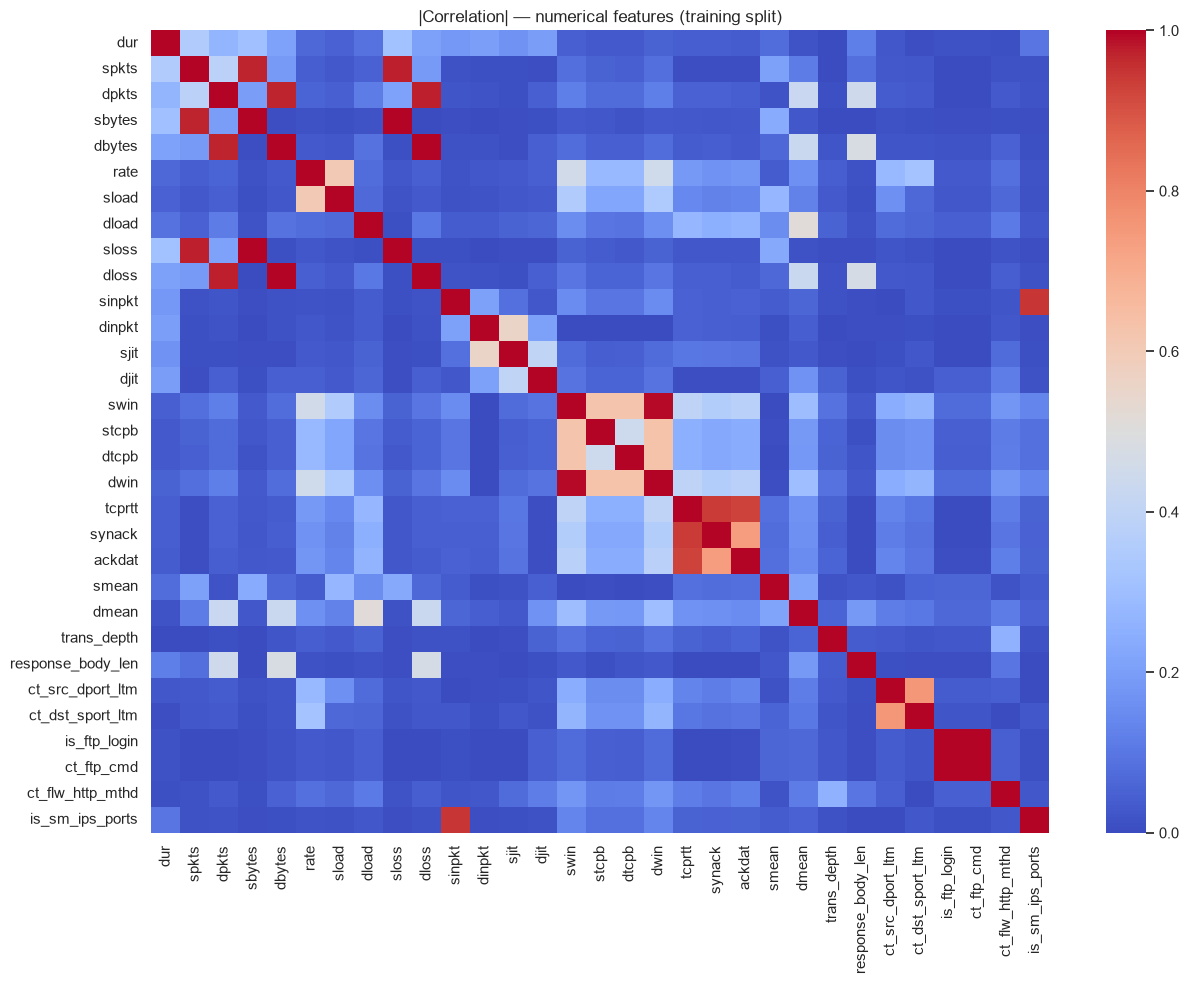

In [32]:
numeric_corr = X_train[numerical_cols].corr().abs()
plt.figure(figsize=(13, 10))
sns.heatmap(numeric_corr, cmap="coolwarm", vmin=0, vmax=1)
plt.title("|Correlation| — numerical features (training split)"); plt.tight_layout(); plt.show()

In [33]:
non_constant = X_train.columns[X_train.std() > 0]
constant_cols = sorted(set(X_train.columns) - set(non_constant))
print(f"{len(constant_cols)} constant (zero-variance) columns in training data")

corr_matrix = X_train[non_constant].corr().abs()
upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
pairs = (upper.stack().rename("corr").reset_index()
         .rename(columns={"level_0": "feature_a", "level_1": "feature_b"})
         .query("corr > 0.95").sort_values("corr", ascending=False))
print(f"{len(pairs)} feature pairs with |corr| > 0.95")
pairs.head(20)

2 constant (zero-variance) columns in training data
13 feature pairs with |corr| > 0.95


,feature_a,feature_b,corr
4996,is_ftp_login,ct_ftp_cmd,1.000000
2719,swin,proto_tcp,0.999901
560,sbytes,sloss,0.997257
745,dbytes,dloss,0.996651
3271,dwin,proto_tcp,0.993052
2593,swin,dwin,0.993004
377,dpkts,dloss,0.976233
192,spkts,sloss,0.976022
372,dpkts,dbytes,0.970400
187,spkts,sbytes,0.969721


### 14.2 Feature importance

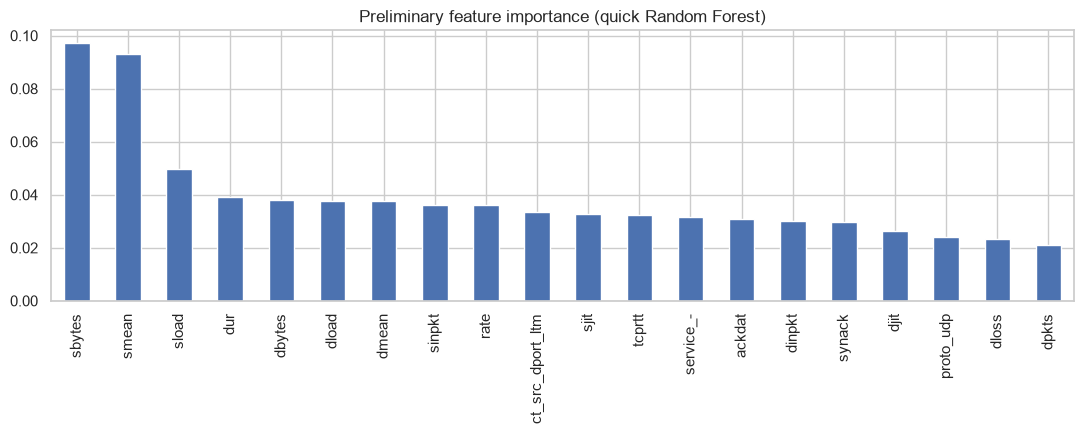

In [34]:
quick_rf = RandomForestClassifier(n_estimators=100, class_weight="balanced_subsample", random_state=RANDOM_STATE, n_jobs=-1)
quick_rf.fit(X_train_scaled, y_train_arr)
quick_importance = pd.Series(quick_rf.feature_importances_, index=feature_columns)

quick_importance.sort_values(ascending=False).head(20).plot(
    kind="bar", figsize=(11, 4.5), title="Preliminary feature importance (quick Random Forest)")
plt.tight_layout(); plt.show()

### 14.3 Selected features

In [35]:
to_drop = set(constant_cols)
for a, b in zip(pairs["feature_a"], pairs["feature_b"]):
    if a in to_drop or b in to_drop:
        continue                                   # pair already resolved
    to_drop.add(a if quick_importance[a] < quick_importance[b] else b)

keep_idx = [i for i, c in enumerate(feature_columns) if c not in to_drop]
feature_columns_selected = [feature_columns[i] for i in keep_idx]

print(f"Dropping {len(to_drop)} features ({len(constant_cols)} constant + {len(to_drop) - len(constant_cols)} redundant)")
print("Redundant features dropped:", sorted(to_drop - set(constant_cols)))
print("Feature count before:", len(feature_columns), "| after:", len(feature_columns_selected))

X_train_sel = X_train_scaled[:, keep_idx]        # original (imbalanced), scaled, selected
X_val_sel = X_val_scaled[:, keep_idx]
X_test_sel = X_test_scaled[:, keep_idx]

Dropping 10 features (2 constant + 8 redundant)
Redundant features dropped: ['ct_ftp_cmd', 'dloss', 'dpkts', 'dwin', 'proto_tcp', 'sloss', 'spkts', 'swin']
Feature count before: 186 | after: 176


## 15. BASELINE — Original Data

Five models are trained on the **original, imbalanced** training split — no resampling, no class weights. This is the reference every balancing strategy is compared with.

### Evaluation helper and model registry (used from here on)

One function computes every metric so models are always compared the same way. Every fitted model is stored under the name `"<model> [<strategy>]"`.

| Metric | Meaning in the multiclass setting |
|---|---|
| `f1_macro`, `recall_macro`, `precision_macro` | unweighted mean over the 10 classes — rare classes count as much as `Normal` |
| `f1_weighted` | class-size-weighted F1 |
| `roc_auc_ovr`, `pr_auc_macro` | one-vs-rest ROC-AUC / average precision, macro-averaged (NaN for hard-voting models, which have no probabilities) |
| `minority_f1` | mean F1 over the *minority classes* (< 5 % of the training data) |
| `macro_fpr` | per-class false-positive rate, averaged over classes |
| `normal_false_alarm_rate` | share of `Normal` traffic flagged as any attack (analyst workload) |
| `attack_miss_rate` | share of attack traffic classified as `Normal` (missed intrusions) |

In [36]:
def evaluate_model(model, X, y_true):
    y_pred = model.predict(X)
    labels = np.arange(n_classes)

    cm = confusion_matrix(y_true, y_pred, labels=labels)
    tp = np.diag(cm); fp = cm.sum(axis=0) - tp; fn = cm.sum(axis=1) - tp; tn = cm.sum() - tp - fp - fn
    fpr_per_class = fp / np.maximum(fp + tn, 1)

    roc_auc = pr_auc = np.nan
    if hasattr(model, "predict_proba"):            # hard-voting ensembles have no probabilities
        proba = model.predict_proba(X)
        y_bin = label_binarize(y_true, classes=labels)
        roc_auc = roc_auc_score(y_true, proba, multi_class="ovr", average="macro", labels=labels)
        pr_auc = np.mean([average_precision_score(y_bin[:, k], proba[:, k]) for k in labels])

    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "precision_macro": precision_score(y_true, y_pred, average="macro", zero_division=0),
        "recall_macro": recall_score(y_true, y_pred, average="macro", zero_division=0),
        "f1_macro": f1_score(y_true, y_pred, average="macro", zero_division=0),
        "f1_weighted": f1_score(y_true, y_pred, average="weighted", zero_division=0),
        "roc_auc_ovr": roc_auc,
        "pr_auc_macro": pr_auc,
        "minority_f1": f1_score(y_true, y_pred, labels=minority_ids, average="macro", zero_division=0),
        "macro_fpr": fpr_per_class.mean(),
        "normal_false_alarm_rate": 1 - cm[normal_id, normal_id] / max(cm[normal_id].sum(), 1),
        "attack_miss_rate": cm[attack_ids, normal_id].sum() / max(cm[attack_ids].sum(), 1),
    }

fitted_models, val_results, model_meta = {}, {}, {}

def fit_and_record(base_name, model, strategy, X_tr, y_tr, show_report=False):
    name = f"{base_name} [{strategy}]"
    model.fit(X_tr, y_tr)
    fitted_models[name] = model
    model_meta[name] = {"model": base_name, "strategy": strategy}
    val_results[name] = evaluate_model(model, X_val_sel, y_val_arr)
    r = val_results[name]
    print(f"=== {name} — validation: accuracy {r['accuracy']:.4f} | macro-F1 {r['f1_macro']:.4f} | "
          f"macro-recall {r['recall_macro']:.4f} | minority-F1 {r['minority_f1']:.4f} ===")
    if show_report:
        print(classification_report(y_val_arr, model.predict(X_val_sel), target_names=class_names, zero_division=0, digits=3))
    return model

def results_table(results=None):
    """Metrics DataFrame (default: validation) joined with model / strategy labels."""
    res = val_results if results is None else results
    return pd.DataFrame(res).T.join(pd.DataFrame(model_meta).T)

def make_models():
    return {
        "Logistic Regression": LogisticRegression(max_iter=500, random_state=RANDOM_STATE),
        "Decision Tree": DecisionTreeClassifier(random_state=RANDOM_STATE),
        "Random Forest": RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1),
        "XGBoost": XGBClassifier(objective="multi:softprob", n_estimators=200, max_depth=6, learning_rate=0.1,
                                 tree_method="hist", eval_metric="mlogloss", random_state=RANDOM_STATE, n_jobs=-1),
        "LightGBM": LGBMClassifier(objective="multiclass", n_estimators=200, learning_rate=0.1,
                                   random_state=RANDOM_STATE, n_jobs=-1, verbosity=-1),
    }

CORE_MODELS = ["Random Forest", "XGBoost", "LightGBM"]     # the three models that get every strategy + tuning
SHORT = {"Random Forest": "rf", "XGBoost": "xgb", "LightGBM": "lgbm"}

def fit_voting(label, member_names, strategy, X_tr, y_tr, voting="soft"):
    """Voting ensemble over already-registered models. Members are cloned and refitted on (X_tr, y_tr)."""
    estimators = [(f"m{i}", fitted_models[n]) for i, n in enumerate(member_names)]
    return fit_and_record(label, VotingClassifier(estimators=estimators, voting=voting), strategy, X_tr, y_tr)

SUMMARY_COLS = ["accuracy", "precision_macro", "recall_macro", "f1_macro", "f1_weighted", "minority_f1", "macro_fpr"]

### 15.1 Logistic Regression, Decision Tree, Random Forest, XGBoost, LightGBM

In [37]:
for base_name, clf in make_models().items():
    fit_and_record(base_name, clf, "Original", X_train_sel, y_train_arr)

=== Logistic Regression [Original] — validation: accuracy 0.6921 | macro-F1 0.3677 | macro-recall 0.3604 | minority-F1 0.1867 ===
=== Decision Tree [Original] — validation: accuracy 0.7722 | macro-F1 0.5082 | macro-recall 0.4971 | minority-F1 0.3328 ===
=== Random Forest [Original] — validation: accuracy 0.7970 | macro-F1 0.4551 | macro-recall 0.4382 | minority-F1 0.2408 ===
=== XGBoost [Original] — validation: accuracy 0.8135 | macro-F1 0.5261 | macro-recall 0.4985 | minority-F1 0.3495 ===
=== LightGBM [Original] — validation: accuracy 0.7863 | macro-F1 0.4779 | macro-recall 0.4781 | minority-F1 0.2841 ===


In [38]:
results_table().query("strategy == 'Original'")[SUMMARY_COLS].sort_values("f1_macro", ascending=False).round(4)

,accuracy,precision_macro,recall_macro,f1_macro,f1_weighted,minority_f1,macro_fpr
XGBoost [Original],0.8135,0.6002,0.4985,0.5261,0.8058,0.3495,0.0250
Decision Tree [Original],0.7722,0.5280,0.4971,0.5082,0.7824,0.3328,0.0297
LightGBM [Original],0.7863,0.4904,0.4781,0.4779,0.7843,0.2841,0.0283
Random Forest [Original],0.7970,0.4891,0.4382,0.4551,0.7894,0.2408,0.0270
Logistic Regression [Original],0.6921,0.3948,0.3604,0.3677,0.6859,0.1867,0.0420


## 16. SMOTE BASELINE

**Multiclass SMOTE** with a capped target. Oversampling every class up to the size of `Normal` would create hundreds of thousands of synthetic rows (and dozens of synthetic copies per real `Worms` row),
so every class below `SMOTE_TARGET` rows is lifted to exactly `SMOTE_TARGET`; larger classes are untouched. Only the training split is resampled.

SMOTE interpolates between neighbours, so one-hot columns can end up fractional; tree models tolerate this (`SMOTENC` is the stricter alternative).

In [39]:
SMOTE_TARGET = 5000   # minimum rows per class after oversampling (classes already larger are left as they are)

def smote_strategy(y, target=SMOTE_TARGET):
    counts = Counter(y)
    return {cls: target for cls, n in counts.items() if n < target}

min_count = pd.Series(y_train_arr).value_counts().min()
smote = SMOTE(sampling_strategy=smote_strategy, k_neighbors=max(1, min(5, min_count - 1)), random_state=RANDOM_STATE)
X_train_smote, y_train_smote = smote.fit_resample(X_train_sel, y_train_arr)
N_ORIGINAL = len(y_train_arr)      # imblearn appends the synthetic rows AFTER the original rows

print("Rows:", N_ORIGINAL, "->", len(y_train_smote))
smote_counts = pd.DataFrame({
    "before SMOTE": pd.Series(y_train_arr).value_counts().sort_index(),
    "after SMOTE": pd.Series(y_train_smote).value_counts().sort_index(),
})
smote_counts.index = class_names
smote_counts.loc[class_order]

Rows: 77457 -> 100869


,before SMOTE,after SMOTE
Normal,39115,39115
Generic,1440,5000
Exploits,15488,15488
Fuzzers,11266,11266
DoS,2695,5000
Reconnaissance,4800,5000
Analysis,895,5000
Backdoor,897,5000
Shellcode,763,5000
Worms,98,5000


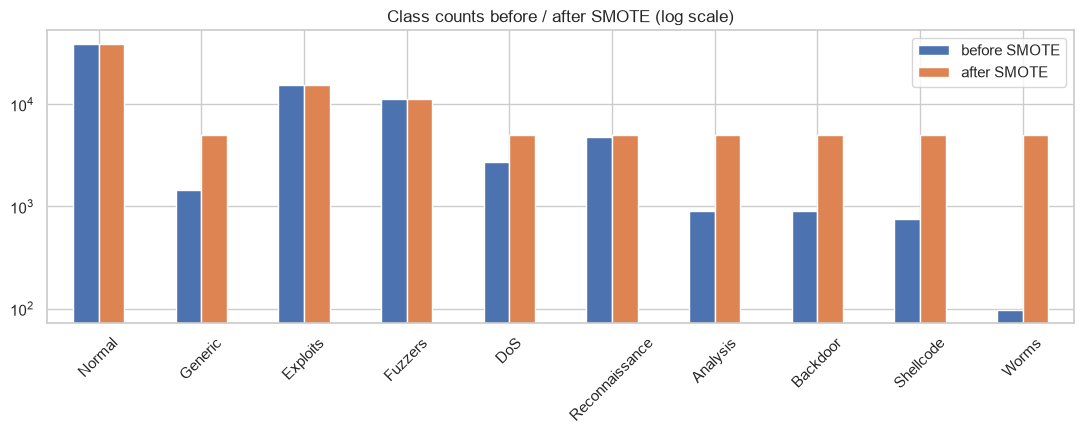

In [40]:
smote_counts.loc[class_order].plot(kind="bar", figsize=(11, 4.5), logy=True, title="Class counts before / after SMOTE (log scale)")
plt.xticks(rotation=45); plt.tight_layout(); plt.show()

### 16.1 Random Forest, XGBoost, LightGBM on SMOTE data

In [41]:
for base_name in CORE_MODELS:
    fit_and_record(base_name, make_models()[base_name], "SMOTE", X_train_smote, y_train_smote)

=== Random Forest [SMOTE] — validation: accuracy 0.7963 | macro-F1 0.5121 | macro-recall 0.5256 | minority-F1 0.3304 ===
=== XGBoost [SMOTE] — validation: accuracy 0.8070 | macro-F1 0.5501 | macro-recall 0.6134 | minority-F1 0.3762 ===
=== LightGBM [SMOTE] — validation: accuracy 0.8072 | macro-F1 0.5355 | macro-recall 0.5557 | minority-F1 0.3539 ===


### 16.2 SMOTE ensemble (soft voting)

In [42]:
ENSEMBLE_SOFT = "Voting Ensemble (soft, RF+XGB+LGBM)"
fit_voting(ENSEMBLE_SOFT, [f"{b} [SMOTE]" for b in CORE_MODELS], "SMOTE", X_train_smote, y_train_smote, voting="soft")
results_table().query("strategy == 'SMOTE'")[SUMMARY_COLS].sort_values("f1_macro", ascending=False).round(4)

=== Voting Ensemble (soft, RF+XGB+LGBM) [SMOTE] — validation: accuracy 0.8062 | macro-F1 0.5352 | macro-recall 0.5552 | minority-F1 0.3527 ===


,accuracy,precision_macro,recall_macro,f1_macro,f1_weighted,minority_f1,macro_fpr
XGBoost [SMOTE],0.8070,0.5580,0.6134,0.5501,0.8146,0.3762,0.0245
LightGBM [SMOTE],0.8072,0.5403,0.5557,0.5355,0.8133,0.3539,0.0247
"Voting Ensemble (soft, RF+XGB+LGBM) [SMOTE]",0.8062,0.5452,0.5552,0.5352,0.8130,0.3527,0.0247
Random Forest [SMOTE],0.7963,0.5161,0.5256,0.5121,0.7984,0.3304,0.0262


## 17. GAN OVERSAMPLING

The GAN notebook targeted one binary minority class. For the 10-class problem the same idea is applied **per class**: every minority class gets its own **WGAN-GP** (Wasserstein GAN with gradient penalty — more stable than a vanilla GAN),
trained only on that class's real training rows, and generates exactly the rows needed to reach `GAN_TARGET`. Setting `GAN_TARGET = SMOTE_TARGET` makes the comparison with Step 16 like-for-like.

Because the classes are trained on scaled features, generated rows are post-processed so they stay valid:
- every feature is **clipped** to the range seen in the real training data;
- **binary / one-hot columns are snapped** to their two real values (so there are no fractional dummies — unlike SMOTE).

### 17.1 Identify minority classes

In [43]:
GAN_TARGET = SMOTE_TARGET                          # same target size as SMOTE -> like-for-like comparison
gan_targets = smote_strategy(y_train_arr, GAN_TARGET)
gan_classes = sorted(gan_targets)

gan_plan = pd.DataFrame({
    "real_rows": [int((y_train_arr == k).sum()) for k in gan_classes],
    "target_rows": [gan_targets[k] for k in gan_classes],
}, index=[class_names[k] for k in gan_classes])
gan_plan["synthetic_to_generate"] = gan_plan["target_rows"] - gan_plan["real_rows"]
print("Classes that get a GAN:", list(gan_plan.index))
gan_plan

Classes that get a GAN: ['Analysis', 'Backdoor', 'DoS', 'Generic', 'Reconnaissance', 'Shellcode', 'Worms']


,real_rows,target_rows,synthetic_to_generate
Analysis,895,5000,4105
Backdoor,897,5000,4103
DoS,2695,5000,2305
Generic,1440,5000,3560
Reconnaissance,4800,5000,200
Shellcode,763,5000,4237
Worms,98,5000,4902


### 17.2 Prepare minority data

In [44]:
# Real (scaled, selected) rows of every minority class = the training data of that class's GAN
X_by_class = {k: X_train_sel[y_train_arr == k] for k in gan_classes}

# Valid ranges (from the real training data) used to post-process generated rows
feat_min, feat_max = X_train_sel.min(axis=0), X_train_sel.max(axis=0)

# One-hot / binary columns: detect them on the UNSCALED training data
is_binary = X_train[feature_columns_selected].apply(lambda s: set(s.unique()) <= {0.0, 1.0}).to_numpy()
binary_sel_idx = np.where(is_binary)[0]
print(f"{len(binary_sel_idx)} of {X_train_sel.shape[1]} selected features are binary (will be snapped to 2 values)")

153 of 176 selected features are binary (will be snapped to 2 values)


### 17.3 Train the GAN (one WGAN-GP per minority class)

Generator: `noise (32) → 128 → 128 → features`. Critic: `features → 128 → 128 → 1` with a gradient penalty (λ = 10) and 5 critic updates per generator update.
Increase `GAN_ITERS` for a final run (2 000 keeps the notebook quick; watch the mean/std gap in Step 17.5).

In [45]:
GAN_ITERS = 2000          # generator updates per class
LATENT_DIM = 32
N_CRITIC = 5
LAMBDA_GP = 10.0
GAN_BATCH = 128

class Generator(nn.Module):
    def __init__(self, latent_dim, n_features):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(latent_dim, 128), nn.LeakyReLU(0.2),
            nn.Linear(128, 128), nn.LeakyReLU(0.2),
            nn.Linear(128, n_features),
        )
    def forward(self, z):
        return self.net(z)

class Critic(nn.Module):
    def __init__(self, n_features):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(n_features, 128), nn.LeakyReLU(0.2),
            nn.Linear(128, 128), nn.LeakyReLU(0.2),
            nn.Linear(128, 1),
        )
    def forward(self, x):
        return self.net(x)

def gradient_penalty(critic, real, fake):
    eps = torch.rand(real.size(0), 1, device=real.device)
    interp = (eps * real + (1 - eps) * fake).requires_grad_(True)
    scores = critic(interp)
    grads = torch.autograd.grad(outputs=scores, inputs=interp, grad_outputs=torch.ones_like(scores),
                                create_graph=True, retain_graph=True)[0]
    return ((grads.reshape(real.size(0), -1).norm(2, dim=1) - 1) ** 2).mean()

def train_wgan_gp(X_real, n_iters=GAN_ITERS, seed=RANDOM_STATE):
    torch.manual_seed(seed)
    n_feat = X_real.shape[1]
    G, C = Generator(LATENT_DIM, n_feat).to(device), Critic(n_feat).to(device)
    g_opt = optim.Adam(G.parameters(), lr=1e-4, betas=(0.5, 0.9))
    c_opt = optim.Adam(C.parameters(), lr=1e-4, betas=(0.5, 0.9))
    real_t = torch.tensor(X_real, dtype=torch.float32, device=device)
    bs = min(GAN_BATCH, len(real_t))
    hist = {"critic_loss": [], "gen_loss": []}

    for _ in range(n_iters):
        for _ in range(N_CRITIC):
            real = real_t[torch.randint(0, len(real_t), (bs,), device=device)]
            fake = G(torch.randn(bs, LATENT_DIM, device=device)).detach()
            c_opt.zero_grad()
            c_loss = C(fake).mean() - C(real).mean() + LAMBDA_GP * gradient_penalty(C, real, fake)
            c_loss.backward(); c_opt.step()

        g_opt.zero_grad()
        g_loss = -C(G(torch.randn(bs, LATENT_DIM, device=device))).mean()
        g_loss.backward(); g_opt.step()

        hist["critic_loss"].append(c_loss.item()); hist["gen_loss"].append(g_loss.item())
    return G, hist

generators, gan_history = {}, {}
for k in gan_classes:
    generators[k], gan_history[k] = train_wgan_gp(X_by_class[k])
    print(f"{class_names[k]:15s} trained on {len(X_by_class[k]):5d} real rows | "
          f"final critic loss {np.mean(gan_history[k]['critic_loss'][-50:]):8.4f} | "
          f"final generator loss {np.mean(gan_history[k]['gen_loss'][-50:]):8.4f}")

Analysis        trained on   895 real rows | final critic loss -46.3366 | final generator loss  -8.3389
Backdoor        trained on   897 real rows | final critic loss -46.6824 | final generator loss  -8.3452
DoS             trained on  2695 real rows | final critic loss -14.4097 | final generator loss  -6.1592
Generic         trained on  1440 real rows | final critic loss  -5.9879 | final generator loss  -5.3943
Reconnaissance  trained on  4800 real rows | final critic loss  -8.4949 | final generator loss -11.2276
Shellcode       trained on   763 real rows | final critic loss  -1.2798 | final generator loss   6.8740
Worms           trained on    98 real rows | final critic loss  -1.7175 | final generator loss   0.1671


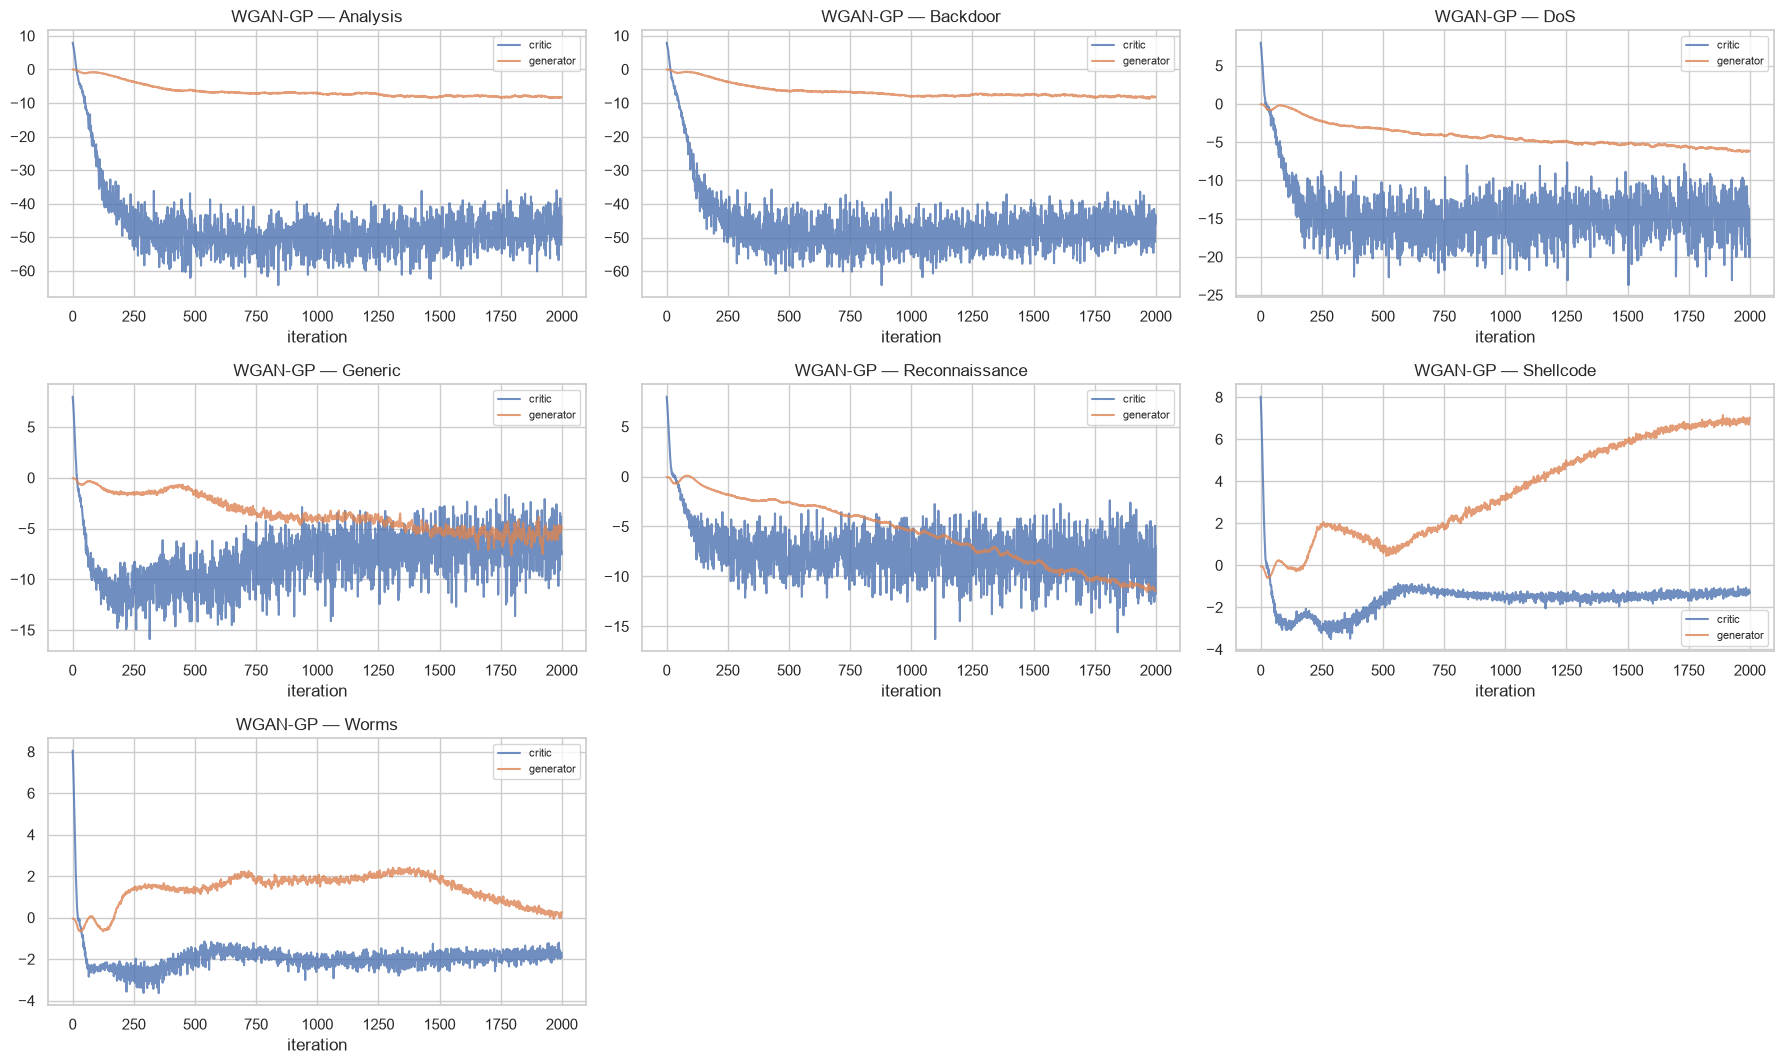

In [46]:
n_cols = 3
n_rows = math.ceil(len(gan_classes) / n_cols)
fig, axes = plt.subplots(n_rows, n_cols, figsize=(6 * n_cols, 3.6 * n_rows), squeeze=False)
for ax, k in zip(axes.ravel(), gan_classes):
    ax.plot(gan_history[k]["critic_loss"], label="critic", alpha=0.8)
    ax.plot(gan_history[k]["gen_loss"], label="generator", alpha=0.8)
    ax.set_title(f"WGAN-GP — {class_names[k]}"); ax.set_xlabel("iteration"); ax.legend(fontsize=8)
for ax in axes.ravel()[len(gan_classes):]:
    ax.axis("off")
plt.tight_layout(); plt.show()

### 17.4 Generate synthetic samples

In [47]:
def generate_synthetic(generator, n):
    generator.eval()
    with torch.no_grad():
        X_new = generator(torch.randn(n, LATENT_DIM, device=device)).cpu().numpy()
    X_new = np.clip(X_new, feat_min, feat_max)                       # stay inside the real feature ranges
    for j in binary_sel_idx:                                         # snap one-hot / flag columns to their 2 real values
        lo, hi = feat_min[j], feat_max[j]
        X_new[:, j] = np.where(np.abs(X_new[:, j] - lo) < np.abs(X_new[:, j] - hi), lo, hi)
    return X_new

torch.manual_seed(RANDOM_STATE)
X_syn_by_class = {k: generate_synthetic(generators[k], int(gan_plan.loc[class_names[k], "synthetic_to_generate"]))
                  for k in gan_classes}
print({class_names[k]: len(v) for k, v in X_syn_by_class.items()}, "<- synthetic rows per class")

{'Analysis': 4105, 'Backdoor': 4103, 'DoS': 2305, 'Generic': 3560, 'Reconnaissance': 200, 'Shellcode': 4237, 'Worms': 4902} <- synthetic rows per class


### 17.5 Validate synthetic samples

Three checks per class, with SMOTE's synthetic rows evaluated the same way for reference:

1. **PCA projection** — synthetic points should land inside the real class cloud (not scattered, not collapsed to a point).
2. **Feature-wise mean / std gap** between real and synthetic rows (smaller is better).
3. **Real-vs-synthetic classifier AUC** — a Random Forest tries to tell real from synthetic rows (3-fold CV). AUC ≈ 0.5 means indistinguishable; AUC → 1.0 means the synthetic rows are easy to spot.

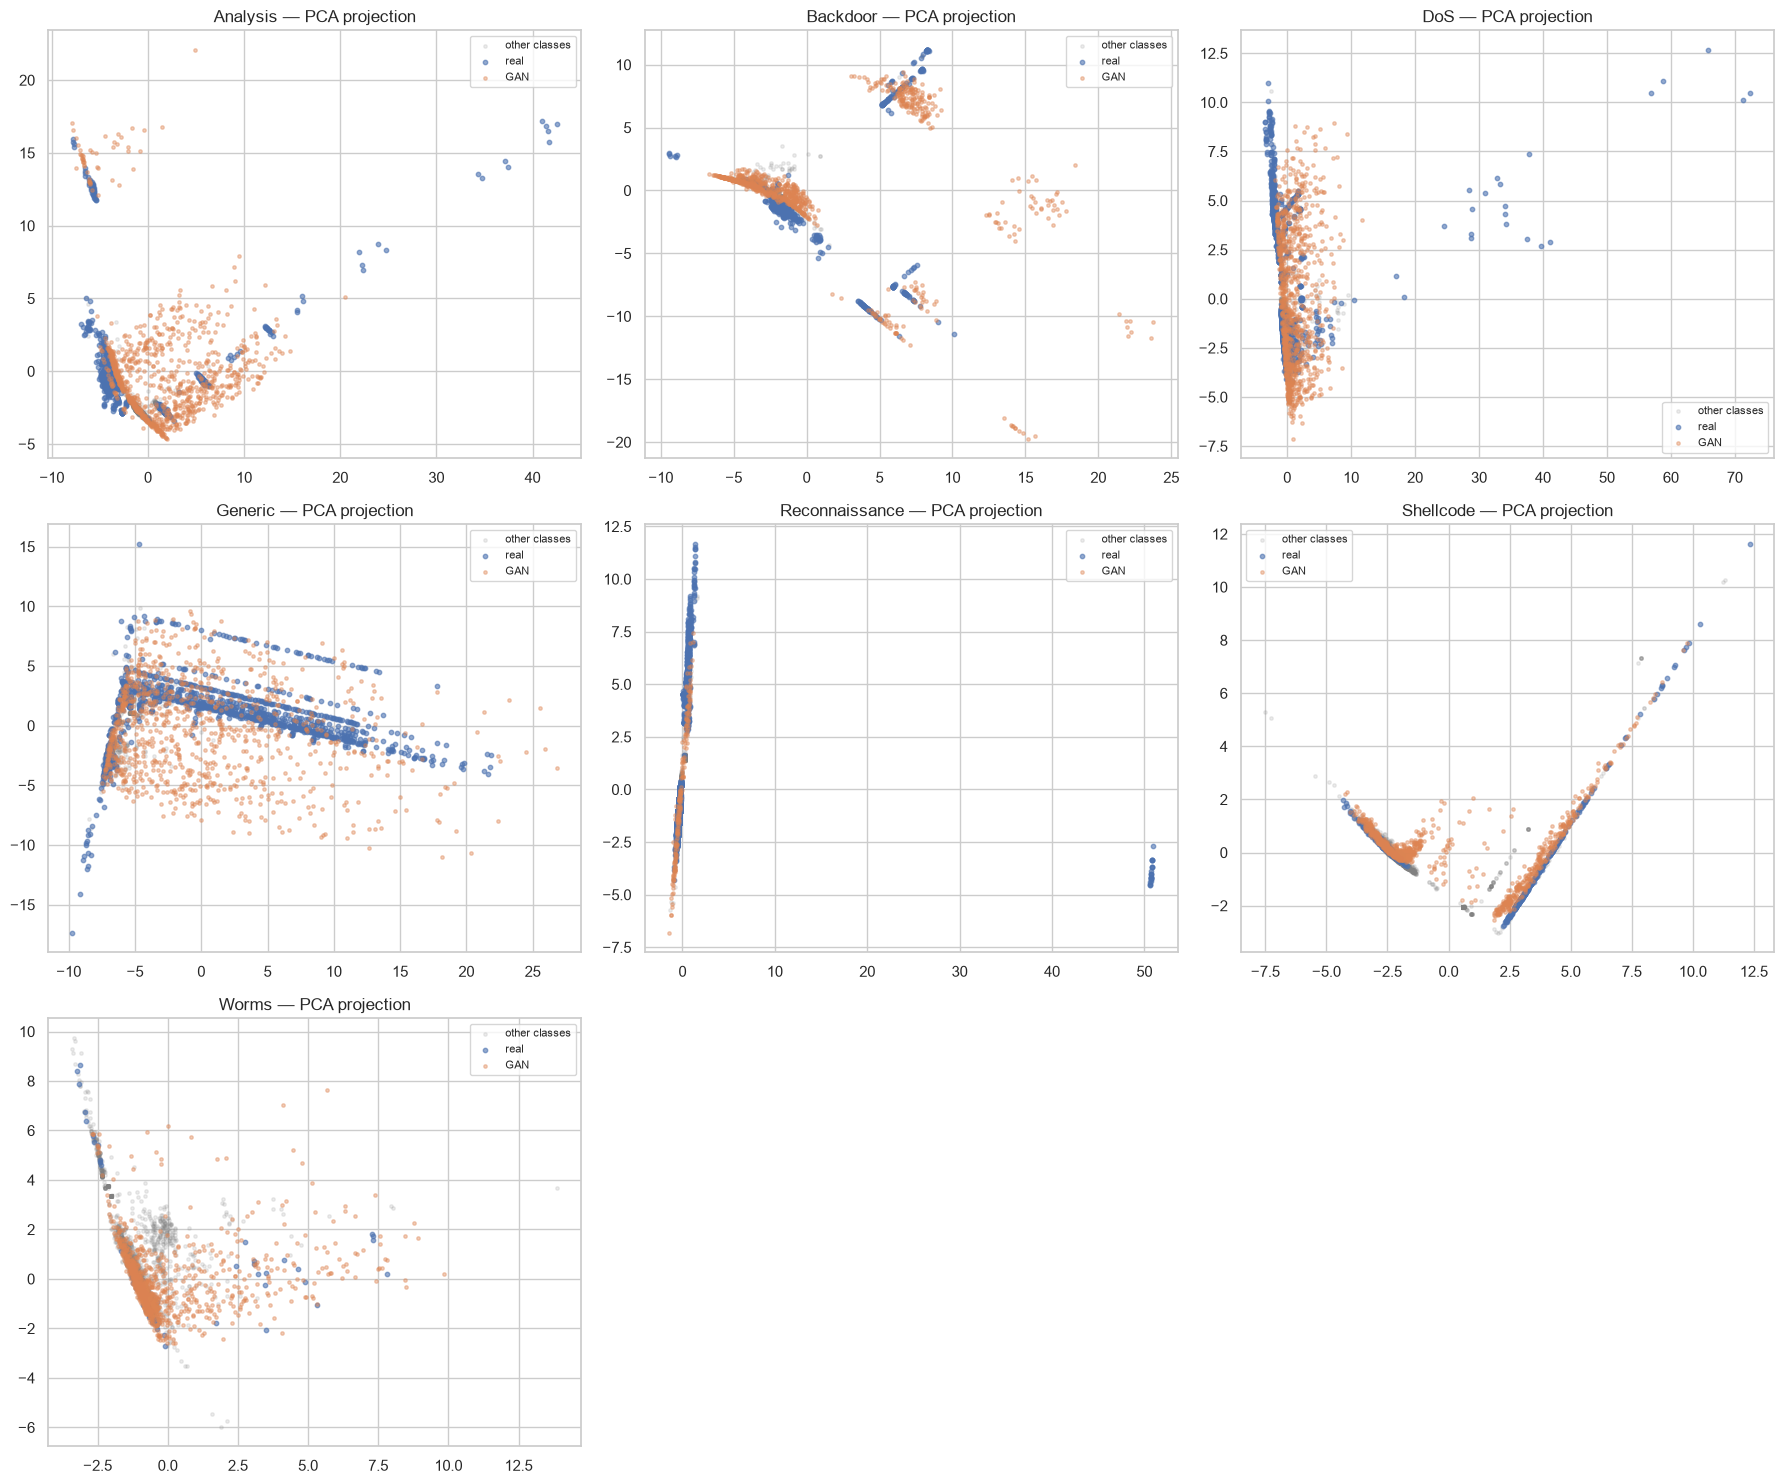

In [48]:
rng = np.random.RandomState(RANDOM_STATE)
n_cols = 3
n_rows = math.ceil(len(gan_classes) / n_cols)
fig, axes = plt.subplots(n_rows, n_cols, figsize=(6 * n_cols, 5 * n_rows), squeeze=False)

for ax, k in zip(axes.ravel(), gan_classes):
    real, syn = X_by_class[k], X_syn_by_class[k]
    syn_plot = syn[rng.choice(len(syn), min(len(syn), 1000), replace=False)]
    other_idx = rng.choice(np.where(y_train_arr != k)[0], min(1500, int((y_train_arr != k).sum())), replace=False)

    pca = PCA(n_components=2, random_state=RANDOM_STATE).fit(np.vstack([real, syn_plot]))
    ax.scatter(*pca.transform(X_train_sel[other_idx]).T, s=6, alpha=0.15, color="gray", label="other classes")
    ax.scatter(*pca.transform(real).T, s=10, alpha=0.6, label="real")
    ax.scatter(*pca.transform(syn_plot).T, s=6, alpha=0.4, label="GAN")
    ax.set_title(f"{class_names[k]} — PCA projection"); ax.legend(fontsize=8)
for ax in axes.ravel()[len(gan_classes):]:
    ax.axis("off")
plt.tight_layout(); plt.show()

In [49]:
def two_sample_auc(real, syn, seed=RANDOM_STATE):
    """CV ROC-AUC of a Random Forest separating real (1) from synthetic (0) rows; ~0.5 = indistinguishable."""
    r = np.random.RandomState(seed)
    n = min(len(real), len(syn))
    Xc = np.vstack([real[r.choice(len(real), n, replace=False)], syn[r.choice(len(syn), n, replace=False)]])
    yc = np.r_[np.ones(n), np.zeros(n)]
    clf = RandomForestClassifier(n_estimators=100, max_depth=10, random_state=seed, n_jobs=-1)
    return cross_val_score(clf, Xc, yc, cv=StratifiedKFold(3, shuffle=True, random_state=seed), scoring="roc_auc").mean()

X_smote_syn, y_smote_syn = X_train_smote[N_ORIGINAL:], y_train_smote[N_ORIGINAL:]

rows = []
for k in gan_classes:
    real, syn = X_by_class[k], X_syn_by_class[k]
    smote_syn = X_smote_syn[y_smote_syn == k]
    rows.append({
        "class": class_names[k],
        "real_rows": len(real),
        "GAN: |mean gap|": np.abs(real.mean(0) - syn.mean(0)).mean(),
        "GAN: |std gap|": np.abs(real.std(0) - syn.std(0)).mean(),
        "SMOTE: |mean gap|": np.abs(real.mean(0) - smote_syn.mean(0)).mean(),
        "SMOTE: |std gap|": np.abs(real.std(0) - smote_syn.std(0)).mean(),
        "GAN: real-vs-syn AUC": two_sample_auc(real, syn),
        "SMOTE: real-vs-syn AUC": two_sample_auc(real, smote_syn),
    })
synthetic_quality = pd.DataFrame(rows).set_index("class")
display(synthetic_quality.round(3))
print("Smaller gaps and AUC closer to 0.5 are better. Large gaps mean the GAN has not converged for that class "
      "(raise GAN_ITERS, or lower the learning rate).")

,real_rows,GAN: |mean gap|,GAN: |std gap|,SMOTE: |mean gap|,SMOTE: |std gap|,GAN: real-vs-syn AUC,SMOTE: real-vs-syn AUC
class,,,,,,,
Analysis,895,0.227,2.667,0.053,0.451,1.0,0.771
Backdoor,897,0.243,2.660,0.051,0.474,1.0,0.768
DoS,2695,0.129,1.665,0.028,0.458,1.0,0.684
Generic,1440,0.090,0.975,0.018,0.454,1.0,0.668
Reconnaissance,4800,0.107,1.259,0.056,1.194,1.0,0.455
Shellcode,763,0.008,0.008,0.002,0.002,1.0,0.571
Worms,98,0.011,0.036,0.002,0.009,1.0,0.581


Smaller gaps and AUC closer to 0.5 are better. Large gaps mean the GAN has not converged for that class (raise GAN_ITERS, or lower the learning rate).


### 17.6 Combine real + synthetic data

In [50]:
X_train_gan_sel = np.vstack([X_train_sel] + [X_syn_by_class[k] for k in gan_classes])
y_train_gan = np.concatenate([y_train_arr] + [np.full(len(X_syn_by_class[k]), k) for k in gan_classes])

gan_counts = pd.DataFrame({
    "original": pd.Series(y_train_arr).value_counts().sort_index(),
    "SMOTE": pd.Series(y_train_smote).value_counts().sort_index(),
    "GAN": pd.Series(y_train_gan).value_counts().sort_index(),
})
gan_counts.index = class_names
print("Rows:", len(y_train_arr), "-> GAN-balanced:", len(y_train_gan))
gan_counts.loc[class_order]

Rows: 77457 -> GAN-balanced: 100869


,original,SMOTE,GAN
Normal,39115,39115,39115
Generic,1440,5000,5000
Exploits,15488,15488,15488
Fuzzers,11266,11266,11266
DoS,2695,5000,5000
Reconnaissance,4800,5000,5000
Analysis,895,5000,5000
Backdoor,897,5000,5000
Shellcode,763,5000,5000
Worms,98,5000,5000


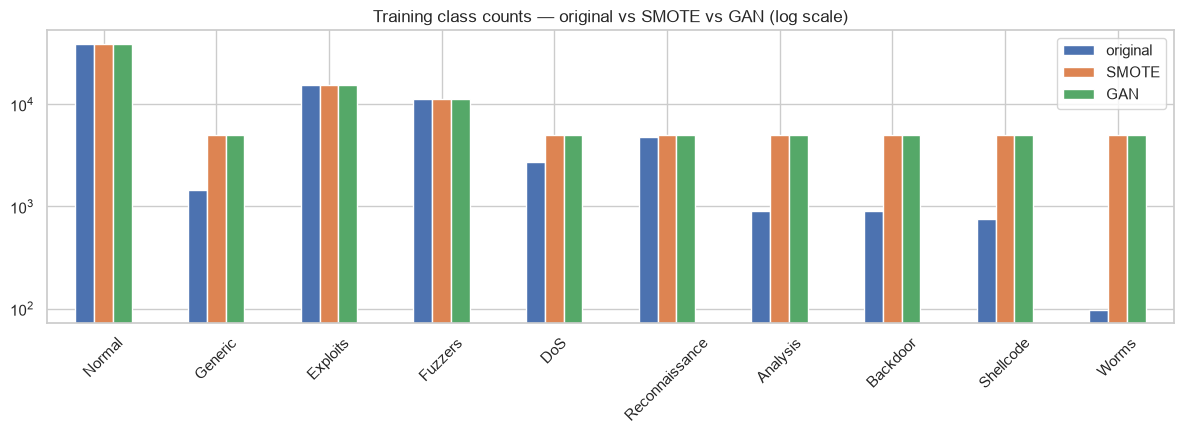

In [51]:
gan_counts.loc[class_order].plot(kind="bar", figsize=(12, 4.5), logy=True, title="Training class counts — original vs SMOTE vs GAN (log scale)")
plt.xticks(rotation=45); plt.tight_layout(); plt.show()

## 18. GAN-BASED MULTICLASS CLASSIFICATION

Same models and hyper-parameters as Steps 15-16, trained on the GAN-balanced training set. Validation data is untouched real data.

### 18.1 Random Forest, XGBoost, LightGBM on GAN data

In [52]:
for base_name in CORE_MODELS:
    fit_and_record(base_name, make_models()[base_name], "GAN", X_train_gan_sel, y_train_gan)

=== Random Forest [GAN] — validation: accuracy 0.7967 | macro-F1 0.4572 | macro-recall 0.4416 | minority-F1 0.2441 ===
=== XGBoost [GAN] — validation: accuracy 0.8130 | macro-F1 0.5326 | macro-recall 0.5111 | minority-F1 0.3567 ===
=== LightGBM [GAN] — validation: accuracy 0.8094 | macro-F1 0.5371 | macro-recall 0.5141 | minority-F1 0.3661 ===


### 18.2 GAN ensemble (soft voting)

In [53]:
fit_voting(ENSEMBLE_SOFT, [f"{b} [GAN]" for b in CORE_MODELS], "GAN", X_train_gan_sel, y_train_gan, voting="soft")
results_table().query("strategy == 'GAN'")[SUMMARY_COLS].sort_values("f1_macro", ascending=False).round(4)

=== Voting Ensemble (soft, RF+XGB+LGBM) [GAN] — validation: accuracy 0.8066 | macro-F1 0.5008 | macro-recall 0.4754 | minority-F1 0.3086 ===


,accuracy,precision_macro,recall_macro,f1_macro,f1_weighted,minority_f1,macro_fpr
LightGBM [GAN],0.8094,0.5899,0.5141,0.5371,0.8061,0.3661,0.0252
XGBoost [GAN],0.8130,0.5924,0.5111,0.5326,0.8076,0.3567,0.0249
"Voting Ensemble (soft, RF+XGB+LGBM) [GAN]",0.8066,0.5576,0.4754,0.5008,0.8008,0.3086,0.0257
Random Forest [GAN],0.7967,0.4868,0.4416,0.4572,0.7892,0.2441,0.0271


## 19. Hyperparameter Tuning

`RandomizedSearchCV` for Random Forest and LightGBM (broad, cheap) and `GridSearchCV` for XGBoost (small, focused grid), all scored with **`f1_macro`**.

Design choices that keep the search honest and fast:
- **Which training set?** The tuned models are refitted on the balancing strategy that gave the best mean macro-F1 across RF / XGBoost / LightGBM on the *validation* split in Steps 15-18 (`TUNED_STRATEGY`; set it to `"Original"`, `"SMOTE"` or `"GAN"` to override).
- The search runs on a stratified **subsample** of the *un-resampled* training data. Balancing inside the CV folds is done with **SMOTE** (a GAN cannot be retrained inside every fold at reasonable cost), so validation folds never contain synthetic copies of training points. It acts as a proxy for GAN-balanced training. If the chosen strategy is `Original`, no resampling is used in the folds.
- The winning parameters are then **re-fitted on the full training set of the chosen strategy**, the same data the untuned models of that strategy use.

In [54]:
_rt = results_table()
core_scores = _rt[_rt["model"].isin(CORE_MODELS)].groupby("strategy")["f1_macro"].mean().sort_values(ascending=False)
print("Mean validation macro-F1 of RF / XGBoost / LightGBM per strategy:")
print(core_scores.round(4).to_string())

TUNED_STRATEGY = None                     # None = pick automatically; or "Original" / "SMOTE" / "GAN"
if TUNED_STRATEGY is None:
    TUNED_STRATEGY = core_scores.idxmax()
print("\nTuned models will be fitted on the", TUNED_STRATEGY, "training set")

TRAIN_SETS = {
    "Original": (X_train_sel, y_train_arr),
    "SMOTE": (X_train_smote, y_train_smote),
    "GAN": (X_train_gan_sel, y_train_gan),
}
X_fit, y_fit = TRAIN_SETS[TUNED_STRATEGY]

Mean validation macro-F1 of RF / XGBoost / LightGBM per strategy:
strategy
SMOTE       0.5326
GAN         0.5090
Original    0.4864

Tuned models will be fitted on the SMOTE training set


In [55]:
TUNE_N = 40000            # rows used for the search (all rows if the training set is smaller)
TUNE_SMOTE_TARGET = 2000  # smaller SMOTE cap inside the CV folds, matched to the subsample size

if len(y_train_arr) > TUNE_N:
    X_tune, _, y_tune, _ = train_test_split(X_train_sel, y_train_arr, train_size=TUNE_N,
                                            stratify=y_train_arr, random_state=RANDOM_STATE)
else:
    X_tune, y_tune = X_train_sel, y_train_arr

cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)

def tuning_pipeline(clf):
    steps = []
    if TUNED_STRATEGY != "Original":
        steps.append(("smote", SMOTE(sampling_strategy=partial(smote_strategy, target=TUNE_SMOTE_TARGET),
                                     k_neighbors=3, random_state=RANDOM_STATE)))
    steps.append(("clf", clf))
    return ImbPipeline(steps)

strip = lambda params: {k.replace("clf__", ""): v for k, v in params.items()}
print("Tuning subsample:", X_tune.shape)

Tuning subsample: (40000, 176)


### 19.1 Random Forest — `RandomizedSearchCV`

In [56]:
rf_param_dist = {
    "clf__n_estimators": [100, 200, 300],
    "clf__max_depth": [None, 15, 25],
    "clf__min_samples_split": [2, 5, 10],
    "clf__min_samples_leaf": [1, 2, 4],
    "clf__max_features": ["sqrt", "log2"],
}
rf_search = RandomizedSearchCV(
    tuning_pipeline(RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=1)),
    param_distributions=rf_param_dist, n_iter=10, scoring="f1_macro", cv=cv,
    random_state=RANDOM_STATE, n_jobs=-1, verbose=1,
)
rf_search.fit(X_tune, y_tune)
print("Best RF params (RandomizedSearchCV):", strip(rf_search.best_params_))
print(f"Best RF CV macro-F1: {rf_search.best_score_:.4f}")

fit_and_record("Random Forest (tuned)",
               RandomForestClassifier(**strip(rf_search.best_params_), random_state=RANDOM_STATE, n_jobs=-1),
               TUNED_STRATEGY, X_fit, y_fit)

Fitting 3 folds for each of 10 candidates, totalling 30 fits
Best RF params (RandomizedSearchCV): {'n_estimators': 300, 'min_samples_split': 5, 'min_samples_leaf': 4, 'max_features': 'sqrt', 'max_depth': 25}
Best RF CV macro-F1: 0.5329
=== Random Forest (tuned) [SMOTE] — validation: accuracy 0.7967 | macro-F1 0.5161 | macro-recall 0.5647 | minority-F1 0.3268 ===


,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",300
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",25
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",5
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",4
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total n

### 19.2 XGBoost — `GridSearchCV`

In [57]:
xgb_param_grid = {
    "clf__n_estimators": [100, 200],
    "clf__max_depth": [4, 6, 8],
    "clf__learning_rate": [0.05, 0.1],
}
xgb_search = GridSearchCV(
    tuning_pipeline(XGBClassifier(objective="multi:softprob", tree_method="hist", eval_metric="mlogloss",
                                  random_state=RANDOM_STATE, n_jobs=1)),
    param_grid=xgb_param_grid, scoring="f1_macro", cv=cv, n_jobs=-1, verbose=1,
)
xgb_search.fit(X_tune, y_tune)
print("Best XGBoost params (GridSearchCV):", strip(xgb_search.best_params_))
print(f"Best XGBoost CV macro-F1: {xgb_search.best_score_:.4f}")

fit_and_record("XGBoost (tuned)",
               XGBClassifier(objective="multi:softprob", tree_method="hist", eval_metric="mlogloss",
                             **strip(xgb_search.best_params_), random_state=RANDOM_STATE, n_jobs=-1),
               TUNED_STRATEGY, X_fit, y_fit)

Fitting 3 folds for each of 12 candidates, totalling 36 fits
Best XGBoost params (GridSearchCV): {'learning_rate': 0.05, 'max_depth': 8, 'n_estimators': 200}
Best XGBoost CV macro-F1: 0.5575
=== XGBoost (tuned) [SMOTE] — validation: accuracy 0.8059 | macro-F1 0.5487 | macro-recall 0.6124 | minority-F1 0.3738 ===


,"objective objective: typing.Union[str, xgboost.objective.Objective, xgboost.sklearn._SklObjWProto, typing.Callable[[typing.Any, typing.Any], typing.Tuple[numpy.ndarray, numpy.ndarray]], NoneType]Specify the learning task and the corresponding learning objective or a customobjective to be used.For custom objective, see :doc:`/tutorials/custom_metric_obj` and:ref:`custom-obj-metric` for more information, along with the end note forfunction signatures.",'multi:softprob'
,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,None
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklear

### 19.3 LightGBM — `RandomizedSearchCV`

In [58]:
lgbm_param_dist = {
    "clf__n_estimators": [100, 200, 300],
    "clf__learning_rate": [0.03, 0.05, 0.1],
    "clf__num_leaves": [31, 63, 127],
    "clf__min_child_samples": [10, 20, 40],
    "clf__colsample_bytree": [0.7, 0.85, 1.0],
}
lgbm_search = RandomizedSearchCV(
    tuning_pipeline(LGBMClassifier(objective="multiclass", random_state=RANDOM_STATE, n_jobs=1, verbosity=-1)),
    param_distributions=lgbm_param_dist, n_iter=10, scoring="f1_macro", cv=cv,
    random_state=RANDOM_STATE, n_jobs=-1, verbose=1,
)
lgbm_search.fit(X_tune, y_tune)
print("Best LightGBM params (RandomizedSearchCV):", strip(lgbm_search.best_params_))
print(f"Best LightGBM CV macro-F1: {lgbm_search.best_score_:.4f}")

fit_and_record("LightGBM (tuned)",
               LGBMClassifier(objective="multiclass", **strip(lgbm_search.best_params_),
                              random_state=RANDOM_STATE, n_jobs=-1, verbosity=-1),
               TUNED_STRATEGY, X_fit, y_fit)

Fitting 3 folds for each of 10 candidates, totalling 30 fits
Best LightGBM params (RandomizedSearchCV): {'num_leaves': 31, 'n_estimators': 300, 'min_child_samples': 40, 'learning_rate': 0.03, 'colsample_bytree': 0.7}
Best LightGBM CV macro-F1: 0.5578
=== LightGBM (tuned) [SMOTE] — validation: accuracy 0.8095 | macro-F1 0.5501 | macro-recall 0.5980 | minority-F1 0.3744 ===


,learning_rate,0.03
,n_estimators,300
,objective,'multiclass'
,min_child_samples,40
,colsample_bytree,0.7
,random_state,42
,n_jobs,-1
,verbosity,-1
,boosting_type,'gbdt'
,num_leaves,31
,max_depth,-1


In [59]:
tuning_summary = pd.DataFrame({
    "search": ["RandomizedSearchCV", "GridSearchCV", "RandomizedSearchCV"],
    "cv_f1_macro": [rf_search.best_score_, xgb_search.best_score_, lgbm_search.best_score_],
    "best_params": [strip(rf_search.best_params_), strip(xgb_search.best_params_), strip(lgbm_search.best_params_)],
}, index=["Random Forest", "XGBoost", "LightGBM"])

untuned = {b: val_results[f"{b} [{TUNED_STRATEGY}]"]["f1_macro"] for b in CORE_MODELS}
tuning_summary["val_f1_macro_untuned"] = pd.Series(untuned)
tuning_summary["val_f1_macro_tuned"] = pd.Series({b: val_results[f"{b} (tuned) [{TUNED_STRATEGY}]"]["f1_macro"] for b in CORE_MODELS})
tuning_summary

,search,cv_f1_macro,best_params,val_f1_macro_untuned,val_f1_macro_tuned
Random Forest,RandomizedSearchCV,0.532890,"{'n_estimators': 300, 'min_samples_split': 5, ...",0.512091,0.516060
XGBoost,GridSearchCV,0.557523,"{'learning_rate': 0.05, 'max_depth': 8, 'n_est...",0.550145,0.548659
LightGBM,RandomizedSearchCV,0.557793,"{'num_leaves': 31, 'n_estimators': 300, 'min_c...",0.535479,0.550111


## 20. Ensemble Classification

Tuned Random Forest + XGBoost + LightGBM combined by
- **hard voting** — each model votes for a class, the majority wins;
- **soft voting** — class probabilities are averaged, the highest average wins (also gives a confidence value and ROC/PR curves).

Members are refitted on the same training set as the tuned models.

In [60]:
tuned_members = [f"{b} (tuned) [{TUNED_STRATEGY}]" for b in CORE_MODELS]
fit_voting("Voting Ensemble (soft, tuned)", tuned_members, TUNED_STRATEGY, X_fit, y_fit, voting="soft")
fit_voting("Voting Ensemble (hard, tuned)", tuned_members, TUNED_STRATEGY, X_fit, y_fit, voting="hard")

_rt = results_table()
_rt[_rt["model"].str.contains("tuned")][SUMMARY_COLS].sort_values("f1_macro", ascending=False).round(4)

=== Voting Ensemble (soft, tuned) [SMOTE] — validation: accuracy 0.8090 | macro-F1 0.5513 | macro-recall 0.6008 | minority-F1 0.3761 ===
=== Voting Ensemble (hard, tuned) [SMOTE] — validation: accuracy 0.8084 | macro-F1 0.5542 | macro-recall 0.6068 | minority-F1 0.3810 ===


,accuracy,precision_macro,recall_macro,f1_macro,f1_weighted,minority_f1,macro_fpr
"Voting Ensemble (hard, tuned) [SMOTE]",0.8084,0.5724,0.6068,0.5542,0.8159,0.3810,0.0241
"Voting Ensemble (soft, tuned) [SMOTE]",0.8090,0.5712,0.6008,0.5513,0.8168,0.3761,0.0242
LightGBM (tuned) [SMOTE],0.8095,0.5547,0.5980,0.5501,0.8163,0.3744,0.0242
XGBoost (tuned) [SMOTE],0.8059,0.5565,0.6124,0.5487,0.8139,0.3738,0.0245
Random Forest (tuned) [SMOTE],0.7967,0.5525,0.5647,0.5161,0.8041,0.3268,0.0253


### Final multiclass prediction (soft-voting ensemble)

In [61]:
soft_ens = fitted_models[f"Voting Ensemble (soft, tuned) [{TUNED_STRATEGY}]"]
hard_ens = fitted_models[f"Voting Ensemble (hard, tuned) [{TUNED_STRATEGY}]"]

proba_ens = soft_ens.predict_proba(X_val_sel)
pred_soft = proba_ens.argmax(axis=1)
pred_hard = hard_ens.predict(X_val_sel)
print(f"Hard and soft voting agree on {np.mean(pred_soft == pred_hard):.1%} of validation flows")

pd.DataFrame({
    "actual": target_encoder.inverse_transform(y_val_arr[:10]),
    "predicted (soft)": target_encoder.inverse_transform(pred_soft[:10]),
    "confidence": proba_ens[:10].max(axis=1).round(3),
    "predicted (hard)": target_encoder.inverse_transform(pred_hard[:10]),
})

Hard and soft voting agree on 98.2% of validation flows


,actual,predicted (soft),confidence,predicted (hard)
0,Normal,Normal,0.956,Normal
1,Normal,Normal,0.998,Normal
2,Normal,Normal,0.983,Normal
3,Exploits,Exploits,0.885,Exploits
4,Normal,Fuzzers,0.871,Fuzzers
5,Normal,Normal,0.421,Normal
6,Normal,Normal,0.998,Normal
7,Exploits,Fuzzers,0.396,Fuzzers
8,Exploits,Exploits,0.713,Exploits
9,Normal,Normal,0.999,Normal


## 21. Feature Importance (Random Forest, XGBoost, LightGBM)

Importances of the three **tuned** models.

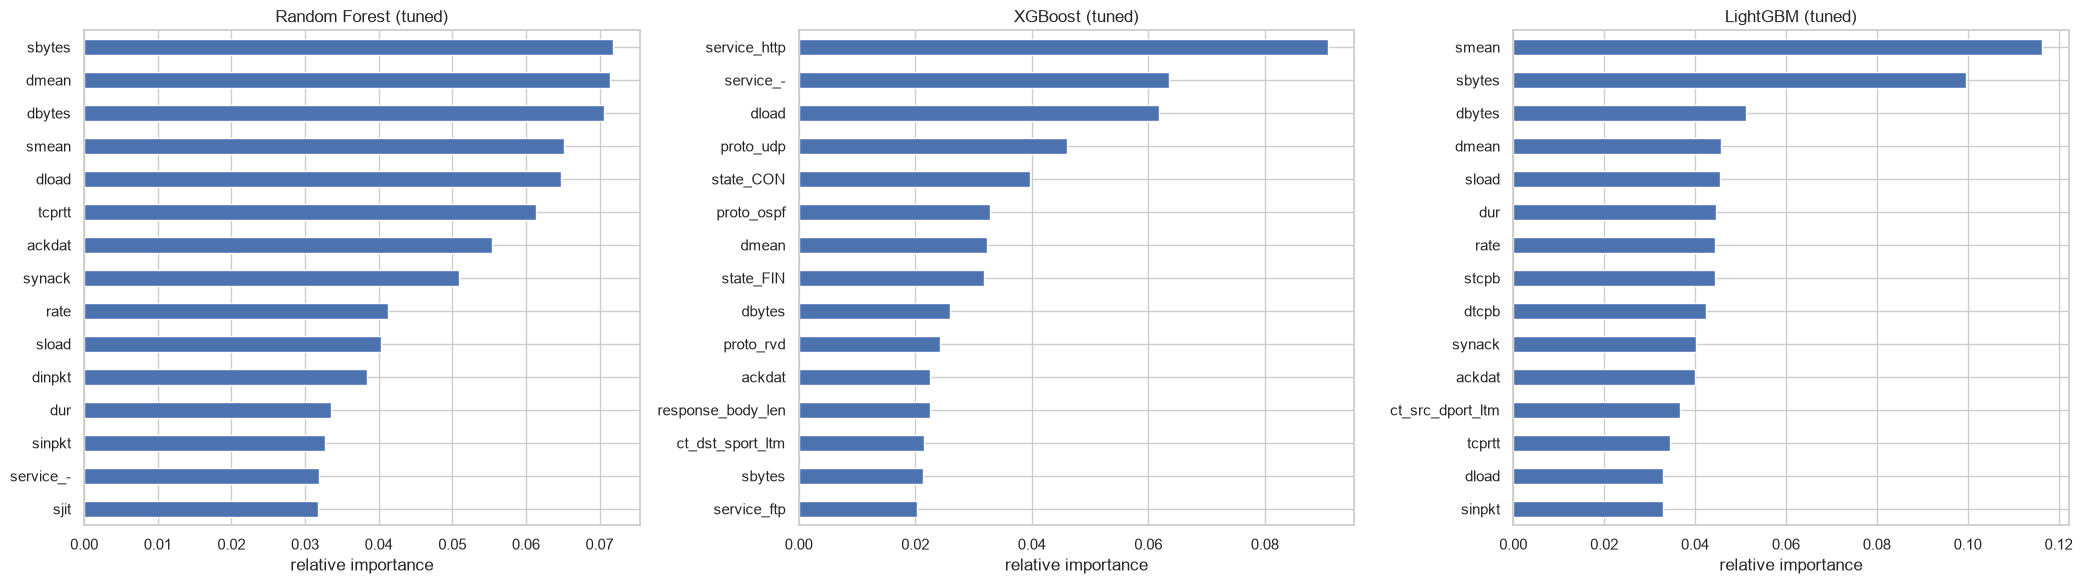

In [62]:
best_rf = fitted_models[f"Random Forest (tuned) [{TUNED_STRATEGY}]"]
best_xgb = fitted_models[f"XGBoost (tuned) [{TUNED_STRATEGY}]"]
best_lgbm = fitted_models[f"LightGBM (tuned) [{TUNED_STRATEGY}]"]

importances = {
    "Random Forest (tuned)": pd.Series(best_rf.feature_importances_, index=feature_columns_selected),
    "XGBoost (tuned)": pd.Series(best_xgb.feature_importances_, index=feature_columns_selected),
    "LightGBM (tuned)": pd.Series(best_lgbm.feature_importances_, index=feature_columns_selected),
}
fig, axes = plt.subplots(1, 3, figsize=(21, 6))
for ax, (name, imp) in zip(axes, importances.items()):
    (imp / imp.sum()).sort_values(ascending=True).tail(15).plot(kind="barh", ax=ax, title=name)
    ax.set_xlabel("relative importance")
plt.tight_layout(); plt.show()

In [63]:
# Features that all three models rank in their top 15
top15 = [set(((imp / imp.sum()).sort_values(ascending=False)).head(15).index) for imp in importances.values()]
print("Top-15 in all three models:", sorted(set.intersection(*top15)))

Top-15 in all three models: ['ackdat', 'dbytes', 'dload', 'dmean', 'sbytes']


## 22. SHAP Explainability

`TreeExplainer` on the tuned Random Forest. For a multiclass model SHAP produces **one set of values per class** (array shape `samples × features × classes`). The explained sample is
**stratified** — up to `SHAP_PER_CLASS` validation flows per class — so rare classes such as `Worms` are represented in the class-wise plots.

1. **Global** — mean |SHAP| per feature, stacked by class.
2. **Class-wise** — top features per class and one beeswarm per class (which feature values push a flow *toward* that class?).
3. **Local** — waterfall plots explaining single predictions.

In [64]:
SHAP_PER_CLASS = 30
rng = np.random.RandomState(RANDOM_STATE)
shap_idx = np.concatenate([
    rng.choice(np.where(y_val_arr == k)[0], min(SHAP_PER_CLASS, int((y_val_arr == k).sum())), replace=False)
    for k in range(n_classes)
])
shap_sample = pd.DataFrame(X_val_sel[shap_idx], columns=feature_columns_selected)
shap_y = y_val_arr[shap_idx]

explainer = shap.TreeExplainer(best_rf)
sv = explainer.shap_values(shap_sample, check_additivity=False)

# Normalise across SHAP versions -> (samples, features, classes)
sv = np.stack(sv, axis=-1) if isinstance(sv, list) else np.asarray(sv)
print("SHAP values shape (samples, features, classes):", sv.shape)

SHAP values shape (samples, features, classes): (295, 176, 10)


### 22.1 Global explanation

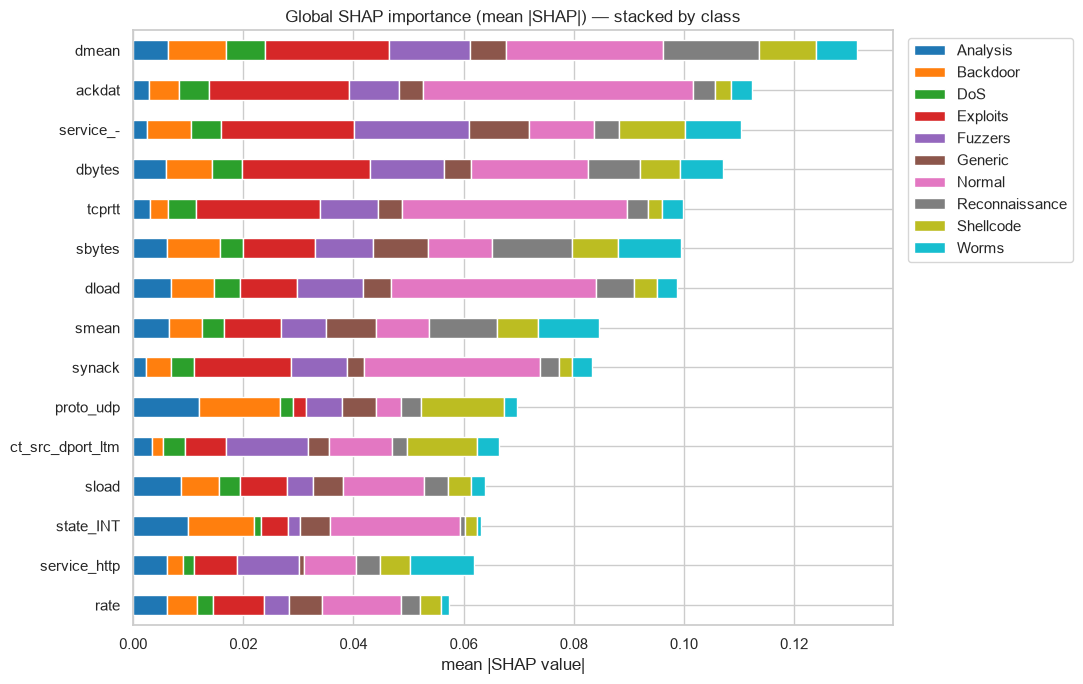

In [65]:
mean_abs = pd.DataFrame(np.abs(sv).mean(axis=0), index=feature_columns_selected, columns=class_names)
top_features = mean_abs.sum(axis=1).sort_values(ascending=False).head(15).index

mean_abs.loc[top_features].iloc[::-1].plot(kind="barh", stacked=True, figsize=(11, 7), colormap="tab10")
plt.title("Global SHAP importance (mean |SHAP|) — stacked by class")
plt.xlabel("mean |SHAP value|"); plt.legend(bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout(); plt.show()

### 22.2 Class-wise explanation

In [66]:
# Top-5 features per class (mean |SHAP| for that class)
pd.DataFrame({c: mean_abs[c].sort_values(ascending=False).head(5).index.tolist() for c in class_order},
             index=[f"#{i}" for i in range(1, 6)]).T

,#1,#2,#3,#4,#5
Normal,ackdat,tcprtt,dload,synack,dmean
Generic,service_dns,service_-,sbytes,smean,dmean
Exploits,ackdat,service_-,dbytes,tcprtt,dmean
Fuzzers,service_-,ct_src_dport_ltm,dmean,dbytes,dload
DoS,dmean,dbytes,service_-,ackdat,tcprtt
Reconnaissance,dmean,sbytes,smean,dbytes,sjit
Analysis,proto_udp,state_INT,sload,ct_dst_sport_ltm,response_body_len
Backdoor,proto_udp,state_INT,dmean,sbytes,dbytes
Shellcode,proto_udp,ct_src_dport_ltm,service_-,dmean,sbytes
Worms,service_http,sbytes,smean,service_-,ct_flw_http_mthd


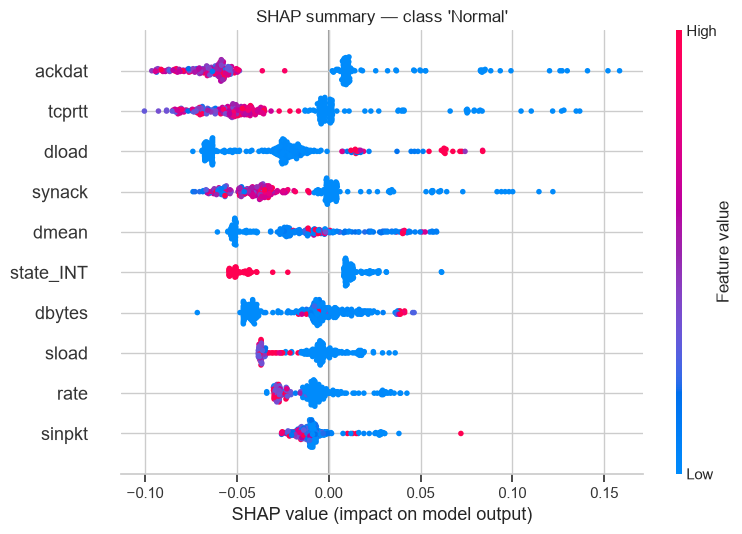

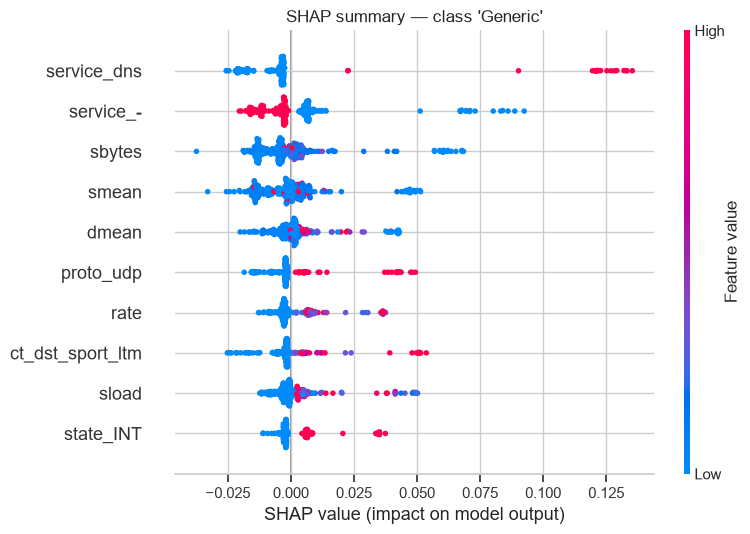

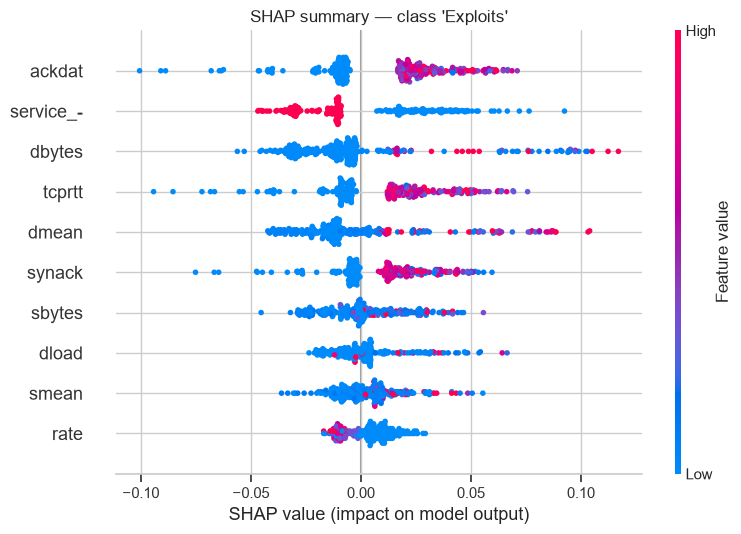

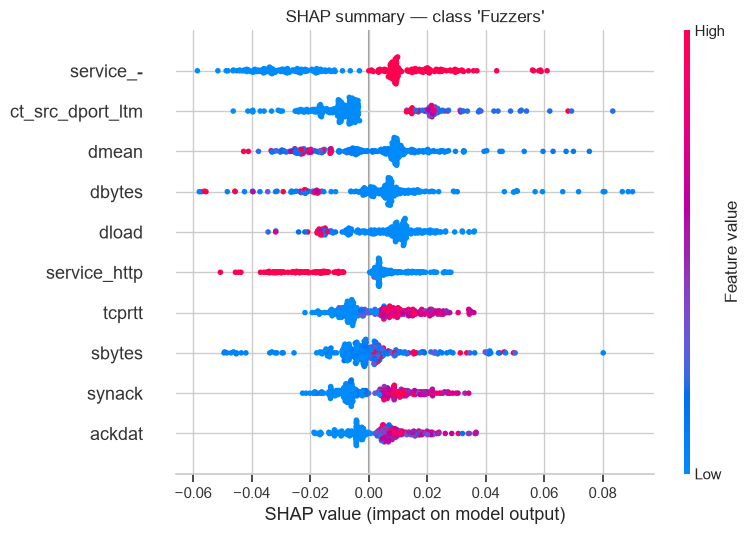

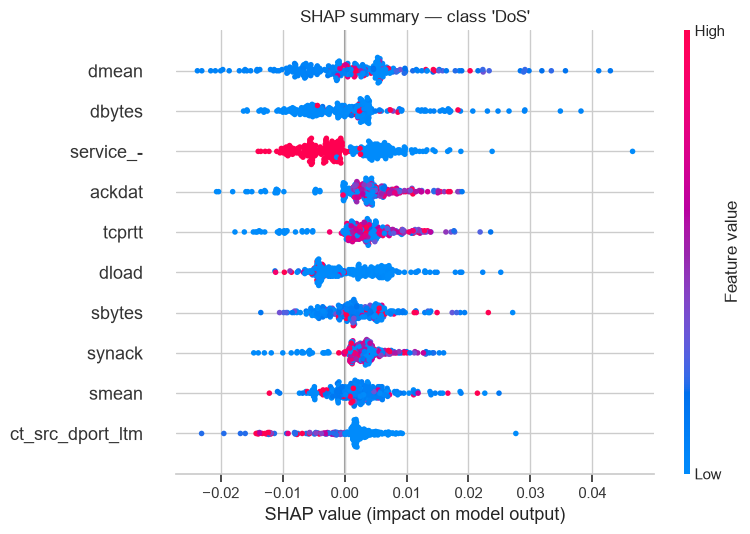

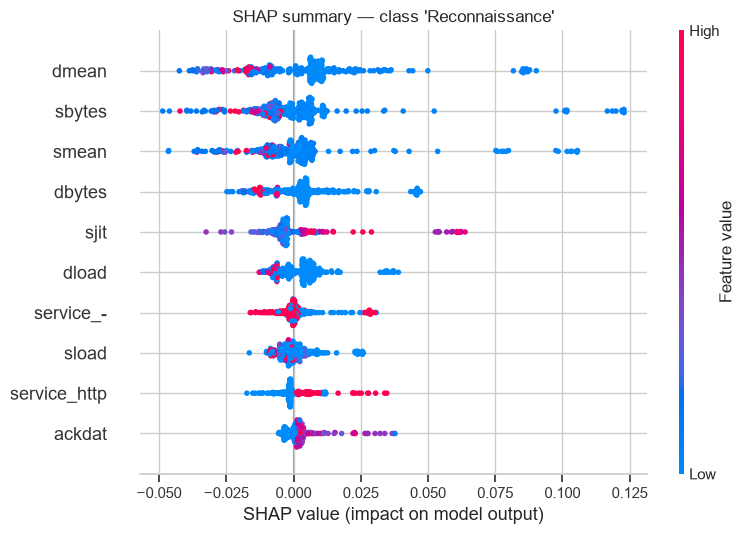

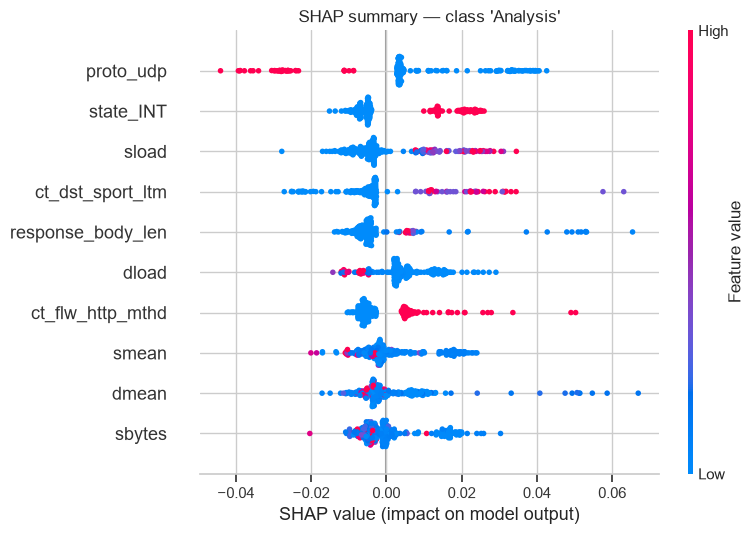

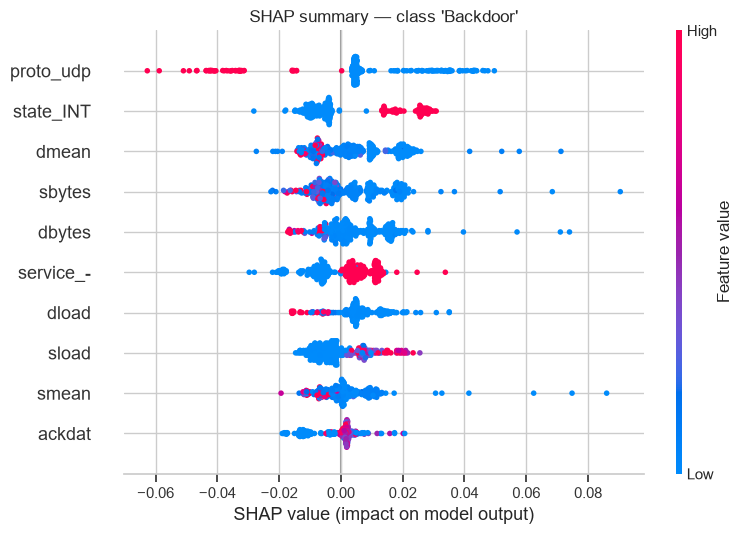

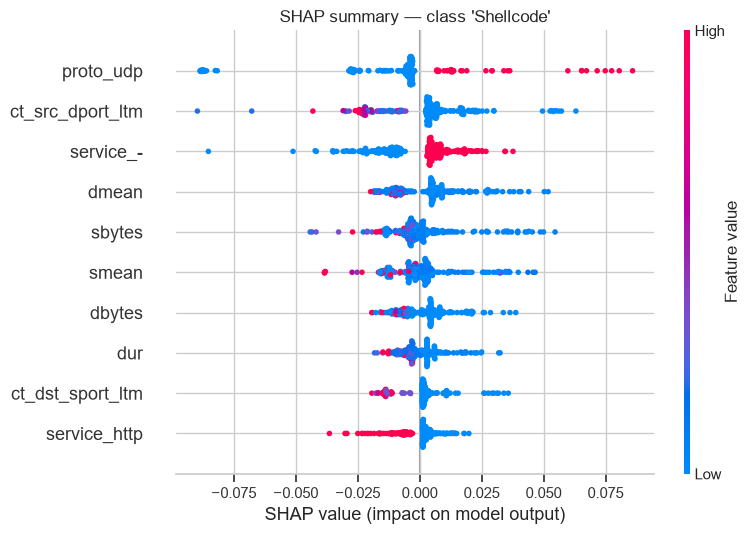

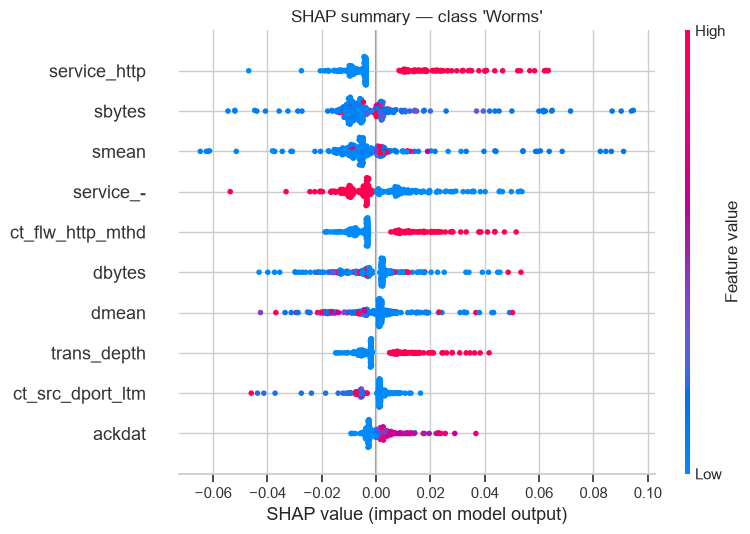

In [67]:
for cls in class_order:
    k = class_names.index(cls)
    plt.figure()
    shap.summary_plot(sv[:, :, k], shap_sample, max_display=10, show=False)
    plt.title(f"SHAP summary — class '{cls}'")
    plt.tight_layout(); plt.show()

### 22.3 Local explanation

Random flow — actual: Analysis | predicted: Backdoor (p = 0.26)


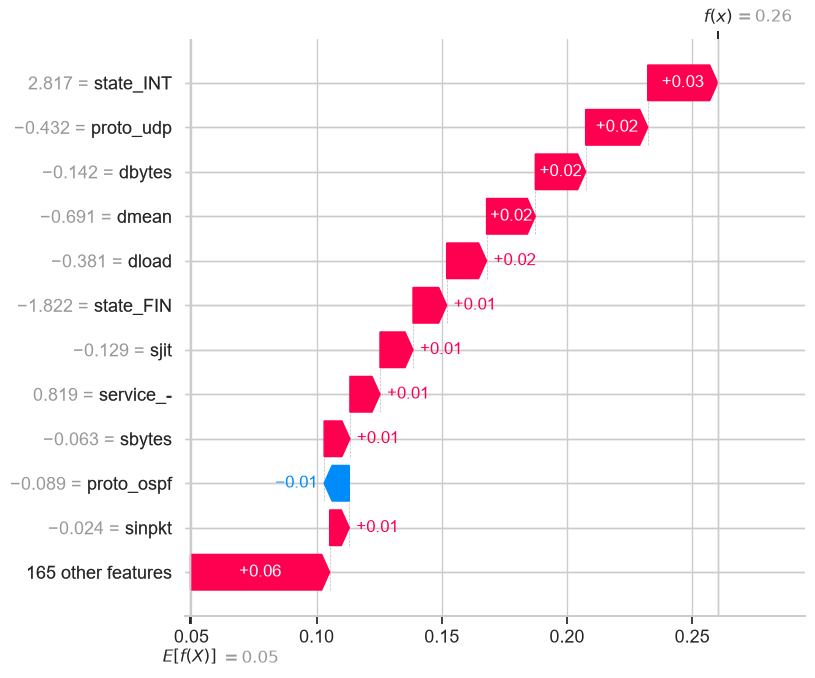

In [68]:
def explain_instance(i, title=""):
    """Waterfall for the class the model actually predicted for shap_sample row i."""
    proba_i = best_rf.predict_proba(shap_sample.iloc[[i]].to_numpy())[0]
    pred_k = int(np.argmax(proba_i))
    print(f"{title}actual: {class_names[shap_y[i]]} | predicted: {class_names[pred_k]} (p = {proba_i[pred_k]:.2f})")
    base_values = np.atleast_1d(explainer.expected_value)
    explanation = shap.Explanation(
        values=sv[i, :, pred_k], base_values=base_values[pred_k],
        data=shap_sample.iloc[i].to_numpy(), feature_names=feature_columns_selected,
    )
    shap.plots.waterfall(explanation, max_display=12, show=True)

explain_instance(0, "Random flow — ")

Rarest class (Worms) — actual: Worms | predicted: Worms (p = 0.37)


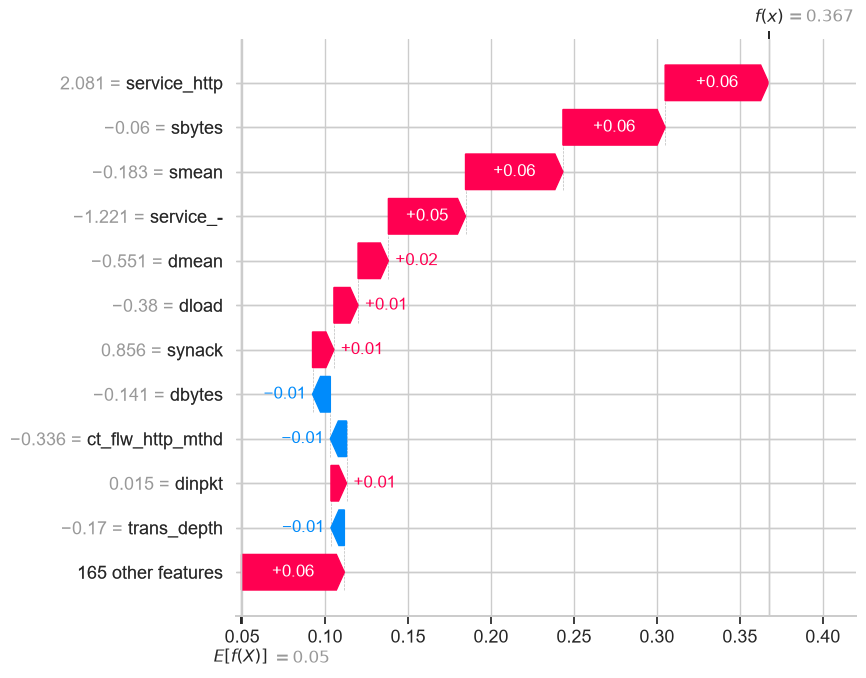

In [69]:
# The rarest class in the training data: is a real flow of that class explained sensibly?
rarest_k = int(counts.idxmin())
explain_instance(int(np.where(shap_y == rarest_k)[0][0]), f"Rarest class ({class_names[rarest_k]}) — ")

## 23. Multiclass Evaluation (Validation Split)

Every model is scored with the full metric set: accuracy, macro precision / recall / F1, weighted F1, one-vs-rest ROC-AUC and PR-AUC.
Diagnostics — classification report, confusion matrices, ROC and precision-recall curves — are shown for the current leader by macro-F1 among models that output probabilities.

In [70]:
val_table = results_table()
EVAL_COLS = ["accuracy", "precision_macro", "recall_macro", "f1_macro", "f1_weighted", "roc_auc_ovr", "pr_auc_macro"]
val_table[["strategy"] + EVAL_COLS].sort_values("f1_macro", ascending=False).round(4)

,strategy,accuracy,precision_macro,recall_macro,f1_macro,f1_weighted,roc_auc_ovr,pr_auc_macro
"Voting Ensemble (hard, tuned) [SMOTE]",SMOTE,0.8084,0.5724,0.6068,0.5542,0.8159,NaN,NaN
"Voting Ensemble (soft, tuned) [SMOTE]",SMOTE,0.8090,0.5712,0.6008,0.5513,0.8168,0.9707,0.5826
XGBoost [SMOTE],SMOTE,0.8070,0.5580,0.6134,0.5501,0.8146,0.9687,0.5873
LightGBM (tuned) [SMOTE],SMOTE,0.8095,0.5547,0.5980,0.5501,0.8163,0.9701,0.5916
XGBoost (tuned) [SMOTE],SMOTE,0.8059,0.5565,0.6124,0.5487,0.8139,0.9708,0.5880
LightGBM [GAN],GAN,0.8094,0.5899,0.5141,0.5371,0.8061,0.9713,0.6089
LightGBM [SMOTE],SMOTE,0.8072,0.5403,0.5557,0.5355,0.8133,0.9672,0.5816
"Voting Ensemble (soft, RF+XGB+LGBM) [SMOTE]",SMOTE,0.8062,0.5452,0.5552,0.5352,0.8130,0.9682,0.5749
XGBoost [GAN],GAN,0.8130,0.5924,0.5111,0.5326,0.8076,0.9729,0.6161
XGBoost [Original],Original,0.8135,0.6002,0.4985,0.5261,0.8058,0.9701,0.6183


In [71]:
proba_capable = [n for n, m in fitted_models.items() if hasattr(m, "predict_proba")]
leader_name = val_table.loc[proba_capable, "f1_macro"].idxmax()
leader = fitted_models[leader_name]
y_val_pred = leader.predict(X_val_sel)
y_val_proba = leader.predict_proba(X_val_sel)

print(f"Leader on validation macro-F1: {leader_name}\n")
print(classification_report(y_val_arr, y_val_pred, target_names=class_names, zero_division=0, digits=3))

Leader on validation macro-F1: Voting Ensemble (soft, tuned) [SMOTE]

                precision    recall  f1-score   support

      Analysis      0.138     0.411     0.207       224
      Backdoor      0.163     0.411     0.234       224
           DoS      0.623     0.177     0.275       674
      Exploits      0.835     0.831     0.833      3872
       Fuzzers      0.699     0.719     0.709      2816
       Generic      0.843     0.658     0.739       360
        Normal      0.933     0.906     0.920      9779
Reconnaissance      0.864     0.736     0.795      1200
     Shellcode      0.372     0.681     0.481       191
         Worms      0.240     0.480     0.320        25

      accuracy                          0.809     19365
     macro avg      0.571     0.601     0.551     19365
  weighted avg      0.838     0.809     0.817     19365



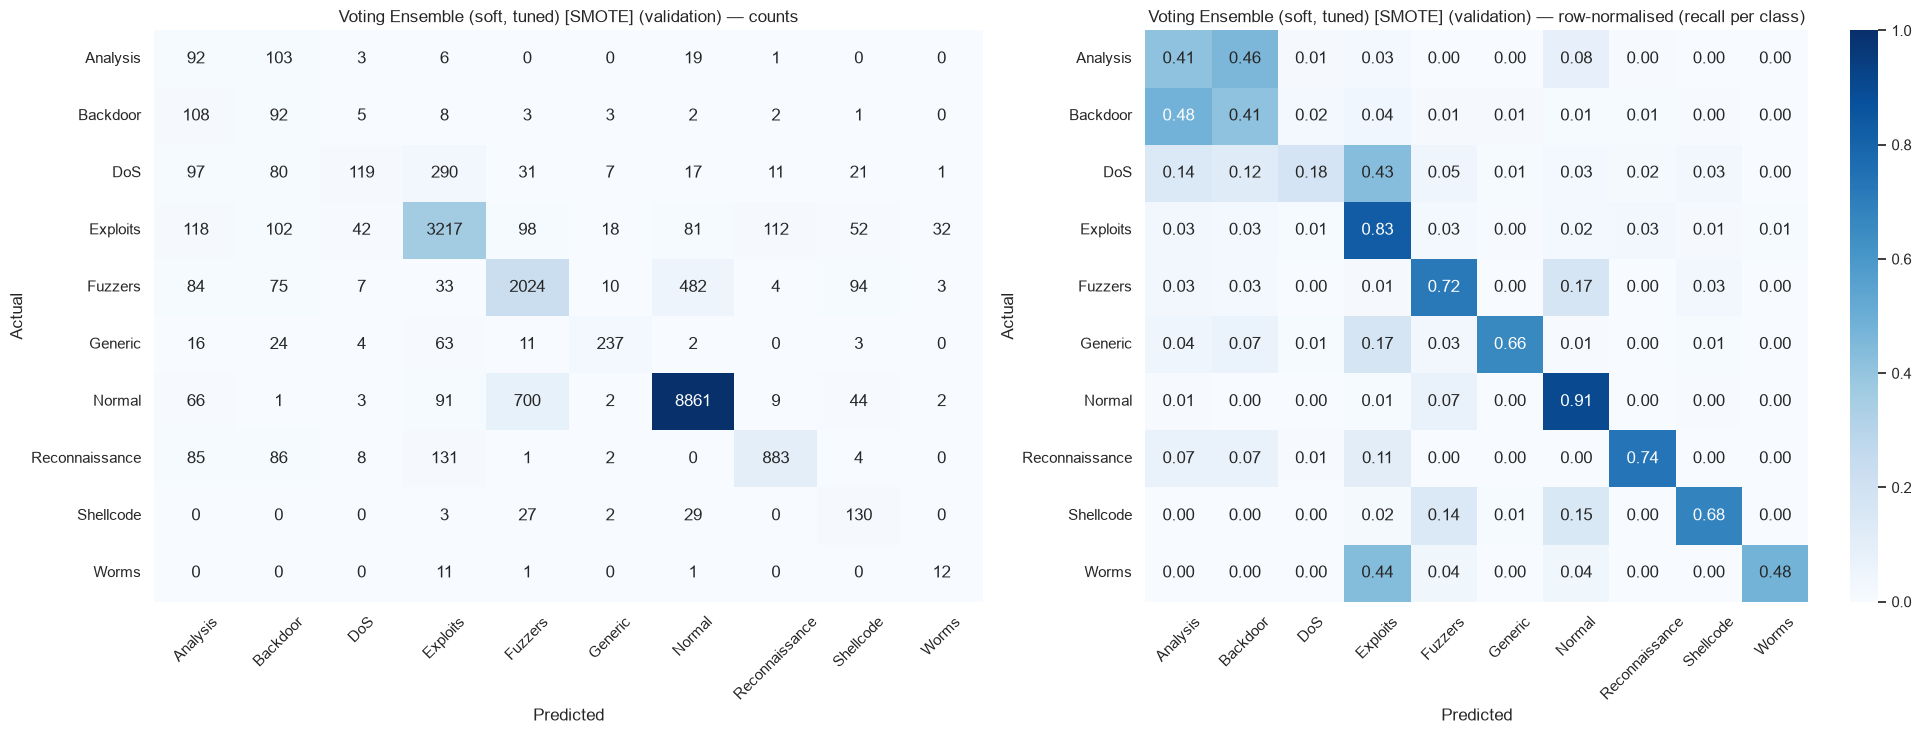

In [72]:
def plot_confusion(y_true, y_pred, title):
    cm = confusion_matrix(y_true, y_pred, labels=range(n_classes))
    cm_norm = cm / np.maximum(cm.sum(axis=1, keepdims=True), 1)
    fig, axes = plt.subplots(1, 2, figsize=(20, 7.5))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=class_names, yticklabels=class_names, ax=axes[0], cbar=False)
    axes[0].set_title(f"{title} — counts")
    sns.heatmap(cm_norm, annot=True, fmt=".2f", cmap="Blues", xticklabels=class_names, yticklabels=class_names, ax=axes[1], vmin=0, vmax=1)
    axes[1].set_title(f"{title} — row-normalised (recall per class)")
    for ax in axes:
        ax.set_xlabel("Predicted"); ax.set_ylabel("Actual"); ax.tick_params(axis="x", rotation=45)
    plt.tight_layout(); plt.show()

def plot_curves(y_true, proba, title):
    y_bin = label_binarize(y_true, classes=range(n_classes))
    fig, axes = plt.subplots(1, 2, figsize=(16, 6))
    for k, name in enumerate(class_names):
        fpr_k, tpr_k, _ = roc_curve(y_bin[:, k], proba[:, k])
        axes[0].plot(fpr_k, tpr_k, label=f"{name} (AUC {roc_auc_score(y_bin[:, k], proba[:, k]):.3f})")
        p_k, r_k, _ = precision_recall_curve(y_bin[:, k], proba[:, k])
        axes[1].plot(r_k, p_k, label=f"{name} (AP {average_precision_score(y_bin[:, k], proba[:, k]):.3f})")
    axes[0].plot([0, 1], [0, 1], "--", color="gray")
    axes[0].set(title=f"One-vs-rest ROC — {title}", xlabel="False positive rate", ylabel="True positive rate")
    axes[1].set(title=f"One-vs-rest precision-recall — {title}", xlabel="Recall", ylabel="Precision")
    for ax in axes:
        ax.legend(fontsize=8, loc="lower right" if ax is axes[0] else "lower left")
    plt.tight_layout(); plt.show()

plot_confusion(y_val_arr, y_val_pred, f"{leader_name} (validation)")

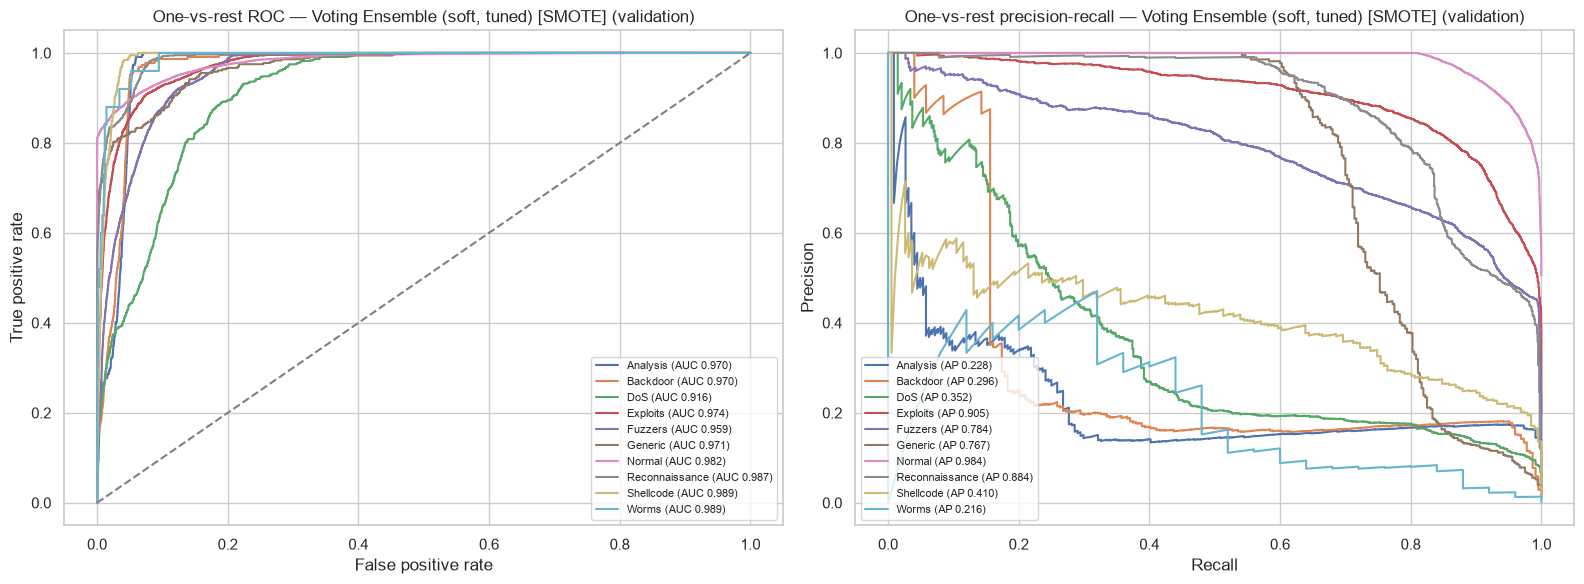

In [73]:
plot_curves(y_val_arr, y_val_proba, f"{leader_name} (validation)")

## 24. Per-Class Evaluation (Validation Split)

Precision, recall, F1, false-positive rate and one-vs-rest ROC-AUC / average precision for each class of the current leader, listed in the order
`Normal → Generic → Exploits → Fuzzers → DoS → Reconnaissance → Analysis → Backdoor → Shellcode → Worms`.

In [74]:
def per_class_table(y_true, y_pred, proba=None):
    labels = np.arange(n_classes)
    cm = confusion_matrix(y_true, y_pred, labels=labels)
    tp = np.diag(cm); fp = cm.sum(axis=0) - tp; fn = cm.sum(axis=1) - tp; tn = cm.sum() - tp - fp - fn
    rep = pd.DataFrame(classification_report(y_true, y_pred, labels=labels, target_names=class_names,
                                             output_dict=True, zero_division=0)).T.loc[class_names]
    out = pd.DataFrame({"precision": rep["precision"], "recall": rep["recall"], "f1": rep["f1-score"],
                        "support": rep["support"].astype(int), "fpr": fp / np.maximum(fp + tn, 1)}, index=class_names)
    off = cm.copy(); np.fill_diagonal(off, 0)
    out["most_confused_with"] = [class_names[int(off[k].argmax())] if off[k].sum() > 0 else "-" for k in labels]
    if proba is not None:
        y_bin = label_binarize(y_true, classes=labels)
        out["roc_auc"] = [roc_auc_score(y_bin[:, k], proba[:, k]) for k in labels]
        out["avg_precision"] = [average_precision_score(y_bin[:, k], proba[:, k]) for k in labels]
    return out.loc[class_order]

leader_per_class = per_class_table(y_val_arr, y_val_pred, y_val_proba)
print("Per-class results —", leader_name)
leader_per_class.round(3)

Per-class results — Voting Ensemble (soft, tuned) [SMOTE]


,precision,recall,f1,support,fpr,most_confused_with,roc_auc,avg_precision
Normal,0.933,0.906,0.920,9779,0.066,Fuzzers,0.982,0.984
Generic,0.843,0.658,0.739,360,0.002,Exploits,0.971,0.767
Exploits,0.835,0.831,0.833,3872,0.041,Analysis,0.974,0.905
Fuzzers,0.699,0.719,0.709,2816,0.053,Normal,0.959,0.784
DoS,0.623,0.177,0.275,674,0.004,Exploits,0.916,0.352
Reconnaissance,0.864,0.736,0.795,1200,0.008,Exploits,0.987,0.884
Analysis,0.138,0.411,0.207,224,0.030,Backdoor,0.970,0.228
Backdoor,0.163,0.411,0.234,224,0.025,Analysis,0.970,0.296
Shellcode,0.372,0.681,0.481,191,0.011,Normal,0.989,0.410
Worms,0.240,0.480,0.320,25,0.002,Exploits,0.989,0.216


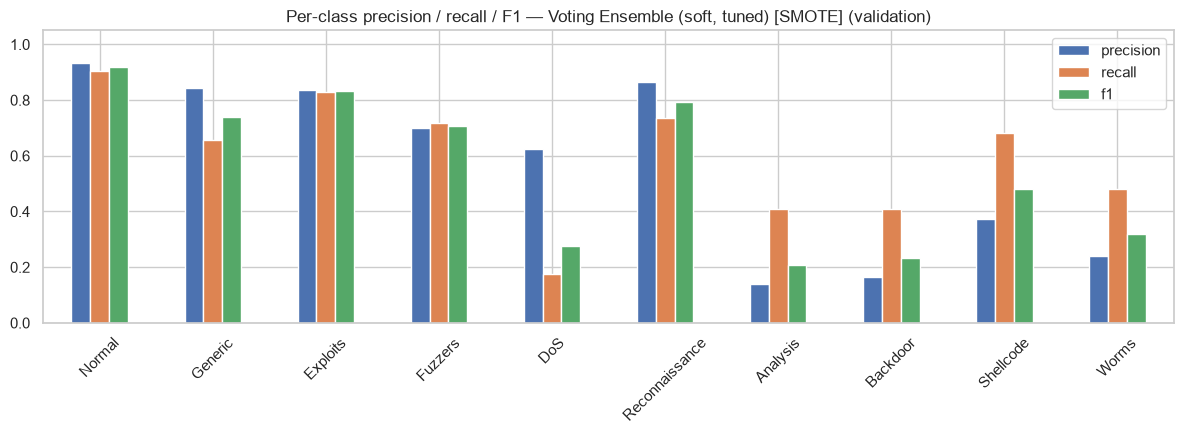

In [75]:
leader_per_class[["precision", "recall", "f1"]].plot(kind="bar", figsize=(12, 4.5), ylim=(0, 1.05),
                                                     title=f"Per-class precision / recall / F1 — {leader_name} (validation)")
plt.xticks(rotation=45); plt.tight_layout(); plt.show()

In [76]:
# One line per class, in reporting order
for cls, r in leader_per_class.iterrows():
    print(f"{cls:15s} precision {r['precision']:.3f} | recall {r['recall']:.3f} | F1 {r['f1']:.3f} | "
          f"support {int(r['support']):6d} | mostly confused with: {r['most_confused_with']}")

Normal          precision 0.933 | recall 0.906 | F1 0.920 | support   9779 | mostly confused with: Fuzzers
Generic         precision 0.843 | recall 0.658 | F1 0.739 | support    360 | mostly confused with: Exploits
Exploits        precision 0.835 | recall 0.831 | F1 0.833 | support   3872 | mostly confused with: Analysis
Fuzzers         precision 0.699 | recall 0.719 | F1 0.709 | support   2816 | mostly confused with: Normal
DoS             precision 0.623 | recall 0.177 | F1 0.275 | support    674 | mostly confused with: Exploits
Reconnaissance  precision 0.864 | recall 0.736 | F1 0.795 | support   1200 | mostly confused with: Exploits
Analysis        precision 0.138 | recall 0.411 | F1 0.207 | support    224 | mostly confused with: Backdoor
Backdoor        precision 0.163 | recall 0.411 | F1 0.234 | support    224 | mostly confused with: Analysis
Shellcode       precision 0.372 | recall 0.681 | F1 0.481 | support    191 | mostly confused with: Normal
Worms           precision 0.240 |

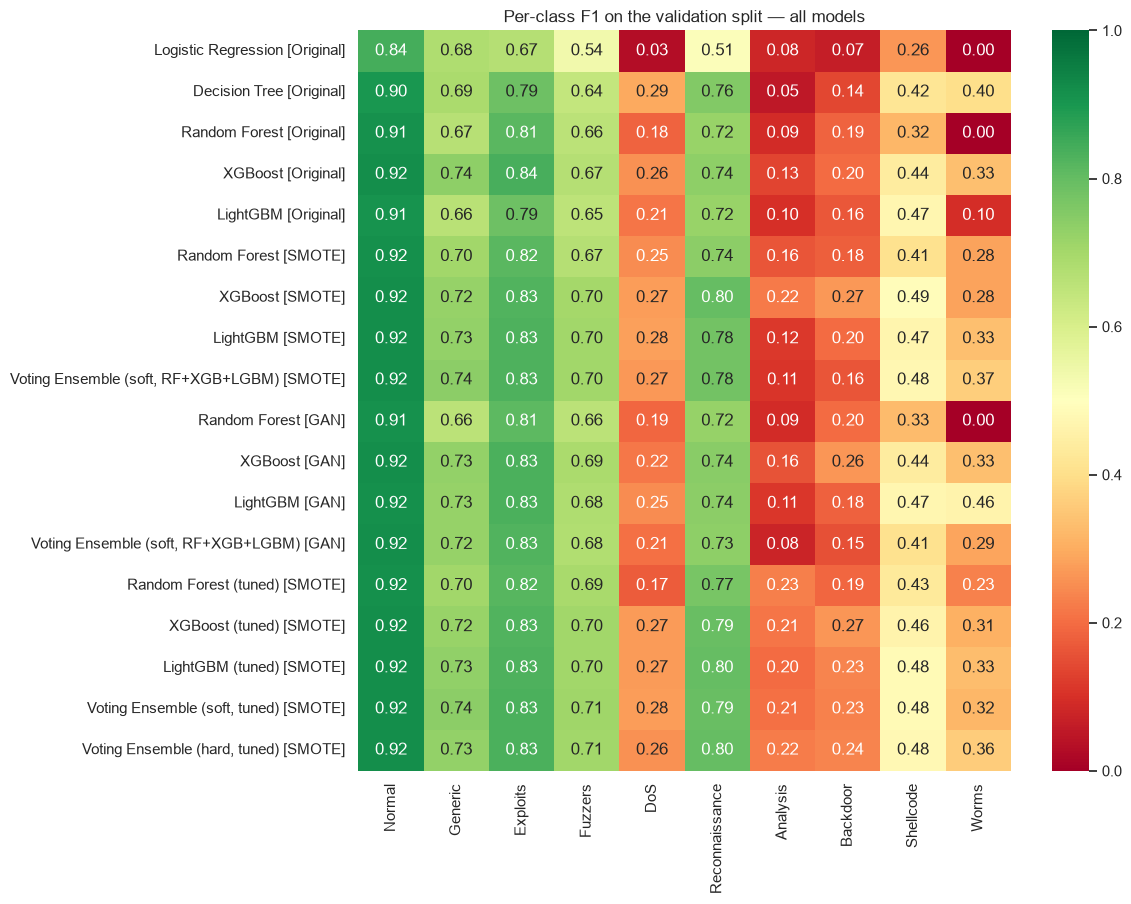

In [77]:
# Where is each model strong or weak? Per-class F1 of EVERY model on the validation split
per_class_f1_val = pd.DataFrame(
    {name: f1_score(y_val_arr, m.predict(X_val_sel), average=None, labels=range(n_classes), zero_division=0)
     for name, m in fitted_models.items()}, index=class_names).T[class_order]

plt.figure(figsize=(12, 0.4 * len(per_class_f1_val) + 2))
sns.heatmap(per_class_f1_val, annot=True, fmt=".2f", cmap="RdYlGn", vmin=0, vmax=1)
plt.title("Per-class F1 on the validation split — all models"); plt.tight_layout(); plt.show()

## 25. Original vs SMOTE vs GAN

Like-for-like comparison: the same models with the same (untuned) hyper-parameters, trained on the original, SMOTE-balanced or GAN-balanced training set, scored on the **same real validation split**.
The tuned models are left out here because they were fitted on a single strategy.

In [78]:
STRATEGIES = ["Original", "SMOTE", "GAN"]
CMP_MODELS = CORE_MODELS + [ENSEMBLE_SOFT]          # no Original ensemble was trained -> NaN in that cell

def strategy_pivot(table, metric):
    sub = table[table["model"].isin(CMP_MODELS)]
    return sub.pivot(index="model", columns="strategy", values=metric).reindex(index=CMP_MODELS, columns=STRATEGIES)

for metric in ["f1_macro", "recall_macro", "minority_f1", "macro_fpr", "accuracy"]:
    print(f"\n{metric}")
    display(strategy_pivot(val_table, metric).round(4))


f1_macro


strategy,Original,SMOTE,GAN
model,,,
Random Forest,0.4551,0.5121,0.4572
XGBoost,0.5261,0.5501,0.5326
LightGBM,0.4779,0.5355,0.5371
"Voting Ensemble (soft, RF+XGB+LGBM)",NaN,0.5352,0.5008



recall_macro


strategy,Original,SMOTE,GAN
model,,,
Random Forest,0.4382,0.5256,0.4416
XGBoost,0.4985,0.6134,0.5111
LightGBM,0.4781,0.5557,0.5141
"Voting Ensemble (soft, RF+XGB+LGBM)",NaN,0.5552,0.4754



minority_f1


strategy,Original,SMOTE,GAN
model,,,
Random Forest,0.2408,0.3304,0.2441
XGBoost,0.3495,0.3762,0.3567
LightGBM,0.2841,0.3539,0.3661
"Voting Ensemble (soft, RF+XGB+LGBM)",NaN,0.3527,0.3086



macro_fpr


strategy,Original,SMOTE,GAN
model,,,
Random Forest,0.0270,0.0262,0.0271
XGBoost,0.0250,0.0245,0.0249
LightGBM,0.0283,0.0247,0.0252
"Voting Ensemble (soft, RF+XGB+LGBM)",NaN,0.0247,0.0257



accuracy


strategy,Original,SMOTE,GAN
model,,,
Random Forest,0.7970,0.7963,0.7967
XGBoost,0.8135,0.8070,0.8130
LightGBM,0.7863,0.8072,0.8094
"Voting Ensemble (soft, RF+XGB+LGBM)",NaN,0.8062,0.8066


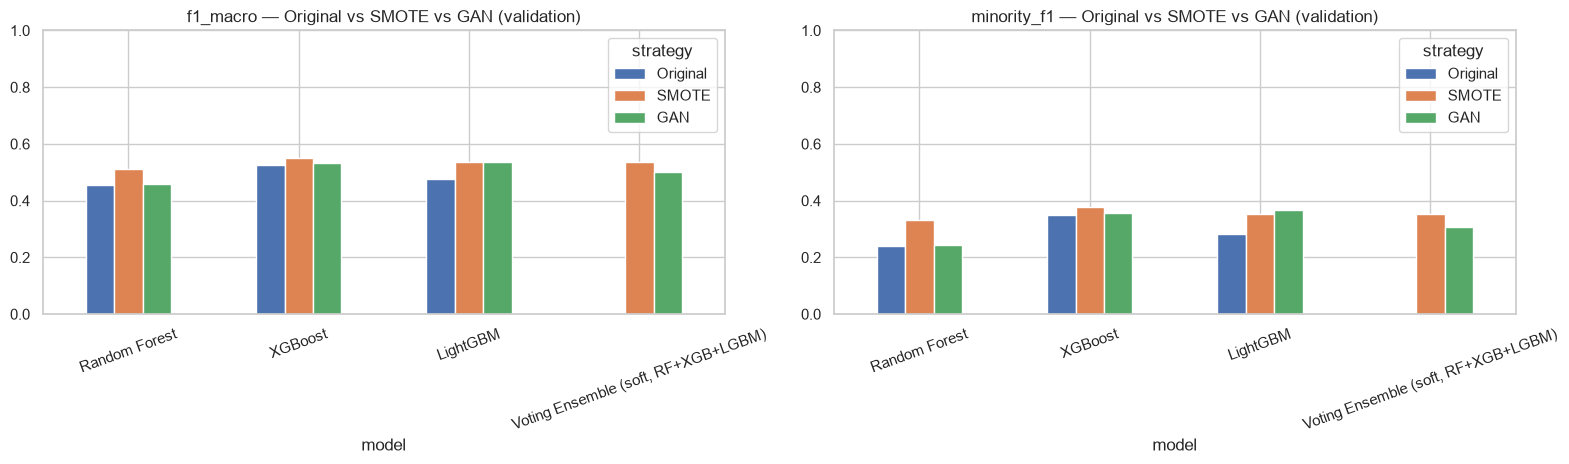

In [79]:
fig, axes = plt.subplots(1, 2, figsize=(16, 4.8))
for ax, metric in zip(axes, ["f1_macro", "minority_f1"]):
    strategy_pivot(val_table, metric).plot(kind="bar", ax=ax, title=f"{metric} — Original vs SMOTE vs GAN (validation)")
    ax.set_ylim(0, 1); ax.tick_params(axis="x", rotation=20)
plt.tight_layout(); plt.show()

In [80]:
def strategy_summary(table):
    """Mean over RF / XGBoost / LightGBM (untuned) per strategy."""
    sub = table[table["model"].isin(CORE_MODELS)]
    return sub.groupby("strategy")[["f1_macro", "recall_macro", "minority_f1", "macro_fpr", "accuracy"]].mean().reindex(STRATEGIES)

strategy_summary_val = strategy_summary(val_table)
print("Mean over RF / XGBoost / LightGBM — validation")
strategy_summary_val.round(4)

Mean over RF / XGBoost / LightGBM — validation


,f1_macro,recall_macro,minority_f1,macro_fpr,accuracy
strategy,,,,,
Original,0.4864,0.4716,0.2915,0.0268,0.7989
SMOTE,0.5326,0.5649,0.3535,0.0252,0.8035
GAN,0.5090,0.4890,0.3223,0.0257,0.8064


Best model per strategy: {'Original': 'XGBoost [Original]', 'SMOTE': 'XGBoost [SMOTE]', 'GAN': 'LightGBM [GAN]'}


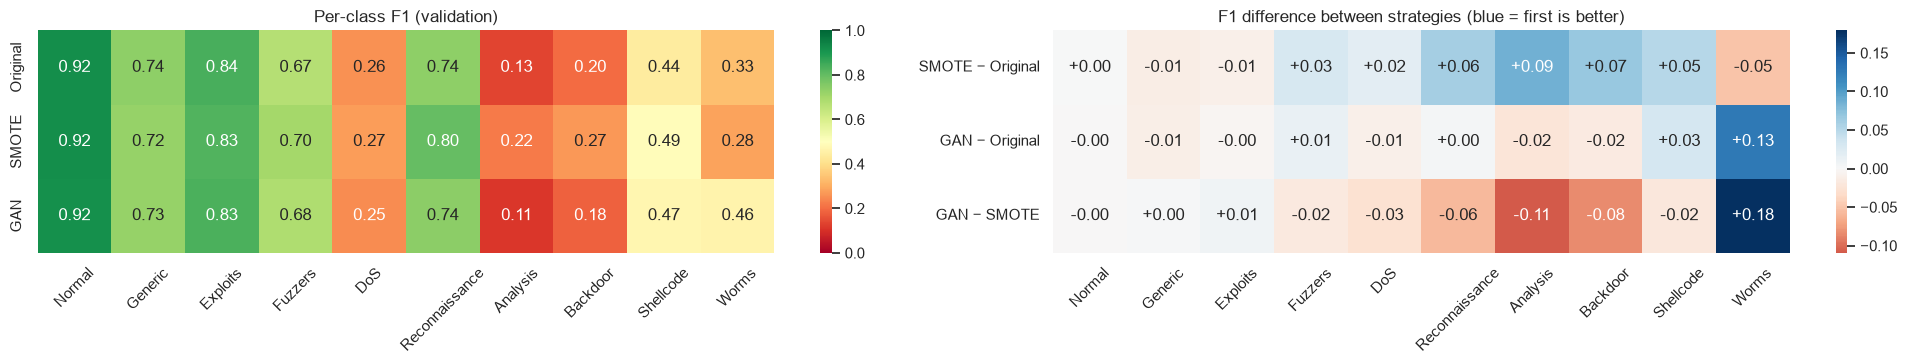

In [81]:
# Per-class F1: the best untuned model of each strategy (by validation macro-F1)
cmp_only = val_table[val_table["model"].isin(CMP_MODELS)]
best_by_strategy = {s: cmp_only[cmp_only["strategy"] == s]["f1_macro"].idxmax() for s in STRATEGIES}
print("Best model per strategy:", best_by_strategy)

per_class_by_strategy = pd.DataFrame(
    {s: f1_score(y_val_arr, fitted_models[n].predict(X_val_sel), average=None, labels=range(n_classes), zero_division=0)
     for s, n in best_by_strategy.items()}, index=class_names).T[class_order]

delta = pd.DataFrame({"SMOTE − Original": per_class_by_strategy.loc["SMOTE"] - per_class_by_strategy.loc["Original"],
                      "GAN − Original": per_class_by_strategy.loc["GAN"] - per_class_by_strategy.loc["Original"],
                      "GAN − SMOTE": per_class_by_strategy.loc["GAN"] - per_class_by_strategy.loc["SMOTE"]}).T

fig, axes = plt.subplots(1, 2, figsize=(20, 3.8), gridspec_kw={"width_ratios": [1, 1]})
sns.heatmap(per_class_by_strategy, annot=True, fmt=".2f", cmap="RdYlGn", vmin=0, vmax=1, ax=axes[0])
axes[0].set_title("Per-class F1 (validation)")
sns.heatmap(delta, annot=True, fmt="+.2f", cmap="RdBu", center=0, ax=axes[1])
axes[1].set_title("F1 difference between strategies (blue = first is better)")
for ax in axes: ax.tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.show()

## 26. Final Evaluation on the UNSW-NB15 Test Set

All models are scored once on the official held-out test file. These numbers are **for reporting only** — the final model in Step 27 is chosen from the validation results, so the test set never drives a decision.

The official test file is not just a random slice of the training file: its class mix is different (for example far more `Generic` flows), so lower scores than on validation are expected and reflect distribution shift.

In [82]:
test_results = {name: evaluate_model(model, X_test_sel, y_test_arr) for name, model in fitted_models.items()}
test_table = results_table(test_results)
test_table[["strategy"] + EVAL_COLS].sort_values("f1_macro", ascending=False).round(4)

,strategy,accuracy,precision_macro,recall_macro,f1_macro,f1_weighted,roc_auc_ovr,pr_auc_macro
LightGBM [GAN],GAN,0.7525,0.5396,0.5552,0.5028,0.7728,0.9618,0.5479
"Voting Ensemble (soft, RF+XGB+LGBM) [SMOTE]",SMOTE,0.7405,0.5166,0.6041,0.4969,0.7714,0.9579,0.5240
LightGBM [SMOTE],SMOTE,0.7450,0.5081,0.5894,0.4951,0.7729,0.9597,0.5249
LightGBM (tuned) [SMOTE],SMOTE,0.7414,0.5015,0.6116,0.4924,0.7727,0.9593,0.5269
XGBoost [GAN],GAN,0.7548,0.5251,0.5364,0.4894,0.7786,0.9602,0.5432
"Voting Ensemble (soft, RF+XGB+LGBM) [GAN]",GAN,0.7565,0.5305,0.5253,0.4882,0.7781,0.9599,0.5409
XGBoost [Original],Original,0.7543,0.5343,0.5150,0.4833,0.7717,0.9612,0.5527
XGBoost [SMOTE],SMOTE,0.7351,0.4873,0.6101,0.4797,0.7684,0.9579,0.5233
"Voting Ensemble (hard, tuned) [SMOTE]",SMOTE,0.7272,0.4955,0.5974,0.4740,0.7636,NaN,NaN
Decision Tree [Original],Original,0.7216,0.4970,0.5332,0.4715,0.7565,0.8225,0.3936


In [83]:
# Original vs SMOTE vs GAN on the test set
for metric in ["f1_macro", "recall_macro", "minority_f1"]:
    print(f"\n{metric} — test")
    display(strategy_pivot(test_table, metric).round(4))

strategy_summary_test = strategy_summary(test_table)
print("\nMean over RF / XGBoost / LightGBM — test")
strategy_summary_test.round(4)


f1_macro — test


strategy,Original,SMOTE,GAN
model,,,
Random Forest,0.4291,0.4624,0.4476
XGBoost,0.4833,0.4797,0.4894
LightGBM,0.4591,0.4951,0.5028
"Voting Ensemble (soft, RF+XGB+LGBM)",NaN,0.4969,0.4882



recall_macro — test


strategy,Original,SMOTE,GAN
model,,,
Random Forest,0.4635,0.5618,0.4795
XGBoost,0.5150,0.6101,0.5364
LightGBM,0.5290,0.5894,0.5552
"Voting Ensemble (soft, RF+XGB+LGBM)",NaN,0.6041,0.5253



minority_f1 — test


strategy,Original,SMOTE,GAN
model,,,
Random Forest,0.2828,0.3275,0.3005
XGBoost,0.3673,0.3302,0.3665
LightGBM,0.3273,0.3567,0.3828
"Voting Ensemble (soft, RF+XGB+LGBM)",NaN,0.3593,0.3603



Mean over RF / XGBoost / LightGBM — test


,f1_macro,recall_macro,minority_f1,macro_fpr,accuracy
strategy,,,,,
Original,0.4572,0.5025,0.3258,0.0289,0.7465
SMOTE,0.4791,0.5871,0.3381,0.0297,0.7357
GAN,0.4799,0.5237,0.3500,0.0280,0.7534


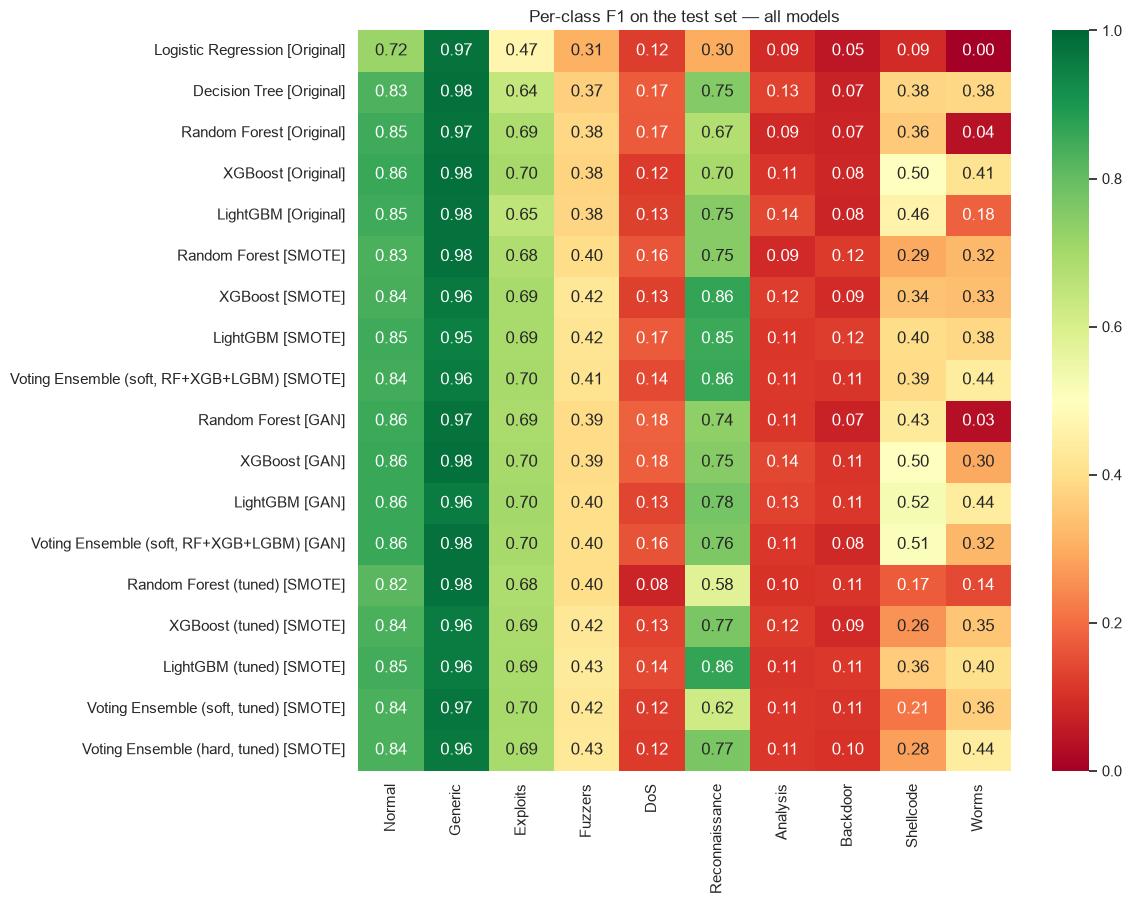

In [84]:
# Per-class F1 on the test set for every model
per_class_f1_test = pd.DataFrame(
    {name: f1_score(y_test_arr, m.predict(X_test_sel), average=None, labels=range(n_classes), zero_division=0)
     for name, m in fitted_models.items()}, index=class_names).T[class_order]

plt.figure(figsize=(12, 0.4 * len(per_class_f1_test) + 2))
sns.heatmap(per_class_f1_test, annot=True, fmt=".2f", cmap="RdYlGn", vmin=0, vmax=1)
plt.title("Per-class F1 on the test set — all models"); plt.tight_layout(); plt.show()

## 27. Model Comparison and Final Model Selection

**Validation vs test** for every model, then the final model is picked from the **validation** results on four criteria that matter for intrusion detection, not on accuracy:

| Criterion | Column | Direction |
|---|---|---|
| Recall | `recall_macro` | higher is better |
| F1-score | `f1_macro` | higher is better |
| False-positive rate | `macro_fpr` | lower is better |
| Minority-class performance | `minority_f1` | higher is better |

Each model is ranked on every criterion; the model with the best **average rank** wins (ties broken by macro-F1). Only models that output class probabilities are candidates (hard voting is listed for comparison but cannot provide the confidence scores and ROC/PR curves used downstream).
`normal_false_alarm_rate` and `attack_miss_rate` are shown next to it as operational sanity checks.

In [85]:
compare = pd.concat({"validation": val_table[["f1_macro", "recall_macro", "accuracy"]],
                     "test": test_table[["f1_macro", "recall_macro", "accuracy"]]}, axis=1)
compare = compare.reindex(val_table.sort_values("f1_macro", ascending=False).index)
compare.round(4)

validation                        \
                                              f1_macro recall_macro accuracy   
Voting Ensemble (hard, tuned) [SMOTE]           0.5542       0.6068   0.8084   
Voting Ensemble (soft, tuned) [SMOTE]           0.5513       0.6008   0.8090   
XGBoost [SMOTE]                                 0.5501       0.6134   0.8070   
LightGBM (tuned) [SMOTE]                        0.5501       0.5980   0.8095   
XGBoost (tuned) [SMOTE]                         0.5487       0.6124   0.8059   
LightGBM [GAN]                                  0.5371       0.5141   0.8094   
LightGBM [SMOTE]                                0.5355       0.5557   0.8072   
Voting Ensemble (soft, RF+XGB+LGBM) [SMOTE]     0.5352       0.5552   0.8062   
XGBoost [GAN]                                   0.5326       0.5111   0.8130   
XGBoost [Original]                              0.5261       0.4985   0.8135   
Random Forest (tuned) [SMOTE]                   0.5161       0.5647   0.7967   
Random Forest [SMOTE]                           0.5121       0.5256   0.7963   
Decision Tree [Original]                        0.5082       0.4971   0.7722   
Voting Ensemble (soft, RF+XGB+LGBM) [GAN]       0.5008       0.4754   0.8066   
LightGBM [Original]                             0.4779       0.4781   0.7863   
Random Forest [GAN]                             0.4572       0.4416   0.7967   
Random Forest [Original]                        0.4551       0.4382   0.7970   
Logistic Regression [Original]                  0.3677       0.3604   0.6921   

                                                test                        
                                            f1_macro recall_macro accuracy  
Voting Ensemble (hard, tuned) [SMOTE]         0.4740       0.5974   0.7272  
Voting Ensemble (soft, tuned) [SMOTE]         0.4468       0.5826   0.7202  
XGBoost [SMOTE]                               0.4797       0.6101   0.7351  
LightGBM (tuned) [SMOTE]                      0.4924       0.6116   0.7414  
XGBoost (tuned) [SMOTE]                       0.4625       0.5963   0.7263  
LightGBM [GAN]                                0.5028       0.5552   0.7525  
LightGBM [SMOTE]                              0.4951       0.5894   0.7450  
Voting Ensemble (soft, RF+XGB+LGBM) [SMOTE]   0.4969       0.6041   0.7405  
XGBoost [GAN]                                 0.4894       0.5364   0.7548  
XGBoost [Original]                            0.4833       0.5150   0.7543  
Random Forest (tuned) [SMOTE]                 0.4069       0.5597   0.7001  
Random Forest [SMOTE]                         0.4624       0.5618   0.7268  
Decision Tree [Original]                      0.4715       0.5332   0.7216  
Voting Ensemble (soft, RF+XGB+LGBM) [GAN]     0.4882       0.5253   0.7565  
LightGBM [Original]                           0.4591       0.5290   0.7394  
Random Forest [GAN]                           0.4476       0.4795   0.7529  
Random Forest [Original]                      0.4291       0.4635   0.7459  
Logistic Regression [Original]                0.3118       0.3622   0.6216

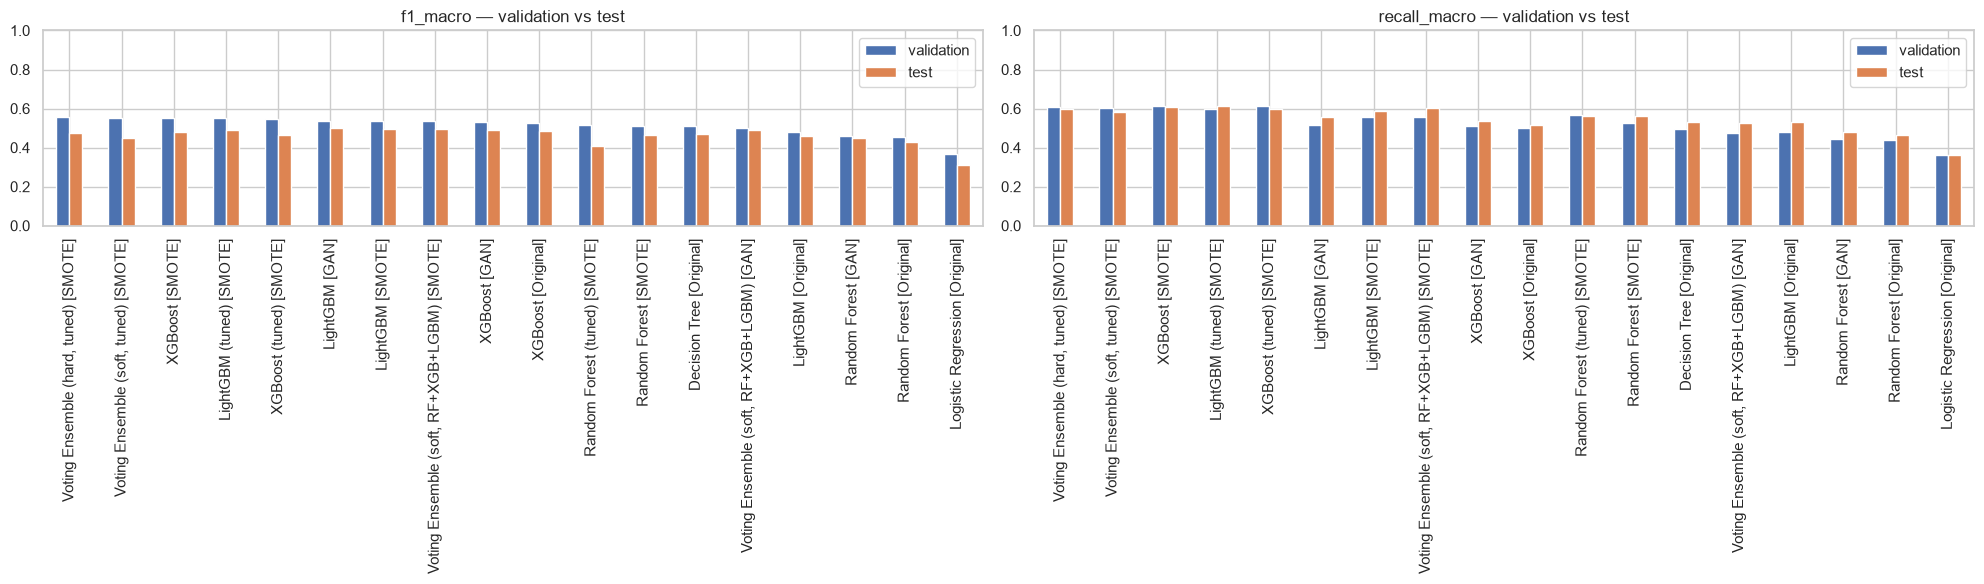

In [86]:
order = val_table.sort_values("f1_macro", ascending=False).index
fig, axes = plt.subplots(1, 2, figsize=(20, 6))
for ax, metric in zip(axes, ["f1_macro", "recall_macro"]):
    pd.DataFrame({"validation": val_table.loc[order, metric], "test": test_table.loc[order, metric]}).plot(
        kind="bar", ax=ax, title=f"{metric} — validation vs test")
    ax.set_ylim(0, 1); ax.tick_params(axis="x", rotation=90)
plt.tight_layout(); plt.show()

In [87]:
criteria = val_table.loc[proba_capable, ["recall_macro", "f1_macro", "macro_fpr", "minority_f1",
                                         "normal_false_alarm_rate", "attack_miss_rate"]]
ranks = pd.DataFrame({
    "recall_macro": criteria["recall_macro"].rank(ascending=False),
    "f1_macro": criteria["f1_macro"].rank(ascending=False),
    "minority_f1": criteria["minority_f1"].rank(ascending=False),
    "macro_fpr": criteria["macro_fpr"].rank(ascending=True),
})
selection_df = criteria.assign(avg_rank=ranks.mean(axis=1)).sort_values(["avg_rank", "f1_macro"], ascending=[True, False])
selection_df.round(4).head(10)

,recall_macro,f1_macro,macro_fpr,minority_f1,normal_false_alarm_rate,attack_miss_rate,avg_rank
"Voting Ensemble (soft, tuned) [SMOTE]",0.6008,0.5513,0.0242,0.3761,0.0939,0.0660,1.75
XGBoost [SMOTE],0.6134,0.5501,0.0245,0.3762,0.0914,0.0707,2.00
LightGBM (tuned) [SMOTE],0.5980,0.5501,0.0242,0.3744,0.0892,0.0694,3.00
XGBoost (tuned) [SMOTE],0.6124,0.5487,0.0245,0.3738,0.0956,0.0671,3.25
LightGBM [SMOTE],0.5557,0.5355,0.0247,0.3539,0.0849,0.0740,6.25
"Voting Ensemble (soft, RF+XGB+LGBM) [SMOTE]",0.5552,0.5352,0.0247,0.3527,0.0888,0.0705,6.75
LightGBM [GAN],0.5141,0.5371,0.0252,0.3661,0.0859,0.0797,7.00
XGBoost [GAN],0.5111,0.5326,0.0249,0.3567,0.0830,0.0813,7.75
XGBoost [Original],0.4985,0.5261,0.0250,0.3495,0.0817,0.0828,9.25
Random Forest (tuned) [SMOTE],0.5647,0.5161,0.0253,0.3268,0.1045,0.0574,9.25


In [88]:
final_model_name = selection_df.index[0]
final_model = fitted_models[final_model_name]
final_strategy = model_meta[final_model_name]["strategy"]
print("Selected final model:", final_model_name, f"(trained on the {final_strategy} training set)")
print(selection_df.loc[final_model_name].round(4).to_string())

Selected final model: Voting Ensemble (soft, tuned) [SMOTE] (trained on the SMOTE training set)
recall_macro               0.6008
f1_macro                   0.5513
macro_fpr                  0.0242
minority_f1                0.3761
normal_false_alarm_rate    0.0939
attack_miss_rate           0.0660
avg_rank                   1.7500


=== Voting Ensemble (soft, tuned) [SMOTE] — UNSW-NB15 official test set ===
                precision    recall  f1-score   support

      Analysis      0.061     0.552     0.110       677
      Backdoor      0.062     0.400     0.108       583
           DoS      0.397     0.074     0.125      4089
      Exploits      0.794     0.618     0.696     11132
       Fuzzers      0.332     0.585     0.423      6062
       Generic      0.973     0.972     0.972     18871
        Normal      0.948     0.747     0.836     37000
Reconnaissance      0.898     0.473     0.620      3496
     Shellcode      0.124     0.791     0.214       378
         Worms      0.260     0.614     0.365        44

      accuracy                          0.720     82332
     macro avg      0.485     0.583     0.447     82332
  weighted avg      0.841     0.720     0.759     82332



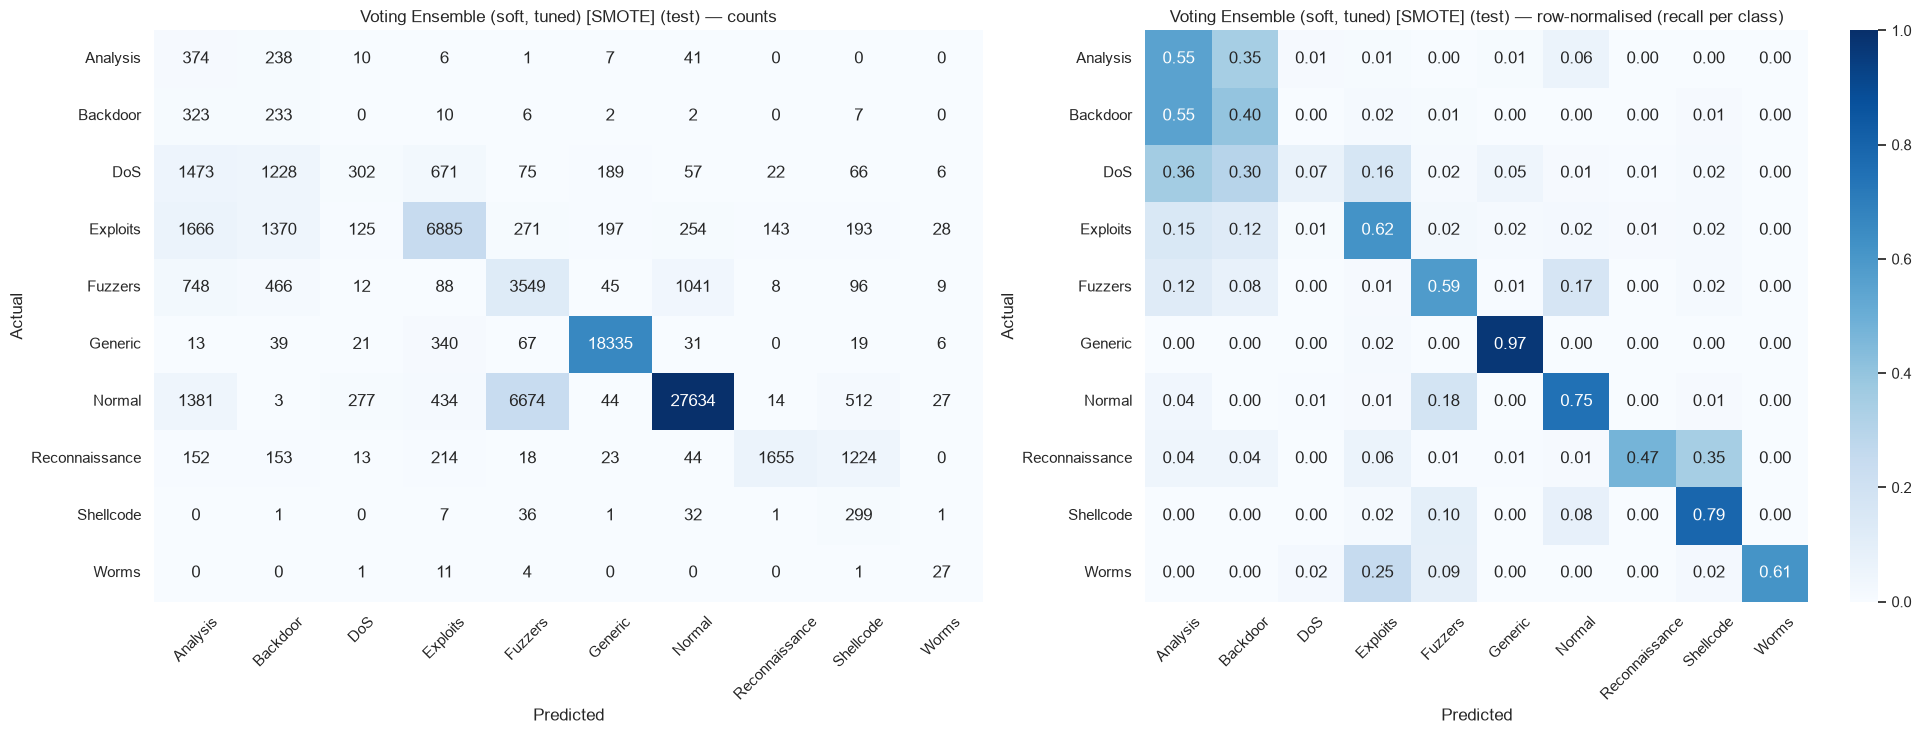

In [89]:
# Test-set behaviour of the selected model
y_test_pred = final_model.predict(X_test_sel)
y_test_proba = final_model.predict_proba(X_test_sel)

print(f"=== {final_model_name} — UNSW-NB15 official test set ===")
print(classification_report(y_test_arr, y_test_pred, target_names=class_names, zero_division=0, digits=3))
plot_confusion(y_test_arr, y_test_pred, f"{final_model_name} (test)")

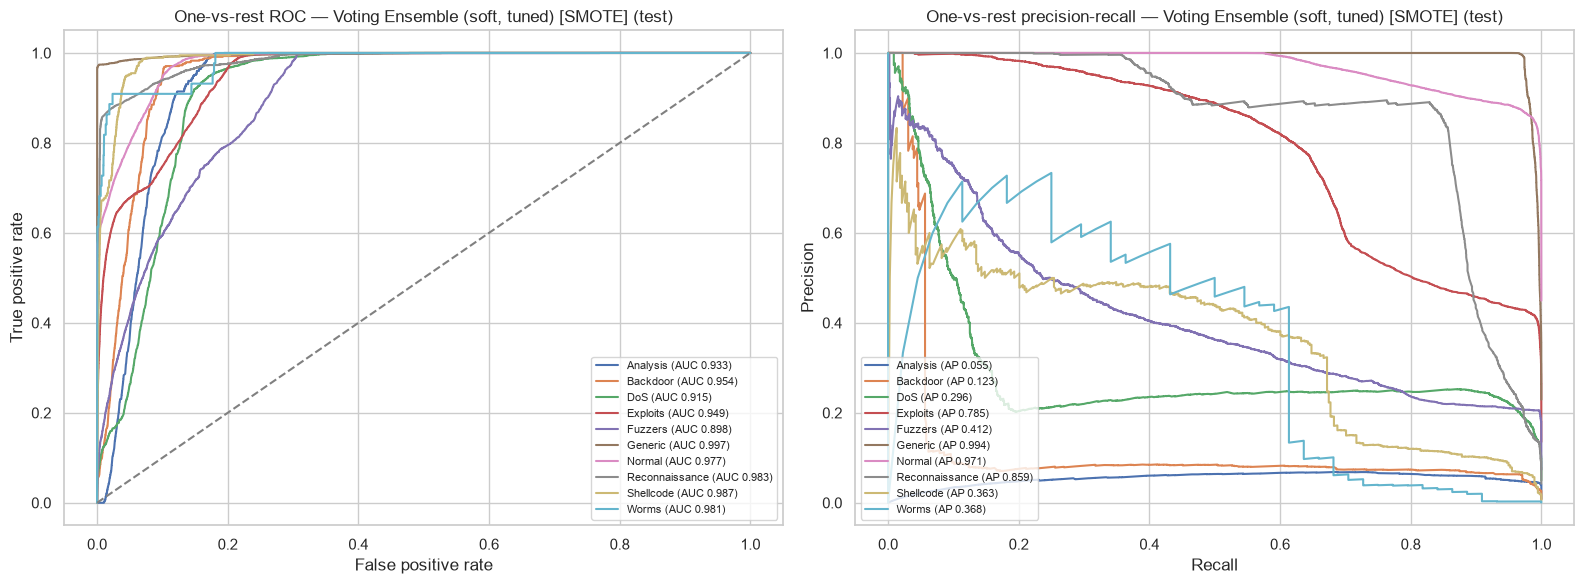

In [90]:
plot_curves(y_test_arr, y_test_proba, f"{final_model_name} (test)")

## 28. Save Final Model

Saved to `artifacts_unsw_multiclass/`:

| File | Content |
|---|---|
| `final_model_unsw_multiclass.joblib` | the selected classifier (**Model**) |
| `scaler_unsw_multiclass.joblib` | fitted `StandardScaler` (**Scaler**) |
| `label_encoder_unsw_multiclass.joblib` | `LabelEncoder` (class index ↔ attack name) (**Encoder**) |
| `preprocessing_unsw_multiclass.joblib` | everything needed to turn raw flows into model input: categorical/numeric columns, the one-hot column list, selected-feature indices and names, training medians |
| `metadata_unsw_multiclass.json` | model name, balancing strategy, classes, validation and test metrics |

Oversampling (SMOTE / GAN) only affects training, so inference needs no GAN or SMOTE object.

In [91]:
ARTIFACT_DIR = Path("artifacts_unsw_multiclass")
ARTIFACT_DIR.mkdir(exist_ok=True)

preprocessing = {
    "drop_cols": drop_cols,
    "raw_feature_order": X.columns.tolist(),
    "categorical_cols": categorical_cols,
    "numerical_cols": numerical_cols,
    "ohe_columns": ohe_columns,
    "selected_idx": keep_idx,
    "selected_features": feature_columns_selected,
    "train_medians": train_medians.to_dict(),
    "class_names": class_names,
}

joblib.dump(final_model, ARTIFACT_DIR / "final_model_unsw_multiclass.joblib", compress=3)
joblib.dump(scaler, ARTIFACT_DIR / "scaler_unsw_multiclass.joblib")
joblib.dump(target_encoder, ARTIFACT_DIR / "label_encoder_unsw_multiclass.joblib")
joblib.dump(preprocessing, ARTIFACT_DIR / "preprocessing_unsw_multiclass.joblib")

metadata = {
    "final_model": final_model_name,
    "balancing_strategy": final_strategy,
    "classes": class_names,
    "n_features_raw": len(X.columns),
    "n_features_encoded": len(ohe_columns),
    "n_features_selected": len(feature_columns_selected),
    "validation_metrics": {k: float(v) for k, v in val_results[final_model_name].items()},
    "test_metrics": {k: float(v) for k, v in test_results[final_model_name].items()},
}
(ARTIFACT_DIR / "metadata_unsw_multiclass.json").write_text(json.dumps(metadata, indent=2))

for f in sorted(ARTIFACT_DIR.iterdir()):
    print(f"{f.name:45s} {f.stat().st_size / 1e6:8.2f} MB")

final_model_unsw_multiclass.joblib              118.08 MB
label_encoder_unsw_multiclass.joblib              0.00 MB
metadata_unsw_multiclass.json                     0.00 MB
preprocessing_unsw_multiclass.joblib              0.01 MB
scaler_unsw_multiclass.joblib                     0.01 MB


In [92]:
# Reload from disk and check that raw traffic -> prediction reproduces the in-memory results exactly
def predict_attack_category(raw_df, artifact_dir=ARTIFACT_DIR):
    model = joblib.load(artifact_dir / "final_model_unsw_multiclass.joblib")
    scaler_ = joblib.load(artifact_dir / "scaler_unsw_multiclass.joblib")
    enc = joblib.load(artifact_dir / "label_encoder_unsw_multiclass.joblib")
    pp = joblib.load(artifact_dir / "preprocessing_unsw_multiclass.joblib")

    df = raw_df.drop(columns=[c for c in pp["drop_cols"] if c in raw_df.columns])[pp["raw_feature_order"]].copy()
    for c in pp["categorical_cols"]:
        df[c] = df[c].astype(str).str.strip()
    df[pp["numerical_cols"]] = (df[pp["numerical_cols"]].replace([np.inf, -np.inf], np.nan)
                                .fillna(pd.Series(pp["train_medians"])))
    df = pd.get_dummies(df, columns=pp["categorical_cols"], dtype=float).reindex(columns=pp["ohe_columns"], fill_value=0.0)

    X_new = scaler_.transform(df)[:, pp["selected_idx"]]
    proba = model.predict_proba(X_new)
    return pd.DataFrame({"predicted_category": enc.inverse_transform(proba.argmax(axis=1)),
                         "confidence": proba.max(axis=1)}, index=raw_df.index)

demo = predict_attack_category(test_df.head(2000))
in_memory = target_encoder.inverse_transform(final_model.predict(X_test_sel[:2000]))
print("Reloaded pipeline matches in-memory predictions:", bool((demo["predicted_category"].to_numpy() == in_memory).all()))
pd.concat([test_df[TARGET_COL].head(8).rename("actual"), demo.head(8)], axis=1)

Reloaded pipeline matches in-memory predictions: True


,actual,predicted_category,confidence
0,Normal,Shellcode,0.708538
1,Normal,Fuzzers,0.453573
2,Normal,Fuzzers,0.379603
3,Normal,Fuzzers,0.518524
4,Normal,Fuzzers,0.583618
5,Normal,Fuzzers,0.545883
6,Normal,Fuzzers,0.584052
7,Normal,Generic,0.335497


## 29. Final Results & Conclusion

In [93]:
print("=== FINAL SUMMARY ===")
print(f"Final model : {final_model_name}")
print(f"Balancing   : {final_strategy}")
print(f"Classes     : {n_classes} ({', '.join(class_names)})")
print(f"Features    : {len(feature_columns_selected)} of {len(feature_columns)} encoded features kept\n")

pd.DataFrame({"validation": val_results[final_model_name], "test": test_results[final_model_name]}).round(4)

=== FINAL SUMMARY ===
Final model : Voting Ensemble (soft, tuned) [SMOTE]
Balancing   : SMOTE
Classes     : 10 (Analysis, Backdoor, DoS, Exploits, Fuzzers, Generic, Normal, Reconnaissance, Shellcode, Worms)
Features    : 176 of 186 encoded features kept



,validation,test
accuracy,0.8090,0.7202
precision_macro,0.5712,0.4849
recall_macro,0.6008,0.5826
f1_macro,0.5513,0.4468
f1_weighted,0.8168,0.7590
roc_auc_ovr,0.9707,0.9574
pr_auc_macro,0.5826,0.5227
minority_f1,0.3761,0.3156
macro_fpr,0.0242,0.0308
normal_false_alarm_rate,0.0939,0.2531


In [94]:
# Where does the final model struggle? Per-class results on the test set, weakest first
final_per_class = per_class_table(y_test_arr, y_test_pred, y_test_proba)
final_per_class.sort_values("f1").round(3)

,precision,recall,f1,support,fpr,most_confused_with,roc_auc,avg_precision
Backdoor,0.062,0.400,0.108,583,0.043,Analysis,0.954,0.123
Analysis,0.061,0.552,0.110,677,0.070,Backdoor,0.933,0.055
DoS,0.397,0.074,0.125,4089,0.006,Analysis,0.915,0.296
Shellcode,0.124,0.791,0.214,378,0.026,Fuzzers,0.987,0.363
Worms,0.260,0.614,0.365,44,0.001,Exploits,0.981,0.368
Fuzzers,0.332,0.585,0.423,6062,0.094,Normal,0.898,0.412
Reconnaissance,0.898,0.473,0.620,3496,0.002,Shellcode,0.983,0.859
Exploits,0.794,0.618,0.696,11132,0.025,Analysis,0.949,0.785
Normal,0.948,0.747,0.836,37000,0.033,Fuzzers,0.977,0.971
Generic,0.973,0.972,0.972,18871,0.008,Exploits,0.997,0.994


In [95]:
# Findings generated from THIS run's numbers (nothing below is hard-coded)
def describe(table_name, s):
    best_f1, best_min = s["f1_macro"].idxmax(), s["minority_f1"].idxmax()
    print(f"[{table_name}] highest mean macro-F1: {best_f1} ({s.loc[best_f1, 'f1_macro']:.4f}); "
          f"highest mean minority-class F1: {best_min} ({s.loc[best_min, 'minority_f1']:.4f})")
    for strat in ["SMOTE", "GAN"]:
        print(f"    {strat:5s} vs Original: macro-F1 {s.loc[strat, 'f1_macro'] - s.loc['Original', 'f1_macro']:+.4f} | "
              f"minority-F1 {s.loc[strat, 'minority_f1'] - s.loc['Original', 'minority_f1']:+.4f} | "
              f"macro-FPR {s.loc[strat, 'macro_fpr'] - s.loc['Original', 'macro_fpr']:+.4f}")
    print(f"    GAN   vs SMOTE   : macro-F1 {s.loc['GAN', 'f1_macro'] - s.loc['SMOTE', 'f1_macro']:+.4f} | "
          f"minority-F1 {s.loc['GAN', 'minority_f1'] - s.loc['SMOTE', 'minority_f1']:+.4f}")

describe("validation, mean of RF/XGB/LGBM", strategy_summary_val)
describe("test,       mean of RF/XGB/LGBM", strategy_summary_test)
print(f"\nSelected model: {final_model_name} | test macro-F1 {test_results[final_model_name]['f1_macro']:.4f} "
      f"vs test accuracy {test_results[final_model_name]['accuracy']:.4f}")
weakest = final_per_class["f1"].sort_values().head(3)
print("Weakest classes on the test set:", ", ".join(f"{c} (F1 {v:.2f})" for c, v in weakest.items()))

[validation, mean of RF/XGB/LGBM] highest mean macro-F1: SMOTE (0.5326); highest mean minority-class F1: SMOTE (0.3535)
    SMOTE vs Original: macro-F1 +0.0462 | minority-F1 +0.0620 | macro-FPR -0.0016
    GAN   vs Original: macro-F1 +0.0226 | minority-F1 +0.0308 | macro-FPR -0.0010
    GAN   vs SMOTE   : macro-F1 -0.0236 | minority-F1 -0.0312
[test,       mean of RF/XGB/LGBM] highest mean macro-F1: GAN (0.4799); highest mean minority-class F1: GAN (0.3500)
    SMOTE vs Original: macro-F1 +0.0219 | minority-F1 +0.0123 | macro-FPR +0.0007
    GAN   vs Original: macro-F1 +0.0228 | minority-F1 +0.0242 | macro-FPR -0.0009
    GAN   vs SMOTE   : macro-F1 +0.0009 | minority-F1 +0.0118

Selected model: Voting Ensemble (soft, tuned) [SMOTE] | test macro-F1 0.4468 vs test accuracy 0.7202
Weakest classes on the test set: Backdoor (F1 0.11), Analysis (F1 0.11), DoS (F1 0.12)


### Conclusion

**What was done.** The binary-classification workflow was extended to the 10-class UNSW-NB15 problem (`Normal` + 9 attack categories) and combined with GAN-based oversampling in a single pipeline.
After one-hot encoding, standardisation and correlation/importance-based feature pruning, three training sets were built — **Original**, **SMOTE-balanced** and **GAN-balanced** (one WGAN-GP per minority class, same target size as SMOTE) — and
Random Forest, XGBoost and LightGBM (plus Logistic Regression and a Decision Tree on the original data) were trained on each. The best balancing strategy was then used to tune RF / XGBoost / LightGBM and to build hard- and soft-voting ensembles.
The final model was chosen from **validation** results by average rank over macro-recall, macro-F1, macro false-positive rate and minority-class F1 — not by accuracy — and the official test set was used for reporting only.

**How to read the results.**
- The generated summary above states, from this run's numbers, whether SMOTE or GAN helped minority classes and at what cost in false positives. Judge the balancing strategies on `minority_f1`, `recall_macro` and per-class F1 (Step 25), not on accuracy, which the large classes dominate.
- The real-vs-synthetic AUC and mean/std gaps (Step 17.5) tell you whether the GAN data are trustworthy: a class whose synthetic rows are trivially separable from real ones is unlikely to help much.
- Compare macro-F1 with accuracy. A large gap means the model is good on big classes (`Normal`, `Generic`, `Exploits`, `Fuzzers`) and weak on small ones. In UNSW-NB15 the usual trouble spots are `Analysis`, `Backdoor` and `DoS`
  (their traffic overlaps heavily with `Exploits`/`Normal`) and `Worms` (only ~100 training rows even before splitting).
- Test scores are expected to be lower than validation scores: the official test file has a different class mix from the training file, so validation is a random slice of the training distribution while test measures generalisation under shift.

**Caveats.**
- Duplicates are removed from the training set only (Step 05.2). This makes validation scores more honest but shrinks the training set and changes its class balance, so numbers are not directly comparable with papers that keep duplicates.
- SMOTE interpolates between one-hot columns (fractional dummies); the GAN rows are snapped back to valid 0/1 values. `SMOTENC` is the stricter SMOTE alternative.
- A GAN trained on very few real rows (e.g. `Worms`) can memorise or under-cover the real class. Its output is limited by 2 000 iterations per class here; raise `GAN_ITERS` and re-check Step 17.5 for a final run. A conditional GAN, or GANs with oversampled batches, are natural extensions.
- Hyper-parameters were searched on a subsample with small grids, and with SMOTE inside the CV folds even when the GAN strategy is chosen; widen the search spaces and raise `TUNE_N` for a production run.
- `TUNED_STRATEGY` is chosen from validation scores; because the same validation split also selects the final model, treat validation numbers as slightly optimistic and rely on the test set for the unbiased estimate.
- SHAP was computed on a stratified sample (`SHAP_PER_CLASS` per class) with the tuned Random Forest; raise it for smoother plots.

**Reproducing predictions.** `predict_attack_category(raw_df)` (Step 28) loads the saved model, scaler, label encoder and preprocessing bundle and returns the predicted category and confidence for raw UNSW-NB15-formatted flows.